Cell 1 - Imports

In [34]:
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import gc, json, pickle, contextlib, time, warnings, random, copy, hashlib, re, math
from collections import Counter, defaultdict
from tqdm import tqdm
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch_geometric.data import Batch
from torch_geometric.nn import GATConv, GlobalAttention, global_mean_pool
from torch.cuda.amp import GradScaler
from sklearn.metrics import (f1_score, confusion_matrix,
                             roc_auc_score, average_precision_score)
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark        = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32       = True
torch.set_float32_matmul_precision('high')

Cell 2 - Config (BYOL)

In [35]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

SSL_METHODS_TO_RUN = ['byol']
DATASETS_TO_RUN    = ['gotham', 'nf_bot', 'nf_ton']

FINE_TUNE_ENCODER = True
RUN_SINGLE_SEED   = True
RUN_FEWSHOT       = False
RUN_ENSEMBLE      = False

ENCODER_LR_MULT   = 0.05
MAIN_SELECTION_METRIC = 'roc'

HIDDEN_DIM        = 128
NUM_HEADS         = 4
NUM_LAYERS        = 3
SEQUENCE_LENGTH   = 3
SEQUENCE_STRIDE   = 1
TFT_HIDDEN_DIM    = 384
TFT_NUM_HEADS     = 2
TFT_DROPOUT       = 0.10

BATCH_SIZE        = 16
GRAD_ACCUM_STEPS  = 1
LEARNING_RATE     = 2e-3
WEIGHT_DECAY      = 3e-4
EPOCHS            = 60
PATIENCE          = 20
WARMUP_EPOCHS     = 8
BASE_LR       = 3e-4
BASE_BS       = 128
FOCAL_ALPHA       = 0.25
FOCAL_GAMMA       = 2.0
POS_WEIGHT        = 1.0

MAX_NODES = 128
MAX_EDGES = 1000

ENFORCE_MAX_WINDOW_GAP   = True
DEFAULT_MAX_WINDOW_GAP_S = 60
RESUME_FROM_PARTIALS = True
USE_TORCH_COMPILE = False
USE_PRIOR_MATCHED_THRESHOLD = False

NUM_WORKERS       = 0
PREFETCH_FACTOR   = 2

BOOTSTRAP_N       = 1000
BOOTSTRAP_SEED    = 123
SEED              = 42

ENSEMBLE_SEEDS_DEFAULT = [1337, 2024, 7]

USE_BALANCED_SAMPLER_PER_DATASET = {
    'gotham':  True,
    'nf_bot':  True,
    'nf_ton':  True,
}

SMALL_LABEL_THRESHOLD  = 300
FEWSHOT_WARMUP_SMALL   = 2
FEWSHOT_PATIENCE_SMALL = 6
FEWSHOT_EPOCHS = 40
FEWSHOT_WARMUP = 5
FRACTIONS = [0.05, 0.25, 0.50, 1.00]

ENSEMBLE_VERBOSE = True

CKPT_EVERY_N_STEPS     = 512
KEEP_LAST_N_PARTIALS   = 5
EMPTY_CACHE_EACH_EPOCH = True

DATASET_THRESHOLDS = {'gotham': 0, 'nf_ton': 0, 'nf_bot': 0}
BLACKLIST_CLASSES = {'Unknown', 'unknown', 'UNKNOWN'}

AUTOCAST_DTYPE   = 'bf16'
SKIP_NONFINITE_STEPS = True
SANITIZE_GRAPH_EMB = True
SANITIZE_FROZEN_CACHE = True
LR_WARMUP_ENABLED = True

torch.manual_seed(SEED); np.random.seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

print(f"Device: {DEVICE}")
print(f"SSL methods : {SSL_METHODS_TO_RUN}")
print(f"Default mode: {'FINE-TUNE end-to-end' if FINE_TUNE_ENCODER else 'FROZEN'}")
print(f"Run toggles: single_seed={RUN_SINGLE_SEED}  fewshot={RUN_FEWSHOT}  ensemble={RUN_ENSEMBLE}")
print(f"Default head: hidden={TFT_HIDDEN_DIM}  heads={TFT_NUM_HEADS}  dropout={TFT_DROPOUT}  seq={SEQUENCE_LENGTH}")
print(f"Default optim: lr={LEARNING_RATE} bs={BATCH_SIZE} accum={GRAD_ACCUM_STEPS} epochs={EPOCHS} patience={PATIENCE}")
print(f"Caps: MAX_NODES={MAX_NODES}  MAX_EDGES={MAX_EDGES}")
print(f"Seeds: single={SEED}  ensemble={ENSEMBLE_SEEDS_DEFAULT}")
print(f"Autocast dtype: {AUTOCAST_DTYPE}  | LR warmup: {LR_WARMUP_ENABLED}  | sanitize emb: {SANITIZE_GRAPH_EMB}")

Device: cuda
SSL methods : ['byol']
Default mode: FINE-TUNE end-to-end
Run toggles: single_seed=True  fewshot=False  ensemble=False
Default head: hidden=384  heads=2  dropout=0.1  seq=3
Default optim: lr=0.002 bs=16 accum=1 epochs=60 patience=20
Caps: MAX_NODES=128  MAX_EDGES=1000
Seeds: single=42  ensemble=[1337, 2024, 7]
Autocast dtype: bf16  | LR warmup: True  | sanitize emb: True


Cell 2b - Run-mode helpers + override_config

In [36]:
def set_run_mode(finetune=None, single_seed=None, fewshot=None, ensemble=None):
    global FINE_TUNE_ENCODER, RUN_SINGLE_SEED, RUN_FEWSHOT, RUN_ENSEMBLE
    if finetune    is not None: FINE_TUNE_ENCODER = bool(finetune)
    if single_seed is not None: RUN_SINGLE_SEED   = bool(single_seed)
    if fewshot     is not None: RUN_FEWSHOT       = bool(fewshot)
    if ensemble    is not None: RUN_ENSEMBLE      = bool(ensemble)
    mode = "finetune" if FINE_TUNE_ENCODER else "frozen"
    print(f"[run-mode] encoder={mode}  single_seed={RUN_SINGLE_SEED}  "
          f"fewshot={RUN_FEWSHOT}  ensemble={RUN_ENSEMBLE}")


def get_run_mode():
    return dict(finetune=FINE_TUNE_ENCODER,
                single_seed=RUN_SINGLE_SEED,
                fewshot=RUN_FEWSHOT,
                ensemble=RUN_ENSEMBLE)


def run_stage(ds, ssl, finetune=None, single_seed=None, fewshot=None, ensemble=None,
              force_retrain=False):
    set_run_mode(finetune=finetune, single_seed=single_seed,
                 fewshot=fewshot, ensemble=ensemble)
    global ALL_RESULTS
    if 'ALL_RESULTS' not in globals() or not isinstance(ALL_RESULTS, dict):
        ALL_RESULTS = {}
    ALL_RESULTS.setdefault(ds, {})
    try:
        ALL_RESULTS[ds][ssl] = run_dataset(ds, ssl, force_retrain=force_retrain)
    except Exception as e:
        import traceback; traceback.print_exc()
        print(f"!!! FAILED on {ds}/{ssl}: {e}")
        ALL_RESULTS[ds][ssl] = {'error': str(e), 'dataset': ds, 'ssl_method': ssl}
        gc.collect()
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
    return ALL_RESULTS[ds][ssl]


class _OverrideConfig:
    def __init__(self, **overrides):
        self.overrides = overrides
        self._saved = {}
        self._added = []
    def __enter__(self):
        g = globals()
        for k, v in self.overrides.items():
            if k in g: self._saved[k] = g[k]
            else:      self._added.append(k)
            g[k] = v
        return self
    def __exit__(self, exc_type, exc_val, exc_tb):
        g = globals()
        for k, v in self._saved.items(): g[k] = v
        for k in self._added:            g.pop(k, None)
        return False


def override_config(**overrides):
    return _OverrideConfig(**overrides)


print("[default] " + str(get_run_mode()))
print("Helpers ready: set_run_mode / run_stage / override_config")

[default] {'finetune': True, 'single_seed': True, 'fewshot': False, 'ensemble': False}
Helpers ready: set_run_mode / run_stage / override_config


Cell 3 - Dataset registry + autocast

In [37]:
DATASET_CONFIG = {
    'gotham':  'Gotham_processed_features_10s/graphs',
    'nf_bot':  'NFBoTIoT_v3_10s/graphs',
    'nf_ton':  'NFToNIoT_v3_10s/graphs',
}


def autocast_ctx():
    if DEVICE.type != 'cuda' or AUTOCAST_DTYPE == 'off':
        return contextlib.nullcontext()
    dtype = torch.bfloat16 if AUTOCAST_DTYPE == 'bf16' else torch.float16
    try:
        return torch.amp.autocast(device_type='cuda', dtype=dtype)
    except Exception:
        if dtype is torch.bfloat16:
            return contextlib.nullcontext()
        return torch.cuda.amp.autocast(enabled=True)


def sanitize_tensor(t, nan=0.0, posinf=1e4, neginf=-1e4):
    if t is None:
        return None
    if not torch.isfinite(t).all():
        t = torch.nan_to_num(t, nan=nan, posinf=posinf, neginf=neginf)
    return t


print(f"autocast_ctx ready  (dtype={AUTOCAST_DTYPE})")

autocast_ctx ready  (dtype=bf16)


Cell 4 - Graph utilities

In [38]:
def cap_graph(g, max_nodes=MAX_NODES, max_edges=MAX_EDGES):
    g = g.clone(); num_nodes = g.num_nodes
    if g.edge_index.size(1) > max_edges:
        keep = torch.randperm(g.edge_index.size(1))[:max_edges]
        g.edge_index = g.edge_index[:, keep]
        if g.edge_attr is not None and g.edge_attr.size(0) > 0:
            if g.edge_attr.dim() > 2:
                g.edge_attr = g.edge_attr.view(-1, g.edge_attr.size(-1))
            g.edge_attr = g.edge_attr[keep]
    if num_nodes > max_nodes:
        deg = torch.zeros(num_nodes, dtype=torch.long)
        deg.scatter_add_(0, g.edge_index[0],
                         torch.ones(g.edge_index.size(1), dtype=torch.long))
        kn = torch.topk(deg, max_nodes).indices
        mask = torch.zeros(num_nodes, dtype=torch.bool); mask[kn] = True
        s, d = g.edge_index; keep_e = mask[s] & mask[d]
        g.edge_index = g.edge_index[:, keep_e]
        if g.edge_attr is not None and g.edge_attr.size(0) > 0:
            g.edge_attr = g.edge_attr[keep_e]
        remap = torch.zeros(num_nodes, dtype=torch.long)
        remap[mask] = torch.arange(max_nodes, dtype=torch.long)
        g.edge_index = remap[g.edge_index]; g.x = g.x[mask]
    return g


def dominant_family(g, attack_threshold=0.15,
                    blacklist=('Unknown', 'unknown', 'UNKNOWN')):
    names = getattr(g, 'edge_attack_names', None)
    if not names: return 'Benign'
    c = Counter(names); total = sum(c.values())
    atk = {k: v for k, v in c.items() if k != 'Benign' and k not in blacklist}
    if not atk: return 'Benign'
    if sum(atk.values()) / max(total, 1) < attack_threshold: return 'Benign'
    return max(atk, key=atk.get)


def build_gap_aware_starts(graphs, seq_len, stride, max_gap_sec,
                           enforce=True, verbose=True):
    n = len(graphs)
    if n < seq_len:
        return np.array([], dtype=np.int64)
    stride_only = np.arange(0, n - seq_len + 1, stride, dtype=np.int64)
    if not enforce:
        return stride_only
    has_time = hasattr(graphs[0], 'window_start_unix')
    if not has_time:
        if verbose:
            print("  [gap] graphs lack .window_start_unix - gap check skipped")
        return stride_only
    times = np.array([float(g.window_start_unix) for g in graphs], dtype=np.float64)
    gaps = np.diff(times)
    ok_adj = (gaps <= float(max_gap_sec)).astype(np.int32)
    cum = np.concatenate([[0], np.cumsum(ok_adj)])
    window_sum = cum[stride_only + seq_len - 1] - cum[stride_only]
    keep = window_sum == (seq_len - 1)
    kept = stride_only[keep]
    if verbose:
        n_rejected = int((~keep).sum())
        print(f"  [gap] stride candidates {len(stride_only)}  "
              f"rejected-by-gap {n_rejected}  kept {len(kept)}  "
              f"(max_gap={max_gap_sec}s)")
    if len(kept) < 10 and len(stride_only) >= 10:
        if verbose:
            print(f"  [gap][warn] only {len(kept)} sequences survive - "
                  f"relaxing gap constraint to stride-only")
        return stride_only
    return kept

Cell 5 - Model classes

In [39]:
class GATEncoder(nn.Module):
    def __init__(self, in_ch, hid, heads, layers, edge_dim):
        super().__init__()
        self.convs = nn.ModuleList(); self.bns = nn.ModuleList()
        self.convs.append(GATConv(in_ch, hid, heads=heads, edge_dim=edge_dim,
                                  concat=True, dropout=0.0))
        self.bns.append(nn.BatchNorm1d(hid * heads))
        for _ in range(layers - 2):
            self.convs.append(GATConv(hid * heads, hid, heads=heads,
                                      edge_dim=edge_dim, concat=True, dropout=0.0))
            self.bns.append(nn.BatchNorm1d(hid * heads))
        self.convs.append(GATConv(hid * heads, hid, heads=1, edge_dim=edge_dim,
                                  concat=False, dropout=0.0))
        self.bns.append(nn.BatchNorm1d(hid))
        self.edge_dim = edge_dim
        self.pool_gate = nn.Sequential(
            nn.Linear(hid, hid), nn.ReLU(), nn.Linear(hid, 1))

    def forward(self, x, ei, ea=None, b=None, return_nodes=False):
        for i, c in enumerate(self.convs):
            x = c(x, ei, edge_attr=ea) if (ea is not None and self.edge_dim > 0) \
                else c(x, ei)
            x = F.relu(self.bns[i](x))
        h = GlobalAttention(self.pool_gate)(x, b)
        if return_nodes:
            return x, h
        return h


class GatedResidualNetwork(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, dropout=0.1):
        super().__init__()
        self.fc1  = nn.Linear(input_dim, hidden_dim); self.elu = nn.ELU()
        self.fc2  = nn.Linear(hidden_dim, output_dim); self.drop = nn.Dropout(dropout)
        self.gate = nn.Linear(hidden_dim, output_dim); self.norm = nn.LayerNorm(output_dim)
        self.skip = nn.Linear(input_dim, output_dim) if input_dim != output_dim else None

    def forward(self, x):
        z = self.elu(self.fc1(x))
        h = self.drop(self.fc2(z))
        g = torch.sigmoid(self.gate(z))
        h = g * h
        if self.skip is not None:
            x = self.skip(x)
        return self.norm(x + h)


class VariableSelectionNetwork(nn.Module):
    def __init__(self, var_dims, hidden_dim, dropout=0.1):
        super().__init__()
        self.num_vars = len(var_dims)
        self.var_grns = nn.ModuleList(
            [GatedResidualNetwork(d, hidden_dim, hidden_dim, dropout) for d in var_dims])
        self.weight_grn = GatedResidualNetwork(
            sum(var_dims), hidden_dim, self.num_vars, dropout)

    def forward(self, vars_list):
        processed = [grn(v) for grn, v in zip(self.var_grns, vars_list)]
        flat = torch.cat(vars_list, dim=-1)
        w = F.softmax(self.weight_grn(flat), dim=-1)
        stacked = torch.stack(processed, dim=2)
        return (stacked * w.unsqueeze(-1)).sum(dim=2), w


class InterpretableMHA(nn.Module):
    def __init__(self, hidden_dim, num_heads, dropout=0.1, init_temp=0.05):
        super().__init__()
        self.h = hidden_dim; self.nh = num_heads; self.hd = hidden_dim // num_heads
        assert self.hd * num_heads == hidden_dim
        self.q = nn.Linear(hidden_dim, hidden_dim)
        self.k = nn.Linear(hidden_dim, hidden_dim)
        self.v = nn.Linear(hidden_dim, hidden_dim)
        self.o = nn.Linear(hidden_dim, hidden_dim)
        self.drop = nn.Dropout(dropout)
        # Frozen temperature: keeps attention sharp. A learnable temperature
        # collapses to uniform because the residual path lets the model bypass
        # attention during training.
        self.register_buffer('log_temp', torch.tensor(float(np.log(init_temp))))
        self.min_temp = 0.05
        self.max_temp = 100.0

    def forward_last(self, x):
        """Query from the last position. Returns (context [B,H], attn [B,T]).

        attn is the head-averaged attention at the last query position, shape
        [B, T]. This is what downstream code stores for interpretability.
        """
        B, T, _ = x.shape
        q_last = self.q(x[:, -1:, :]).view(B, 1, self.nh, self.hd).transpose(1, 2)
        k_all  = self.k(x).view(B, T, self.nh, self.hd).transpose(1, 2)
        v_all  = self.v(x).view(B, T, self.nh, self.hd).transpose(1, 2)
        temp   = torch.exp(self.log_temp).clamp(self.min_temp, self.max_temp)
        scale  = 1.0 / ((self.hd ** 0.5) * temp)
        s = torch.matmul(q_last, k_all.transpose(-2, -1)) * scale
        s = torch.nan_to_num(s, nan=-1e4, posinf=1e4, neginf=-1e4)
        s = s - s.amax(dim=-1, keepdim=True).detach()
        s = torch.nan_to_num(s, nan=0.0, posinf=0.0, neginf=-1e4)
        a = self.drop(F.softmax(s, dim=-1))                                          # [B, nh, 1, T]
        c = torch.matmul(a, v_all).transpose(1, 2).contiguous().view(B, 1, self.h)
        context = self.o(c).squeeze(1)                                               # [B, H]
        attn_w  = a.squeeze(2).mean(dim=1)                                           # [B, T]
        return context, attn_w

    def forward(self, x):
        # Kept for backwards compatibility; not used in the fixed TFT path.
        B, T, _ = x.shape
        q = self.q(x).view(B, T, self.nh, self.hd).transpose(1, 2)
        k = self.k(x).view(B, T, self.nh, self.hd).transpose(1, 2)
        v = self.v(x).view(B, T, self.nh, self.hd).transpose(1, 2)
        temp = torch.exp(self.log_temp).clamp(self.min_temp, self.max_temp)
        scale = 1.0 / ((self.hd ** 0.5) * temp)
        s = torch.matmul(q, k.transpose(-2, -1)) * scale
        s = torch.nan_to_num(s, nan=-1e4, posinf=1e4, neginf=-1e4)
        s = s - s.amax(dim=-1, keepdim=True).detach()
        s = torch.nan_to_num(s, nan=0.0, posinf=0.0, neginf=-1e4)
        a = self.drop(F.softmax(s, dim=-1))
        c = torch.matmul(a, v).transpose(1, 2).contiguous().view(B, T, self.h)
        return self.o(c), a.mean(dim=1)


class TemporalFusionModuleV2(nn.Module):
    def __init__(self, graph_emb_dim, struct_dim, hidden_dim, num_heads, dropout=0.1):
        super().__init__()
        self.proj_graph  = nn.Linear(graph_emb_dim, hidden_dim)
        self.proj_struct = nn.Linear(struct_dim, hidden_dim)
        self.vsn  = VariableSelectionNetwork([hidden_dim, hidden_dim], hidden_dim, dropout)
        self.lstm = nn.LSTM(hidden_dim, hidden_dim, num_layers=2,
                            batch_first=True, dropout=dropout)
        self.attn = InterpretableMHA(hidden_dim, num_heads, dropout)
        self.grn1 = GatedResidualNetwork(hidden_dim, hidden_dim, hidden_dim, dropout)
        self.grn2 = GatedResidualNetwork(hidden_dim, hidden_dim, hidden_dim, dropout)
        self.norm = nn.LayerNorm(hidden_dim)

    def forward(self, graph_emb, struct_feats):
        v_g = self.proj_graph(graph_emb); v_s = self.proj_struct(struct_feats)
        selected, vsn_w = self.vsn([v_g, v_s])
        lstm_out, _ = self.lstm(selected)
        attn_last, attn_w = self.attn.forward_last(lstm_out)
        out = self.grn1(attn_last); out = self.grn2(out)
        out = self.norm(selected[:, -1, :] + out)
        return out, attn_w, vsn_w


class MC_STGAT_IDS(nn.Module):
    def __init__(self, graph_emb_dim, struct_dim, tft_hidden, num_classes,
                 num_heads=4, dropout=0.1):
        super().__init__()
        self.temporal = TemporalFusionModuleV2(graph_emb_dim, struct_dim,
                                               tft_hidden, num_heads, dropout)
        self.binary_head = nn.Sequential(
            nn.Linear(tft_hidden, tft_hidden // 2), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(tft_hidden // 2, 1))
        self.multi_head = nn.Sequential(
            nn.Linear(tft_hidden, tft_hidden // 2), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(tft_hidden // 2, num_classes))

    def forward(self, graph_emb, struct_feats):
        temporal_emb, attn_w, vsn_w = self.temporal(graph_emb, struct_feats)
        return (self.binary_head(temporal_emb).squeeze(-1),
                self.multi_head(temporal_emb), attn_w, vsn_w)


class BinaryFocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0, pos_weight=1.0):
        super().__init__()
        self.alpha = alpha; self.gamma = gamma
        self.register_buffer('pos_weight', torch.tensor(float(pos_weight)))
    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction='none',
                                                 pos_weight=self.pos_weight)
        p = torch.sigmoid(logits).clamp(1e-6, 1.0 - 1e-6)
        p_t = p * targets + (1 - p) * (1 - targets)
        return (self.alpha * (1 - p_t) ** self.gamma * bce).mean()


class CombinedLoss(nn.Module):
    def __init__(self, w_multi=0.7, pos_weight=1.5, focal_alpha=0.25, focal_gamma=2.0):
        super().__init__()
        self.w_multi = w_multi
        self.binary_loss = BinaryFocalLoss(focal_alpha, focal_gamma, pos_weight)
        self.focal_alpha = focal_alpha; self.focal_gamma = focal_gamma
    def forward(self, bin_logits, multi_logits, y_bin, y_multi):
        l_bin = self.binary_loss(bin_logits, y_bin)
        logp = F.log_softmax(multi_logits, dim=-1)
        logp_t = logp.gather(1, y_multi.unsqueeze(1)).squeeze(1)
        logp_t = logp_t.clamp_min(-20.0)
        p_t = logp_t.exp().clamp(1e-6, 1.0 - 1e-6)
        l_multi = (-self.focal_alpha * (1 - p_t) ** self.focal_gamma * logp_t).mean()
        return l_bin + self.w_multi * l_multi, l_bin.item(), l_multi.item()

Cell 6 - Sequence dataset + collate

In [40]:
class GraphSequenceDataset(Dataset):
    def __init__(self, graphs, starts, seq_len, y_bin_seq, y_multi_seq, struct_feats):
        self.graphs      = graphs
        self.starts      = np.asarray(starts)
        self.seq_len     = seq_len
        self.y_bin_seq   = y_bin_seq
        self.y_multi_seq = y_multi_seq
        self.struct      = struct_feats
    def __len__(self): return len(self.starts)
    def __getitem__(self, i):
        s = int(self.starts[i]); e = s + self.seq_len
        return (self.graphs[s:e], self.struct[s:e],
                self.y_bin_seq[i], self.y_multi_seq[i])


def collate_graph_sequences(batch):
    seq_graphs_list, seq_struct_list, y_bin_list, y_multi_list = zip(*batch)
    B = len(seq_graphs_list); T = len(seq_graphs_list[0])
    flat_graphs = []
    for seq in seq_graphs_list:
        flat_graphs.extend(seq)
    flat_batch = Batch.from_data_list(flat_graphs)
    struct_tensor = torch.stack(
        [torch.as_tensor(s, dtype=torch.float32) for s in seq_struct_list], dim=0)
    return (flat_batch, B, T, struct_tensor,
            torch.tensor(y_bin_list,   dtype=torch.float32),
            torch.tensor(y_multi_list, dtype=torch.long))

Cell 7 - Structural feature precompute

In [41]:
def structural_features(g):
    x  = g.x.numpy()
    ea = g.edge_attr.numpy() if g.edge_attr is not None else np.zeros((0, 0))
    ei = g.edge_index.numpy()
    N = x.shape[0]; E = ei.shape[1]
    deg = np.bincount(ei[0], minlength=N) if E > 0 else np.zeros(N)
    base = np.array([float(N), float(E),
                     float(deg.mean()) if N > 0 else 0.0,
                     float(np.log1p(E))], dtype=np.float32)
    nm = x.mean(0) if N > 0 else np.zeros(x.shape[1], dtype=np.float32)
    ns = x.std(0)  if N > 0 else np.zeros(x.shape[1], dtype=np.float32)
    em = ea.mean(0) if E > 0 and ea.ndim == 2 else np.zeros(ea.shape[-1] if ea.ndim == 2 else 0,
                                                              dtype=np.float32)
    return np.concatenate([base, nm, ns, em]).astype(np.float32)


def precompute_struct(graphs):
    return torch.tensor(np.stack([structural_features(g) for g in graphs]),
                        dtype=torch.float32)

Cell 7b - Logging, checkpoint, metric helpers

In [42]:
def _signatures():
    enc_sig = hashlib.md5("|".join([
        f"hid={HIDDEN_DIM}",
        f"heads={NUM_HEADS}",
        f"layers={NUM_LAYERS}",
        f"ft={int(FINE_TUNE_ENCODER)}",
    ]).encode()).hexdigest()[:10]

    tft_sig = hashlib.md5("|".join([
        f"enc={enc_sig}",
        f"tft_hid={TFT_HIDDEN_DIM}",
        f"tft_heads={TFT_NUM_HEADS}",
        f"seq={SEQUENCE_LENGTH}",
    ]).encode()).hexdigest()[:10]

    return enc_sig, tft_sig


def _config_signature():
    enc_sig, tft_sig = _signatures()
    return f"{enc_sig}_{tft_sig}"


def _checkpoint_parts_ok(path):
    if not os.path.isfile(path):
        return False, False, False, None
    try:
        sw = torch.load(path, map_location='cpu')
    except Exception:
        return False, False, True, "unreadable"

    s_enc = sw.get('encoder_signature')
    s_tft = sw.get('tft_signature')

    if s_enc is None and s_tft is None:
        old = sw.get('config_signature')
        if old:
            return True, False, True, old
        return False, False, True, None

    enc_sig, tft_sig = _signatures()
    enc_ok = (s_enc == enc_sig) or (not FINE_TUNE_ENCODER)
    tft_ok = (s_tft == tft_sig)
    return enc_ok, tft_ok, True, f"{s_enc}_{s_tft}"


def _safe_load_state_dict(module, sd, strict=False):
    try:
        missing, unexpected = module.load_state_dict(sd, strict=strict)
        return True, f"ok (missing={len(missing)} unexpected={len(unexpected)})"
    except RuntimeError as e:
        first = str(e).splitlines()
        head  = first[0] if first else "RuntimeError"
        return False, head


def _quarantine(path, new_sig=None):
    if not os.path.isfile(path):
        return
    suffix = f".stale_{new_sig}" if new_sig else ".stale"
    dst = path + suffix
    try:
        os.replace(path, dst)
        print(f"  [quarantine] {os.path.basename(path)} -> {os.path.basename(dst)}")
    except OSError as e:
        print(f"  [quarantine] failed to move {path}: {e}")


def _fmt_time(seconds):
    if seconds < 60:
        return f"{seconds:5.1f}s"
    m, s = divmod(seconds, 60)
    return f"{int(m):02d}m{s:04.1f}s"


def _bar(value, width=20, vmin=0.5, vmax=1.0):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return " " * width
    frac = float(np.clip((value - vmin) / max(vmax - vmin, 1e-9), 0.0, 1.0))
    n = int(round(frac * width))
    return "#" * n + "." * (width - n)


def _print_epoch_header(tag, total_epochs):
    print(f"  {'ep':>4}  {'train':>8}  {'bin':>7}  {'multi':>7}  "
          f"{'gnorm':>7}  {'lr':>9}  |  "
          f"{'valROC':>7} {'valPR':>7} {'valF1':>7} {'valmF1':>8}  "
          f"{'ROC bar':<20}  {'time':>7}  {'pat':>3}  note")
    print("  " + "-" * 130)


def _print_epoch_row(ep, total_epochs, tr, val, gnorm, lr,
                     patience_left, best_macro_f1, elapsed, note=""):
    print(f"  {ep:>4}  "
          f"{tr['total']:>8.4f}  {tr['binary']:>7.4f}  {tr['multi']:>7.4f}  "
          f"{gnorm:>7.3f}  {lr:>9.2e}  |  "
          f"{val['roc']:>7.4f} {val['pr']:>7.4f} {val['f1']:>7.4f} "
          f"{val['macro_f1_merged']:>8.4f}  "
          f"{_bar(val['roc']):<20}  "
          f"{_fmt_time(elapsed):>7}  {patience_left:>3}  {note}")


def _optimal_threshold(prob, y):
    thrs = np.linspace(0.05, 0.95, 91)
    best_t, best_f1 = 0.5, -1.0
    for t in thrs:
        f1 = f1_score(y, (prob >= t).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    return float(best_t), float(best_f1)


def _prior_matched_threshold(prob, y):
    target_rate = float(np.asarray(y).mean())
    if target_rate <= 0.0 or target_rate >= 1.0:
        return 0.5
    return float(np.quantile(prob, 1.0 - target_rate))


def _binary_metrics_at(prob, y, thr):
    pred = (prob >= thr).astype(int)
    f1  = float(f1_score(y, pred, average='binary', zero_division=0))
    cm  = confusion_matrix(y, pred, labels=[0, 1])
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    tn, fp = int(cm[0, 0]), int(cm[0, 1])
    fn, tp = int(cm[1, 0]), int(cm[1, 1])
    n_true_benign = tn + fp
    n_true_attack = fn + tp
    n_pred_benign = tn + fn
    n_pred_attack = fp + tp
    n_total       = n_true_benign + n_true_attack
    return {
        'f1':  f1,
        'fpr': float(cmn[0, 1]),
        'fnr': float(cmn[1, 0]),
        'n_true_benign':     n_true_benign,
        'n_true_attack':     n_true_attack,
        'n_total':           n_total,
        'true_benign_rate':  n_true_benign / max(n_total, 1),
        'true_attack_rate':  n_true_attack / max(n_total, 1),
        'n_pred_benign':     n_pred_benign,
        'n_pred_attack':     n_pred_attack,
        'pred_benign_rate':  n_pred_benign / max(n_total, 1),
        'pred_attack_rate':  n_pred_attack / max(n_total, 1),
        'tn_benign_correct': tn,
        'fp_benign_wrong':   fp,
        'fn_attack_missed':  fn,
        'tp_attack_correct': tp,
        'benign_recall':  float(cmn[0, 0]),
        'attack_recall':  float(cmn[1, 1]),
    }


def _per_class_score_analysis(pb_test, test_labels_seq, class_names, thr):
    rows = []
    for cls in class_names:
        if cls == 'Benign':
            continue
        mask = (test_labels_seq == cls) | (test_labels_seq == 'Benign')
        y_sel = (test_labels_seq[mask] != 'Benign').astype(int)
        p_sel = pb_test[mask]
        if len(set(y_sel)) < 2:
            continue
        try:
            roc = float(roc_auc_score(y_sel, p_sel))
            pr  = float(average_precision_score(y_sel, p_sel))
        except ValueError:
            continue
        pos = (y_sel == 1)
        rows.append({
            'class': cls, 'n_test': int(pos.sum()),
            'roc_vs_benign': roc, 'pr_vs_benign': pr,
            'mean_prob_attack': float(p_sel[pos].mean()) if pos.sum() > 0 else 0.0,
            'recall_at_thr': float((p_sel[pos] >= thr).sum() / max(int(pos.sum()), 1)),
            'missed_at_thr': int((p_sel[pos] < thr).sum()),
        })

    y_all    = (test_labels_seq != 'Benign').astype(int)
    n_benign = int((y_all == 0).sum())
    n_attack = int((y_all == 1).sum())
    if n_benign > 0 and n_attack > 0:
        try:
            roc_b = float(roc_auc_score(y_all, pb_test))
            pr_b  = float(average_precision_score(y_all, pb_test))
        except ValueError:
            roc_b, pr_b = float('nan'), float('nan')
        rows.append({
            'class': 'Benign (all-vs-attack)',
            'n_test': n_benign,
            'roc_vs_benign': roc_b,
            'pr_vs_benign':  pr_b,
            'mean_prob_attack': float(pb_test[y_all == 0].mean()),
            'recall_at_thr':   float((pb_test[y_all == 0] <  thr).sum() / max(n_benign, 1)),
            'missed_at_thr':   int((pb_test[y_all == 0] >= thr).sum()),
        })

    rows.sort(key=lambda r: -r['roc_vs_benign'])
    return rows


def _print_per_class_table(rows, thr, title):
    if not rows:
        print(f"  {title}: no rows")
        return
    print(f"\n  {title} - thr={thr:.2f}")
    print(f"  {'class':<28} {'n':>6} {'ROC':>7} {'PR':>7} "
          f"{'meanP':>7} {'recall':>7} {'missed':>7}")
    for r in rows:
        print(f"  {r['class'][:28]:<28} {r['n_test']:>6} "
              f"{r['roc_vs_benign']:>7.4f} {r['pr_vs_benign']:>7.4f} "
              f"{r['mean_prob_attack']:>7.3f} {r['recall_at_thr']:>7.3f} "
              f"{r['missed_at_thr']:>7}")


def _print_binary_confusion(m, label="binary @ threshold"):
    print(f"    [{label}]")
    print(f"      attack : true={m['n_true_attack']:>5}  "
          f"pred={m['n_pred_attack']:>5}  "
          f"correct(TP)={m['tp_attack_correct']:>5}  "
          f"missed(FN)={m['fn_attack_missed']:>5}")
    print(f"      benign : true={m['n_true_benign']:>5}  "
          f"pred={m['n_pred_benign']:>5}  "
          f"correct(TN)={m['tn_benign_correct']:>5}  "
          f"false-alarm(FP)={m['fp_benign_wrong']:>5}")
    print(f"      rates  : true_attack={m['true_attack_rate']:.3f}  "
          f"pred_attack={m['pred_attack_rate']:.3f}  "
          f"FPR={m['fpr']:.4f}  FNR={m['fnr']:.4f}")


def _partial_re(tag):
    return re.compile(rf"^partial_{re.escape(tag)}_e(\d+)_s(\d+)\.pth$")


def _prune_partials(ckpt_dir, tag, keep=5):
    if not os.path.isdir(ckpt_dir):
        return
    pat = _partial_re(tag)
    matched = [f for f in os.listdir(ckpt_dir) if pat.match(f)]
    matched.sort(key=lambda f: tuple(int(x) for x in pat.match(f).groups()))
    to_del = matched if keep <= 0 else matched[:-keep]
    for f in to_del:
        try:
            os.remove(os.path.join(ckpt_dir, f))
        except OSError:
            pass


def _flush_report(out_dir, filename, payload):
    os.makedirs(out_dir, exist_ok=True)
    path = os.path.join(out_dir, filename)
    tmp  = path + ".tmp"
    with open(tmp, 'w') as f:
        json.dump(payload, f, indent=2, default=str)
    os.replace(tmp, path)
    print(f"    [flush] {path}")
    return path


def _encode_sequence(encoder, flat_batch, B, T, device, frozen):
    ctx = torch.no_grad() if frozen else contextlib.nullcontext()
    with ctx:
        flat_batch = flat_batch.to(device, non_blocking=True)
        out = encoder(flat_batch.x, flat_batch.edge_index,
                      flat_batch.edge_attr, flat_batch.batch)
        h = out[-1] if isinstance(out, tuple) else out
        h = h.view(B, T, -1)
        h = h.float()
        if SANITIZE_GRAPH_EMB:
            h = sanitize_tensor(h)
        return h


def _val_metrics(pb_val, pm_val, yb_val, ym_val,
                 thr=0.5, train_visible_idx=None,
                 class_names=None, dataset=None):
    y = yb_val.astype(int)
    pb_val = np.asarray(pb_val, dtype=np.float64)
    if not np.isfinite(pb_val).all():
        pb_val = np.nan_to_num(pb_val, nan=0.0, posinf=1.0, neginf=0.0)
    try: roc = float(roc_auc_score(y, pb_val))
    except ValueError: roc = 0.5
    try: pr = float(average_precision_score(y, pb_val))
    except ValueError: pr = 0.0
    f1_bin = float(f1_score(y, (pb_val >= thr).astype(int),
                            average='binary', zero_division=0))
    ym_pred = pm_val.argmax(-1)
    macro_f1_all = float(f1_score(ym_val, ym_pred, average='macro', zero_division=0))
    weighted_f1  = float(f1_score(ym_val, ym_pred, average='weighted', zero_division=0))
    if train_visible_idx is None or len(train_visible_idx) < 2:
        macro_f1_visible = macro_f1_all
    else:
        mask = np.isin(ym_val, train_visible_idx)
        if mask.sum() < 2 or len(np.unique(ym_val[mask])) < 2:
            macro_f1_visible = macro_f1_all
        else:
            macro_f1_visible = float(f1_score(ym_val[mask], ym_pred[mask],
                                              average='macro', zero_division=0))
    if class_names is None or dataset is None:
        macro_f1_merged = macro_f1_visible
    else:
        ym_val_m  = np.array([(class_names[i], dataset) for i in ym_val])
        ym_pred_m = np.array([(class_names[i], dataset) for i in ym_pred])
        train_fams = sorted({(class_names[i], dataset)
                             for i in (train_visible_idx
                                       if train_visible_idx is not None
                                       else np.unique(ym_val))})
        mask_m = np.isin(ym_val_m, list(train_fams))
        if mask_m.sum() < 2 or len(np.unique(ym_val_m[mask_m])) < 2:
            macro_f1_merged = float(f1_score(ym_val_m, ym_pred_m,
                                             average='macro', zero_division=0))
        else:
            macro_f1_merged = float(f1_score(ym_val_m[mask_m], ym_pred_m[mask_m],
                                             average='macro', zero_division=0))
    return {
        'roc':              roc,
        'pr':               pr,
        'f1':               f1_bin,
        'macro_f1':         macro_f1_all,
        'macro_f1_visible': macro_f1_visible,
        'macro_f1_merged':  macro_f1_merged,
        'weighted_f1':      weighted_f1,
    }


print("Helpers ready.  config_signature =", _config_signature())


_FROZEN_EMB_CACHE = {}


def _frozen_emb_key(ds, ssl):
    enc_path = os.path.join(DATASET_CONFIG[ds],
                            f"ssl_checkpoints_{ssl}",
                            "ssl_encoder_best.pth")
    try:
        enc_mtime = os.path.getmtime(enc_path)
        enc_size  = os.path.getsize(enc_path)
    except OSError:
        enc_mtime, enc_size = -1.0, -1
    return (ds, ssl,
            int(SEQUENCE_LENGTH), int(SEQUENCE_STRIDE),
            bool(ENFORCE_MAX_WINDOW_GAP),
            int(MAX_NODES), int(MAX_EDGES),
            int(HIDDEN_DIM), int(NUM_HEADS), int(NUM_LAYERS),
            float(DATASET_THRESHOLDS.get(ds, 0.0)),
            str(AUTOCAST_DTYPE),
            bool(SANITIZE_FROZEN_CACHE),
            float(enc_mtime), int(enc_size))


def _load_graphs_for_embcache(ds):
    DATA_DIR = DATASET_CONFIG[ds]
    atk_thr  = DATASET_THRESHOLDS[ds]

    def _load(split):
        with open(os.path.join(DATA_DIR, f"{split}_graphs.pkl"), 'rb') as f:
            return pickle.load(f)

    tg = [cap_graph(g) for g in _load('train')]
    vg = [cap_graph(g) for g in _load('val')]
    eg = [cap_graph(g) for g in _load('test')]

    with open(os.path.join(DATA_DIR, 'norm_stats.json')) as f:
        ns = json.load(f)
    N_CONT    = ns['n_continuous_edge_feats']
    node_mean = torch.tensor(ns['node_mean'], dtype=torch.float)
    node_std  = torch.tensor(ns['node_std'],  dtype=torch.float)
    edge_mean = torch.tensor(ns['edge_mean'], dtype=torch.float)
    edge_std  = torch.tensor(ns['edge_std'],  dtype=torch.float)
    MWG = float(ns.get('max_window_gap_sec', DEFAULT_MAX_WINDOW_GAP_S))

    def _norm(graphs):
        for g in graphs:
            g.x = torch.clamp((g.x - node_mean) / (node_std + 1e-8), -10, 10)
            if g.edge_attr is not None and g.edge_attr.size(0) > 0:
                if g.edge_attr.dim() > 2:
                    g.edge_attr = g.edge_attr.view(-1, g.edge_attr.size(-1))
                c, p = g.edge_attr[:, :N_CONT], g.edge_attr[:, N_CONT:]
                c = torch.clamp((c - edge_mean) / (edge_std + 1e-8), -10, 10)
                g.edge_attr = torch.cat([c, p], dim=1)
            if g.edge_attr is None or g.edge_attr.size(0) == 0:
                g.edge_attr = torch.zeros((g.edge_index.size(1), N_CONT), dtype=torch.float)
            g.x         = torch.nan_to_num(g.x,         nan=0.0, posinf=0.0, neginf=0.0)
            g.edge_attr = torch.nan_to_num(g.edge_attr, nan=0.0, posinf=0.0, neginf=0.0)

    _norm(tg); _norm(vg); _norm(eg)

    tl = np.array([dominant_family(g, atk_thr) for g in tg])
    vl = np.array([dominant_family(g, atk_thr) for g in vg])
    el = np.array([dominant_family(g, atk_thr) for g in eg])
    class_names = sorted(set(tl) | set(vl) | set(el))
    l2i = {c: i for i, c in enumerate(class_names)}
    to_bin = lambda a: (a != 'Benign').astype(np.float32)

    return dict(
        MAX_WINDOW_GAP_SEC = MWG,
        train_graphs=tg, val_graphs=vg, test_graphs=eg,
        train_bin  = to_bin(tl), val_bin = to_bin(vl), test_bin = to_bin(el),
        train_multi = np.array([l2i[c] for c in tl], dtype=np.int64),
        val_multi   = np.array([l2i[c] for c in vl], dtype=np.int64),
        test_multi  = np.array([l2i[c] for c in el], dtype=np.int64),
        class_names = class_names, NUM_CLASSES = len(class_names),
        str_train = precompute_struct(tg),
        str_val   = precompute_struct(vg),
        str_test  = precompute_struct(eg),
    )


def precache_frozen_embeddings(ds, ssl, force=False, verbose=True):
    key = _frozen_emb_key(ds, ssl)
    if not force and key in _FROZEN_EMB_CACHE:
        entry = _FROZEN_EMB_CACHE[key]
        if verbose:
            print(f"[frozen-emb] {ds}/{ssl}: cache HIT  "
                  f"(train={len(entry['train'])} val={len(entry['val'])} test={len(entry['test'])})")
        return entry

    ENC_FILE = os.path.join(DATASET_CONFIG[ds],
                            f"ssl_checkpoints_{ssl}", "ssl_encoder_best.pth")
    if not os.path.isfile(ENC_FILE):
        print(f"[frozen-emb] {ds}/{ssl}: no SSL encoder at {ENC_FILE}")
        return None

    if verbose:
        print(f"[frozen-emb] {ds}/{ssl}: building  key={key}")
    t0 = time.time()

    bundle = _load_graphs_for_embcache(ds)
    mwg    = bundle['MAX_WINDOW_GAP_SEC']

    ckpt = torch.load(ENC_FILE, map_location=DEVICE)
    enc  = GATEncoder(ckpt['node_dim'], ckpt['hidden_dim'], ckpt['num_heads'],
                      ckpt['num_layers'], ckpt['edge_dim']).to(DEVICE)
    enc.load_state_dict(ckpt['encoder_state_dict'])
    enc.eval()
    for p in enc.parameters(): p.requires_grad = False

    starts_map = {
        'train': build_gap_aware_starts(bundle['train_graphs'], SEQUENCE_LENGTH,
                                        SEQUENCE_STRIDE, mwg,
                                        enforce=ENFORCE_MAX_WINDOW_GAP, verbose=False),
        'val':   build_gap_aware_starts(bundle['val_graphs'],   SEQUENCE_LENGTH,
                                        SEQUENCE_STRIDE, mwg,
                                        enforce=ENFORCE_MAX_WINDOW_GAP, verbose=False),
        'test':  build_gap_aware_starts(bundle['test_graphs'],  SEQUENCE_LENGTH,
                                        SEQUENCE_STRIDE, mwg,
                                        enforce=ENFORCE_MAX_WINDOW_GAP, verbose=False),
    }

    def _seq_labels(y, seq_len, starts):
        return np.array([y[s + seq_len - 1] for s in starts])

    splits = {}
    for name, graphs, y_bin_arr, y_multi_arr, struct_tensor in [
        ('train', bundle['train_graphs'], bundle['train_bin'], bundle['train_multi'], bundle['str_train']),
        ('val',   bundle['val_graphs'],   bundle['val_bin'],   bundle['val_multi'],   bundle['str_val']),
        ('test',  bundle['test_graphs'],  bundle['test_bin'],  bundle['test_multi'],  bundle['str_test']),
    ]:
        starts = starts_map[name]
        yb = _seq_labels(y_bin_arr,   SEQUENCE_LENGTH, starts)
        ym = _seq_labels(y_multi_arr, SEQUENCE_LENGTH, starts)

        ds_obj = GraphSequenceDataset(graphs, starts, SEQUENCE_LENGTH, yb, ym, struct_tensor)
        CACHE_BS = 32
        loader = DataLoader(ds_obj, batch_size=CACHE_BS, shuffle=False,
                            collate_fn=collate_graph_sequences)

        items = []
        n_nonfinite = 0
        with torch.inference_mode():
            for i, (flat_batch, B, T, struct_seq, y_b, y_m) in enumerate(loader):
                emb = _encode_sequence(enc, flat_batch, B, T, DEVICE, frozen=True)
                if SANITIZE_FROZEN_CACHE:
                    if not torch.isfinite(emb).all():
                        n_nonfinite += B
                    emb = sanitize_tensor(emb, nan=0.0, posinf=1e4, neginf=-1e4).clamp_(-1e4, 1e4)
                emb_half = emb.half().cpu()
                for b in range(B):
                    items.append((emb_half[b],
                                  struct_seq[b],
                                  y_b[b],
                                  y_m[b]))
                del flat_batch, emb, emb_half
                if verbose and (i + 1) % 50 == 0:
                    done = min((i + 1) * CACHE_BS, len(ds_obj))
                    print(f"    [{name}] {done}/{len(ds_obj)} sequences encoded")
        splits[name] = items
        if verbose:
            print(f"    [{name}] done: {len(items)} sequences  "
                  f"(nonfinite emb sanitised: {n_nonfinite})")

    del enc
    gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

    for k in [k for k in _FROZEN_EMB_CACHE if k[0] == ds and k[1] == ssl and k != key]:
        del _FROZEN_EMB_CACHE[k]
    _FROZEN_EMB_CACHE[key] = splits

    if verbose:
        print(f"[frozen-emb] {ds}/{ssl}: ready in {_fmt_time(time.time()-t0)}  "
              f"train={len(splits['train'])} val={len(splits['val'])} test={len(splits['test'])}")
    return splits


def clear_frozen_emb_cache(ds=None, ssl=None):
    if ds is None:
        _FROZEN_EMB_CACHE.clear(); print("[frozen-emb] cleared (all)")
        return
    victims = [k for k in _FROZEN_EMB_CACHE
               if k[0] == ds and (ssl is None or k[1] == ssl)]
    for k in victims: del _FROZEN_EMB_CACHE[k]
    print(f"[frozen-emb] cleared {len(victims)} entries")


print("Frozen-emb precache ready: precache_frozen_embeddings / clear_frozen_emb_cache")

Helpers ready.  config_signature = a1c2653ad8_b126a018f5
Frozen-emb precache ready: precache_frozen_embeddings / clear_frozen_emb_cache


Cell 8 - run_dataset (signature-aware resume)

In [43]:
class _NoScaler:
    def scale(self, x): return x
    def unscale_(self, opt): pass
    def step(self, opt): opt.step()
    def update(self): pass
    def get_scale(self): return 1.0


def _make_scaler():
    if DEVICE.type != 'cuda':
        return _NoScaler()
    if AUTOCAST_DTYPE == 'fp16':
        return GradScaler()
    return _NoScaler()


def _build_lr_lambda(warmup_epochs, total_epochs):
    def fn(ep):
        if not LR_WARMUP_ENABLED or warmup_epochs <= 0:
            progress = ep / max(1, total_epochs - 1)
            return 0.5 * (1.0 + np.cos(np.pi * progress))
        if ep < warmup_epochs:
            return float(ep + 1) / float(warmup_epochs)
        progress = (ep - warmup_epochs) / max(1, total_epochs - warmup_epochs)
        return 0.5 * (1.0 + np.cos(np.pi * progress))
    return fn


def run_dataset(DATASET_NAME, SSL_METHOD, ensemble_seeds=None, force_retrain=False,
                resume_from_partials=None,
                finetune=None, single_seed=None, fewshot=None, ensemble=None):
    if any(v is not None for v in (finetune, single_seed, fewshot, ensemble)):
        set_run_mode(finetune=finetune, single_seed=single_seed,
                     fewshot=fewshot, ensemble=ensemble)

    if resume_from_partials is None:
        resume_from_partials = globals().get('RESUME_FROM_PARTIALS', True)

    if ensemble_seeds is None:
        ensemble_seeds = list(ENSEMBLE_SEEDS_DEFAULT)
    else:
        ensemble_seeds = list(ensemble_seeds)
    if SEED in ensemble_seeds:
        ensemble_seeds = [s for s in ensemble_seeds if s != SEED]

    use_balanced_sampler = USE_BALANCED_SAMPLER_PER_DATASET.get(DATASET_NAME, True)
    ENC_SIG, TFT_SIG = _signatures()
    CUR_SIG = f"{ENC_SIG}_{TFT_SIG}"

    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = True
    SAVE_PARTIALS = CKPT_EVERY_N_STEPS > 0

    print(f"Single seed: {SEED}   Ensemble seeds: {ensemble_seeds} "
          f"({len(ensemble_seeds)} members)")
    print(f"Run flags: finetune={FINE_TUNE_ENCODER}  single_seed={RUN_SINGLE_SEED}  "
          f"fewshot={RUN_FEWSHOT}  ensemble={RUN_ENSEMBLE}")
    print(f"Encoder signature: {ENC_SIG}   TFT signature: {TFT_SIG}")
    print(f"Head: hidden={TFT_HIDDEN_DIM}  heads={TFT_NUM_HEADS}  dropout={TFT_DROPOUT}")
    print(f"Optim: lr={LEARNING_RATE}  bs={BATCH_SIZE}  accum={GRAD_ACCUM_STEPS}  "
          f"epochs={EPOCHS}  patience={PATIENCE}  warmup={WARMUP_EPOCHS}")
    print(f"Autocast: {AUTOCAST_DTYPE}   LR-warmup: {LR_WARMUP_ENABLED}   "
          f"skip-nonfinite: {SKIP_NONFINITE_STEPS}")
    print(f"Balanced sampler: {use_balanced_sampler}")
    print(f"Resume from partials: {resume_from_partials}  force_retrain: {force_retrain}")

    DATA_DIR       = DATASET_CONFIG[DATASET_NAME]
    CHECKPOINT_DIR = os.path.join(DATA_DIR, f"ssl_checkpoints_{SSL_METHOD}")
    mode_tag       = "finetune" if FINE_TUNE_ENCODER else "frozen"
    PHASE3_DIR     = os.path.join(DATA_DIR, f"phase3_checkpoints_{SSL_METHOD}_{mode_tag}")
    ATTN_DIR       = os.path.join(PHASE3_DIR, "attention")
    PARTIAL_DIR    = os.path.join(PHASE3_DIR, "partial_checkpoints")
    os.makedirs(PHASE3_DIR, exist_ok=True)
    os.makedirs(ATTN_DIR, exist_ok=True)
    os.makedirs(PARTIAL_DIR, exist_ok=True)

    CKPT_FILE   = os.path.join(PHASE3_DIR, "mc_stgat_ids.pth")
    REPORT_FILE = os.path.join(PHASE3_DIR, "phase3_report.json")
    ENC_FILE    = os.path.join(CHECKPOINT_DIR, "ssl_encoder_best.pth")

    if not os.path.isfile(ENC_FILE):
        print(f"\n[SKIP] {DATASET_NAME} [{SSL_METHOD.upper()}]: no SSL encoder at {ENC_FILE}")
        return {'_skipped_no_ssl': True, 'dataset': DATASET_NAME, 'ssl_method': SSL_METHOD}

    _full_run = RUN_SINGLE_SEED and RUN_FEWSHOT and RUN_ENSEMBLE
    if _full_run and (not force_retrain) and os.path.isfile(CKPT_FILE) \
            and os.path.isfile(REPORT_FILE):
        _enc_ok, _tft_ok, _e, _ = _checkpoint_parts_ok(CKPT_FILE)
        if _enc_ok and _tft_ok:
            print(f"[SKIP] {DATASET_NAME} [{SSL_METHOD.upper()}/{mode_tag}]: cached")
            with open(REPORT_FILE) as f: r = json.load(f)
            r['_loaded_from_cache'] = True
            return r

    BEST_MAIN = os.path.join(PARTIAL_DIR, f"best_{DATASET_NAME}_{SSL_METHOD}.pth")
    MAIN_JSON = os.path.join(PHASE3_DIR, "phase3_main_seed_report.json")

    def _fewshot_json(frac):
        return os.path.join(PHASE3_DIR, f"phase3_fewshot_{int(frac*100):03d}.json")
    def _ens_seed_json(seed):
        return os.path.join(PHASE3_DIR, f"phase3_ensemble_seed{seed}.json")
    def _ens_seed_ckpt(seed):
        return os.path.join(PARTIAL_DIR, f"best_{DATASET_NAME}_{SSL_METHOD}_seed{seed}.pth")
    def _find_latest_partial(ckpt_dir, tag, expected_tft_sig=None):
        if not os.path.isdir(ckpt_dir):
            return None, 0, 0
        pat = _partial_re(tag)
        best = (None, 0, 0)
        for fname in os.listdir(ckpt_dir):
            m = pat.match(fname)
            if not m:
                continue
            e, s = int(m.group(1)), int(m.group(2))
            full = os.path.join(ckpt_dir, fname)
            if expected_tft_sig is not None:
                try:
                    sw = torch.load(full, map_location='cpu')
                except Exception:
                    continue
                if sw.get('tft_signature') != expected_tft_sig:
                    continue
            if (e, s) > (best[1], best[2]):
                best = (full, e, s)
        return best

    main_enc_ok, main_tft_ok, main_exists, main_stored = _checkpoint_parts_ok(BEST_MAIN)

    if resume_from_partials and not force_retrain:
        if main_enc_ok and main_tft_ok:
            main_warm_mode = 'evaluate'
        elif main_enc_ok and not main_tft_ok:
            main_warm_mode = 'head_only'
        else:
            _part, _pe, _ps = _find_latest_partial(
                PARTIAL_DIR, f"{DATASET_NAME}_{SSL_METHOD}", expected_tft_sig=TFT_SIG)
            main_warm_mode = 'full' if _part is not None else 'fresh'
    else:
        main_warm_mode = 'fresh'

    print(f"[resume] main checkpoint exists={main_exists}  enc_ok={main_enc_ok}  tft_ok={main_tft_ok}  "
          f"stored_sig={main_stored}")
    print(f"[resume] main_warm_mode = {main_warm_mode}")

    _ens_status = {}
    for s in ensemble_seeds:
        ck = _ens_seed_ckpt(s)
        _eo, _to, _ex, _st = _checkpoint_parts_ok(ck)
        json_ok = os.path.isfile(_ens_seed_json(s))
        if resume_from_partials and not force_retrain and _ex and _eo and _to and json_ok:
            mode_s = 'evaluate'
        elif resume_from_partials and not force_retrain and _ex and _eo and not _to:
            mode_s = 'head_only'
        elif resume_from_partials and not force_retrain and _find_latest_partial(
                PARTIAL_DIR, f"{DATASET_NAME}_{SSL_METHOD}_seed{s}", expected_tft_sig=TFT_SIG)[0] is not None:
            mode_s = 'full'
        else:
            mode_s = 'fresh'
        _ens_status[int(s)] = {'exists': _ex, 'enc_ok': _eo, 'tft_ok': _to, 'mode': mode_s}
    print(f"[resume] ensemble status: {_ens_status}")

    _fs_markers = {float(f): os.path.isfile(_fewshot_json(f)) for f in FRACTIONS}
    print(f"[resume] few-shot markers: {_fs_markers}" if RUN_FEWSHOT
          else f"[resume] few-shot markers: (skipped, RUN_FEWSHOT=False)")

    print(f"\n{'='*70}")
    print(f"Phase 3 - {DATASET_NAME} - SSL={SSL_METHOD.upper()} - mode={mode_tag.upper()}")
    print(f"  encoder {'FINE-TUNED end-to-end' if FINE_TUNE_ENCODER else 'FROZEN'}")
    print(f"  window stride={SEQUENCE_STRIDE}  workers={NUM_WORKERS}")
    print(f"  selection={MAIN_SELECTION_METRIC} | "
          f"threshold={'prior-matched' if USE_PRIOR_MATCHED_THRESHOLD else 'F1-optimal'}")
    print(f"  balanced sampler={use_balanced_sampler}")
    print(f"  gap enforcement={ENFORCE_MAX_WINDOW_GAP}")
    print(f"  partial ckpts={'ON' if SAVE_PARTIALS else 'OFF'}")
    print(f"{'='*70}")

    torch.manual_seed(SEED); np.random.seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    attack_threshold = DATASET_THRESHOLDS[DATASET_NAME]

    def load_graphs(s):
        with open(os.path.join(DATA_DIR, f"{s}_graphs.pkl"), 'rb') as f:
            return pickle.load(f)

    print("Loading + capping graphs...")
    train_graphs = [cap_graph(g) for g in load_graphs('train')]
    val_graphs   = [cap_graph(g) for g in load_graphs('val')]
    test_graphs  = [cap_graph(g) for g in load_graphs('test')]
    print(f"  loaded: train={len(train_graphs)} val={len(val_graphs)} test={len(test_graphs)}")

    with open(os.path.join(DATA_DIR, "norm_stats.json")) as f:
        ns = json.load(f)
    N_CONT    = ns["n_continuous_edge_feats"]
    node_mean = torch.tensor(ns["node_mean"], dtype=torch.float)
    node_std  = torch.tensor(ns["node_std"],  dtype=torch.float)
    edge_mean = torch.tensor(ns["edge_mean"], dtype=torch.float)
    edge_std  = torch.tensor(ns["edge_std"],  dtype=torch.float)
    MAX_WINDOW_GAP_SEC = float(ns.get('max_window_gap_sec', DEFAULT_MAX_WINDOW_GAP_S))
    print(f"  max_window_gap_sec (from norm_stats): {MAX_WINDOW_GAP_SEC}")

    def normalise(graphs):
        for g in graphs:
            g.x = torch.clamp((g.x - node_mean) / (node_std + 1e-8), -10, 10)
            if g.edge_attr is not None and g.edge_attr.size(0) > 0:
                if g.edge_attr.dim() > 2:
                    g.edge_attr = g.edge_attr.view(-1, g.edge_attr.size(-1))
                c, p = g.edge_attr[:, :N_CONT], g.edge_attr[:, N_CONT:]
                c = torch.clamp((c - edge_mean) / (edge_std + 1e-8), -10, 10)
                g.edge_attr = torch.cat([c, p], dim=1)
            if g.edge_attr is None or g.edge_attr.size(0) == 0:
                g.edge_attr = torch.zeros((g.edge_index.size(1), N_CONT), dtype=torch.float)
            g.x = torch.nan_to_num(g.x, nan=0.0, posinf=0.0, neginf=0.0)
            g.edge_attr = torch.nan_to_num(g.edge_attr, nan=0.0, posinf=0.0, neginf=0.0)
    normalise(train_graphs); normalise(val_graphs); normalise(test_graphs)

    train_labels = np.array([dominant_family(g, attack_threshold) for g in train_graphs])
    val_labels   = np.array([dominant_family(g, attack_threshold) for g in val_graphs])
    test_labels  = np.array([dominant_family(g, attack_threshold) for g in test_graphs])

    class_names  = sorted(set(train_labels.tolist()) |
                          set(val_labels.tolist()) |
                          set(test_labels.tolist()))
    label_to_idx = {c: i for i, c in enumerate(class_names)}
    NUM_CLASSES  = len(class_names)

    to_bin = lambda a: (a != 'Benign').astype(np.float32)
    train_bin = to_bin(train_labels); val_bin = to_bin(val_labels); test_bin = to_bin(test_labels)
    train_multi = np.array([label_to_idx[c] for c in train_labels], dtype=np.int64)
    val_multi   = np.array([label_to_idx[c] for c in val_labels],   dtype=np.int64)
    test_multi  = np.array([label_to_idx[c] for c in test_labels],  dtype=np.int64)

    train_visible_idx = np.unique(train_multi)
    train_visible_fams = sorted({(class_names[i], DATASET_NAME) for i in train_visible_idx})
    print(f"\nTrain-visible fine classes : {len(train_visible_idx)} / {NUM_CLASSES}")
    print(f"Train-visible families     : {len(train_visible_fams)}  {train_visible_fams}")
    print(f"\nClasses ({NUM_CLASSES}): {class_names}")
    print(f"Train: benign={int((train_bin==0).sum())} attack={int((train_bin==1).sum())}")
    print(f"Val  : benign={int((val_bin==0).sum())}   attack={int((val_bin==1).sum())}")
    print(f"Test : benign={int((test_bin==0).sum())}  attack={int((test_bin==1).sum())}")

    ckpt = torch.load(ENC_FILE, map_location=DEVICE)
    ssl_objective = ckpt.get('ssl_objective', SSL_METHOD)
    print(f"Loaded SSL encoder [{SSL_METHOD.upper()}]: "
          f"epoch {ckpt.get('epoch','?')}  "
          f"val_roc {ckpt.get('val_roc_auc', float('nan')):.4f}")

    def fresh_encoder():
        enc = GATEncoder(ckpt['node_dim'], ckpt['hidden_dim'], ckpt['num_heads'],
                         ckpt['num_layers'], ckpt['edge_dim']).to(DEVICE)
        enc.load_state_dict(ckpt['encoder_state_dict'])
        if not FINE_TUNE_ENCODER:
            enc.eval()
            for p in enc.parameters(): p.requires_grad = False
        if USE_TORCH_COMPILE:
            try:
                enc = torch.compile(enc, mode="default")
                print("  encoder: torch.compile OK")
            except Exception as e:
                print(f"  encoder: torch.compile failed ({e}); using eager")
        return enc

    str_train = precompute_struct(train_graphs)
    str_val   = precompute_struct(val_graphs)
    str_test  = precompute_struct(test_graphs)
    NUM_STRUCT_FEATS = str_train.size(1)
    print(f"struct_dim = {NUM_STRUCT_FEATS}")

    print("\nBuilding gap-aware sequence starts...")
    train_starts = build_gap_aware_starts(train_graphs, SEQUENCE_LENGTH,
                                          SEQUENCE_STRIDE, MAX_WINDOW_GAP_SEC,
                                          enforce=ENFORCE_MAX_WINDOW_GAP)
    val_starts   = build_gap_aware_starts(val_graphs,   SEQUENCE_LENGTH,
                                          SEQUENCE_STRIDE, MAX_WINDOW_GAP_SEC,
                                          enforce=ENFORCE_MAX_WINDOW_GAP)
    test_starts  = build_gap_aware_starts(test_graphs,  SEQUENCE_LENGTH,
                                          SEQUENCE_STRIDE, MAX_WINDOW_GAP_SEC,
                                          enforce=ENFORCE_MAX_WINDOW_GAP)
    print(f"Sequences: train={len(train_starts)} val={len(val_starts)} test={len(test_starts)}")

    def build_seq_labels(y, seq_len, starts):
        return np.array([y[s + seq_len - 1] for s in starts])

    train_y_bin   = build_seq_labels(train_bin, SEQUENCE_LENGTH, train_starts)
    val_y_bin     = build_seq_labels(val_bin,   SEQUENCE_LENGTH, val_starts)
    test_y_bin    = build_seq_labels(test_bin,  SEQUENCE_LENGTH, test_starts)
    train_y_multi = build_seq_labels(train_multi, SEQUENCE_LENGTH, train_starts)
    val_y_multi   = build_seq_labels(val_multi,   SEQUENCE_LENGTH, val_starts)
    test_y_multi  = build_seq_labels(test_multi,  SEQUENCE_LENGTH, test_starts)
    test_labels_seq = build_seq_labels(test_labels, SEQUENCE_LENGTH, test_starts)

    def make_loader(graphs, starts, y_bin, y_multi, struct, shuffle, sampler=None):
        ds = GraphSequenceDataset(graphs, starts, SEQUENCE_LENGTH, y_bin, y_multi, struct)
        kw = dict(
            batch_size=BATCH_SIZE,
            collate_fn=collate_graph_sequences,
            num_workers=NUM_WORKERS,
            pin_memory=(DEVICE.type == 'cuda'),
        )
        if NUM_WORKERS > 0:
            kw['persistent_workers'] = True
            kw['prefetch_factor']    = PREFETCH_FACTOR
        if sampler is not None:
            return DataLoader(ds, sampler=sampler, **kw)
        return DataLoader(ds, shuffle=shuffle, **kw)

    if use_balanced_sampler:
        n_ben = int((train_y_bin == 0).sum()); n_atk = int((train_y_bin == 1).sum())
        w = np.where(train_y_bin == 0, 1.0/max(n_ben,1), 1.0/max(n_atk,1)).astype(np.float64)
        w = w / w.sum() * len(train_y_bin)
        train_sampler = WeightedRandomSampler(weights=torch.tensor(w, dtype=torch.double),
                                              num_samples=len(train_y_bin), replacement=True)
        train_loader = make_loader(train_graphs, train_starts, train_y_bin, train_y_multi,
                                   str_train, False, sampler=train_sampler)
    else:
        train_sampler = None
        train_loader = make_loader(train_graphs, train_starts, train_y_bin, train_y_multi,
                                   str_train, True)
    val_loader  = make_loader(val_graphs,  val_starts,  val_y_bin,  val_y_multi,  str_val,  False)
    test_loader = make_loader(test_graphs, test_starts, test_y_bin, test_y_multi, str_test, False)

    _needs_training = (main_warm_mode != 'evaluate') or \
                      (RUN_ENSEMBLE and any(v['mode'] != 'evaluate' for v in _ens_status.values())) or \
                      (RUN_FEWSHOT and any(not os.path.isfile(_fewshot_json(f)) for f in FRACTIONS))
    use_embedding_cache = (not FINE_TUNE_ENCODER) and _needs_training

    cache_train = cache_val = cache_test = None
    if use_embedding_cache:
        frozen = _FROZEN_EMB_CACHE.get(_frozen_emb_key(DATASET_NAME, SSL_METHOD))
        if frozen is None:
            raise RuntimeError(
                f"[frozen-emb] No pre-cached embeddings for "
                f"{DATASET_NAME}/{SSL_METHOD} under the current config. "
                f"Call precache_frozen_embeddings('{DATASET_NAME}', '{SSL_METHOD}', force=True)."
            )
        cache_train = frozen['train']
        cache_val   = frozen['val']
        cache_test  = frozen['test']
        print(f"\nFROZEN mode: using pre-cached embeddings  "
              f"(train={len(cache_train)} val={len(cache_val)} test={len(cache_test)} sequences)")
    else:
        if FINE_TUNE_ENCODER:
            print("\nFINE-TUNE mode: embedding cache disabled (encoder changes each epoch)")
        else:
            print("\nFROZEN mode: skipping embedding cache (nothing to train).")

    def _rebatch(flat_cache, order=None, bs=None):
        if bs is None: bs = BATCH_SIZE
        if order is None: order = range(len(flat_cache))
        order = list(order)
        batches = []
        for i in range(0, len(order), bs):
            idx = order[i:i+bs]
            chunk = [flat_cache[j] for j in idx]
            batches.append((
                torch.stack([c[0] for c in chunk], 0),
                torch.stack([c[1] for c in chunk], 0),
                torch.stack([c[2] for c in chunk], 0),
                torch.stack([c[3] for c in chunk], 0),
            ))
        return batches

    def _train_data(shuffle=False):
        if cache_train is not None:
            if use_balanced_sampler:
                order = list(iter(train_sampler))
            elif shuffle:
                order = np.random.permutation(len(cache_train))
            else:
                order = range(len(cache_train))
            return _rebatch(cache_train, order, BATCH_SIZE)
        return train_loader

    def _val_data():
        if cache_val is not None:
            return _rebatch(cache_val, None, BATCH_SIZE)
        return val_loader

    def _test_data():
        if cache_test is not None:
            return _rebatch(cache_test, None, BATCH_SIZE)
        return test_loader

    criterion = CombinedLoss(w_multi=1, pos_weight=POS_WEIGHT,
                             focal_alpha=FOCAL_ALPHA, focal_gamma=FOCAL_GAMMA).to(DEVICE)

    def build_tft():
        return MC_STGAT_IDS(HIDDEN_DIM, NUM_STRUCT_FEATS, TFT_HIDDEN_DIM,
                            NUM_CLASSES, TFT_NUM_HEADS, TFT_DROPOUT).to(DEVICE)

    def make_optimizer(enc, tft):
        groups = []
        if FINE_TUNE_ENCODER:
            groups.append({'params': enc.parameters(), 'lr': LEARNING_RATE * ENCODER_LR_MULT})
        groups.append({'params': tft.parameters(), 'lr': LEARNING_RATE})
        return torch.optim.Adam(groups, weight_decay=WEIGHT_DECAY)

    def make_scheduler(opt, total_epochs):
        return torch.optim.lr_scheduler.LambdaLR(opt, _build_lr_lambda(WARMUP_EPOCHS, total_epochs))

    def _ckpt_payload(enc, tft, tag, epoch, metrics=None):
        payload = {
            'tag': tag, 'epoch': int(epoch),
            'encoder_signature': ENC_SIG,
            'tft_signature':     TFT_SIG,
            'fine_tuned_encoder': bool(FINE_TUNE_ENCODER),
            'tft_state_dict': {k: v.detach().cpu() for k, v in tft.state_dict().items()},
        }
        if FINE_TUNE_ENCODER:
            payload['encoder_state_dict'] = {k: v.detach().cpu()
                                             for k, v in enc.state_dict().items()}
        if metrics is not None:
            payload['metrics'] = metrics
        return payload

    def _save_partial_light(ckpt_dir, tag, epoch, step, enc, tft):
        if not SAVE_PARTIALS:
            return
        payload = _ckpt_payload(enc, tft, tag, epoch)
        payload['step'] = step
        torch.save(payload, os.path.join(ckpt_dir, f"partial_{tag}_e{epoch}_s{step}.pth"))
        _prune_partials(ckpt_dir, tag, keep=KEEP_LAST_N_PARTIALS)

    def _save_best_light(ckpt_dir, tag, epoch, enc, tft, metrics):
        payload = _ckpt_payload(enc, tft, tag, epoch, metrics=metrics)
        torch.save(payload, os.path.join(ckpt_dir, f"best_{tag}.pth"))

    def _persist_best_for_resume(path, enc, tft):
        prev_metrics = None
        if os.path.isfile(path):
            try:
                prev = torch.load(path, map_location='cpu')
                prev_metrics = prev.get('metrics', None)
            except Exception:
                prev_metrics = None
        payload = _ckpt_payload(enc, tft, tag="resume", epoch=0, metrics=prev_metrics)
        torch.save(payload, path)

    def _load_best(path):
        enc = fresh_encoder()
        tft = build_tft()
        if not os.path.isfile(path):
            return enc, tft, False, False
        try:
            sw = torch.load(path, map_location='cpu')
        except Exception as e:
            print(f"  [load_best][warn] cannot read {path}: {e}")
            return enc, tft, False, False

        s_enc = sw.get('encoder_signature')
        s_tft = sw.get('tft_signature')

        enc_ok = (s_enc == ENC_SIG) or (s_enc is None and not FINE_TUNE_ENCODER)
        tft_ok = (s_tft == TFT_SIG)

        if s_enc is None and 'encoder_state_dict' in sw:
            ok, msg = _safe_load_state_dict(enc, sw['encoder_state_dict'], strict=False)
            enc_ok = ok
            if not ok:
                print(f"  [load_best][warn] legacy encoder rejected: {msg}")
        elif enc_ok and FINE_TUNE_ENCODER and 'encoder_state_dict' in sw:
            ok, msg = _safe_load_state_dict(enc, sw['encoder_state_dict'], strict=False)
            if not ok:
                print(f"  [load_best][warn] encoder rejected despite sig match: {msg}")
                enc_ok = False
                enc = fresh_encoder()

        if s_tft is None and 'tft_state_dict' in sw:
            ok, msg = _safe_load_state_dict(tft, sw['tft_state_dict'], strict=False)
            tft_ok = ok
            if not ok:
                print(f"  [load_best][warn] legacy tft rejected: {msg}")
                tft = build_tft()
        elif tft_ok and 'tft_state_dict' in sw:
            ok, msg = _safe_load_state_dict(tft, sw['tft_state_dict'], strict=False)
            if not ok:
                print(f"  [load_best][warn] tft rejected despite sig match: {msg}")
                tft_ok = False
                tft = build_tft()

        return enc, tft, enc_ok, tft_ok

    def train_epoch(enc, tft, data, opt, crit, scaler,
                    epoch=None, ckpt_dir=None, tag="run",
                    save_every=None):
        if FINE_TUNE_ENCODER: enc.train()
        else: enc.eval()
        tft.train()
        if save_every is None:
            save_every = CKPT_EVERY_N_STEPS

        tot_t       = torch.zeros((), device=DEVICE)
        tot_bin_t   = 0.0
        tot_multi_t = 0.0
        gn_t        = torch.zeros((), device=DEVICE)
        n = 0
        n_skipped = 0
        gn_batches = 0
        opt.zero_grad(set_to_none=True)

        pbar = tqdm(enumerate(data),
                    total=len(data),
                    desc=f"epoch {epoch}" if epoch is not None else tag,
                    dynamic_ncols=True, leave=False)
        for step, item in pbar:
            if step % 5 == 0 and DEVICE.type == 'cuda':
                torch.cuda.empty_cache()

            cached = (len(item) == 4)
            if cached:
                emb, struct_seq, y_bin, y_multi = item
                graph_emb = emb.to(DEVICE, non_blocking=True).float()
                struct_seq = struct_seq.to(DEVICE, non_blocking=True)
            else:
                flat_batch, B, T, struct_seq, y_bin, y_multi = item
                struct_seq = struct_seq.to(DEVICE, non_blocking=True)
                with autocast_ctx():
                    graph_emb = _encode_sequence(enc, flat_batch, B, T, DEVICE,
                                                frozen=not FINE_TUNE_ENCODER)

            if SANITIZE_GRAPH_EMB:
                graph_emb = sanitize_tensor(graph_emb)
            struct_seq = sanitize_tensor(struct_seq)

            y_bin = y_bin.to(DEVICE); y_multi = y_multi.to(DEVICE)

            with autocast_ctx():
                bin_logits, multi_logits, _, _ = tft(graph_emb, struct_seq)
                loss, l_bin, l_multi = crit(bin_logits, multi_logits, y_bin, y_multi)
                loss = loss / GRAD_ACCUM_STEPS

            if SKIP_NONFINITE_STEPS and not torch.isfinite(loss):
                n_skipped += 1
                if n_skipped <= 3:
                    print(f"\n  [skip] ep={epoch} step={step} loss={float(loss)} "
                          f"emb_finite={bool(torch.isfinite(graph_emb).all())} "
                          f"struct_finite={bool(torch.isfinite(struct_seq).all())} "
                          f"bin_finite={bool(torch.isfinite(bin_logits).all())}")
                opt.zero_grad(set_to_none=True)
                continue

            scaler.scale(loss).backward()

            if (step + 1) % GRAD_ACCUM_STEPS == 0 or (step + 1) == len(data):
                scaler.unscale_(opt)
                params = list(tft.parameters())
                if FINE_TUNE_ENCODER: params = list(enc.parameters()) + params

                scale_before = scaler.get_scale()
                gn = torch.nn.utils.clip_grad_norm_(params, 5.0)
                gn_finite = torch.isfinite(gn)

                if SKIP_NONFINITE_STEPS and not gn_finite:
                    n_skipped += 1
                    opt.zero_grad(set_to_none=True)
                    scaler.update()
                    continue

                scaler.step(opt)
                scaler.update()
                opt.zero_grad(set_to_none=True)

                step_applied = scaler.get_scale() >= scale_before
                if gn_finite and step_applied:
                    gn_t += gn.detach()
                    gn_batches += 1

            tot_t       += loss.detach() * GRAD_ACCUM_STEPS
            tot_bin_t   += l_bin if torch.is_tensor(l_bin) else float(l_bin)
            tot_multi_t += l_multi if torch.is_tensor(l_multi) else float(l_multi)
            n += 1

            pbar.set_postfix({
                'loss':  f"{float(tot_t) / max(n, 1):.4f}",
                'bin':   f"{tot_bin_t / max(n, 1):.4f}",
                'multi': f"{tot_multi_t / max(n, 1):.4f}",
                'gnorm': f"{float(gn_t) / max(gn_batches, 1):.3f}",
                'skip':  n_skipped,
            })

            if ckpt_dir is not None and save_every > 0 and (step + 1) % save_every == 0:
                _save_partial_light(ckpt_dir, tag,
                                    epoch if epoch is not None else -1, step + 1,
                                    enc, tft)
        pbar.close()

        denom = max(n, 1)
        return {
            'total':  float(tot_t) / denom,
            'binary': tot_bin_t / denom,
            'multi':  tot_multi_t / denom,
            'gnorm':  float(gn_t) / max(gn_batches, 1),
            'n_skipped': int(n_skipped),
        }

    def evaluate(enc, tft, data, collect_attn=False):
        enc.eval(); tft.eval()
        bp, mp, yb, ym = [], [], [], []
        attn_last_all = []
        with torch.no_grad():
            for item in data:
                if len(item) == 4:
                    emb, struct_seq, y_bin, y_multi = item
                    graph_emb = emb.to(DEVICE, non_blocking=True).float()
                    struct_seq = struct_seq.to(DEVICE, non_blocking=True)
                else:
                    flat_batch, B, T, struct_seq, y_bin, y_multi = item
                    struct_seq = struct_seq.to(DEVICE, non_blocking=True)
                    graph_emb = _encode_sequence(enc, flat_batch, B, T, DEVICE, frozen=True)

                if SANITIZE_GRAPH_EMB:
                    graph_emb = sanitize_tensor(graph_emb)
                struct_seq = sanitize_tensor(struct_seq)

                bin_logits, multi_logits, attn_w, _ = tft(graph_emb, struct_seq)
                pb = torch.sigmoid(bin_logits.float()).cpu().numpy()
                pm = F.softmax(multi_logits.float(), -1).cpu().numpy()
                pb = np.nan_to_num(pb, nan=0.0, posinf=1.0, neginf=0.0)
                pm = np.nan_to_num(pm, nan=1.0 / max(pm.shape[-1], 1),
                                   posinf=1.0, neginf=0.0)
                bp.append(pb)
                mp.append(pm)
                yb.append(y_bin.numpy()); ym.append(y_multi.numpy())
                if collect_attn:
                    aw = attn_w.float()
                    if aw.dim() == 3:
                        aw = aw[:, -1, :] if aw.size(1) == aw.size(2) else aw.mean(dim=1)
                    elif aw.dim() == 4:
                        aw = aw[:, 0, -1, :]
                    attn_last_all.append(aw.cpu().numpy())
        out = (np.concatenate(bp), np.concatenate(mp),
               np.concatenate(yb), np.concatenate(ym))
        if collect_attn:
            out = out + (np.concatenate(attn_last_all),)
        return out

    def train_one_seed(seed, verbose=False, tag="", ckpt_dir=None,
                       selection_metric='roc',
                       warmup_epochs=None, patience=None,
                       warm_mode='fresh', total_epochs=None):
        if warmup_epochs is None: warmup_epochs = WARMUP_EPOCHS
        if patience is None:      patience = PATIENCE
        if total_epochs is None:  total_epochs = EPOCHS

        torch.manual_seed(seed); np.random.seed(seed)
        if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

        enc = fresh_encoder(); tft = build_tft()
        opt = make_optimizer(enc, tft)
        sched = make_scheduler(opt, total_epochs)
        sc = _make_scaler()

        best_score = -1.0; best_epoch = 0
        best_enc = None; best_tft = None
        no_imp = 0
        start_epoch = 1
        safe_tag = (tag or f"seed{seed}").replace("/", "_").replace(" ", "_")

        if warm_mode in ('head_only', 'full') and ckpt_dir is not None:
            best_path = os.path.join(ckpt_dir, f"best_{safe_tag}.pth")
            part_path, part_ep, part_step = _find_latest_partial(
                ckpt_dir, safe_tag, expected_tft_sig=TFT_SIG)

            enc_source = None
            if FINE_TUNE_ENCODER:
                for cand in [part_path, best_path]:
                    if cand and os.path.isfile(cand):
                        sw = torch.load(cand, map_location='cpu')
                        if 'encoder_state_dict' not in sw:
                            continue
                        ok, msg = _safe_load_state_dict(enc, sw['encoder_state_dict'], strict=False)
                        if ok:
                            enc_source = os.path.basename(cand)
                            break
                        else:
                            print(f"  [warm-start][warn] encoder from {os.path.basename(cand)} rejected: {msg}")

            tft_source = None
            if warm_mode == 'full':
                for cand, cand_ep in [(part_path, part_ep), (best_path, None)]:
                    if cand and os.path.isfile(cand):
                        sw = torch.load(cand, map_location='cpu')
                        if sw.get('tft_signature') != TFT_SIG:
                            continue
                        ok, msg = _safe_load_state_dict(tft, sw['tft_state_dict'], strict=False)
                        if ok:
                            if cand_ep is not None:
                                start_epoch = int(cand_ep) + 1
                                tft_source = f"partial ep {cand_ep}"
                            else:
                                ref_ep = int(sw.get('epoch', 0))
                                start_epoch = ref_ep + 1
                                tft_source = f"best ep {ref_ep}"
                                best_score = float(sw.get('metrics', {})
                                                   .get(f'val_{selection_metric}', -1.0))
                                best_epoch = ref_ep
                                best_enc = {k: v.clone() for k, v in enc.state_dict().items()}
                                best_tft = {k: v.clone() for k, v in tft.state_dict().items()}
                            break
                        else:
                            print(f"  [warm-start][warn] tft from {os.path.basename(cand)} rejected: {msg}")

            if enc_source or tft_source:
                for _ in range(start_epoch - 1):
                    sched.step()
                if verbose:
                    print(f"  [warm-start] mode={warm_mode}  enc<-{enc_source or 'fresh'}  "
                          f"tft<-{tft_source or 'fresh'}  start_ep={start_epoch}")
                    if best_score >= 0:
                        print(f"  [warm-start] reference best: "
                              f"{selection_metric}={best_score:.4f} @ ep {best_epoch}")

        if verbose: _print_epoch_header(tag, total_epochs)
        t0 = time.time()

        for ep in range(start_epoch, total_epochs + 1):
            if DEVICE.type == 'cuda': torch.cuda.empty_cache()
            ep_t0 = time.time()
            tr = train_epoch(enc, tft, _train_data(shuffle=True), opt, criterion, sc,
                             epoch=ep, ckpt_dir=ckpt_dir, tag=safe_tag,
                             save_every=CKPT_EVERY_N_STEPS)

            pb_val, pm_val, yb_val, ym_val = evaluate(enc, tft, _val_data())
            val = _val_metrics(pb_val, pm_val, yb_val, ym_val,
                               thr=0.5,
                               train_visible_idx=train_visible_idx,
                               class_names=class_names,
                               dataset=DATASET_NAME)

            sched.step()
            current_lr = opt.param_groups[-1]['lr']
            epoch_time = time.time() - ep_t0

            score     = val[selection_metric]
            warmed_up = ep >= warmup_epochs
            improved  = warmed_up and (score > best_score + 1e-4)

            if improved:
                best_score = score; best_epoch = ep
                best_enc = {k: v.clone() for k, v in enc.state_dict().items()}
                best_tft = {k: v.clone() for k, v in tft.state_dict().items()}
                no_imp = 0
                if ckpt_dir is not None:
                    _save_best_light(ckpt_dir, safe_tag, ep, enc, tft,
                        {f'val_{selection_metric}': float(score),
                         'val_macro_f1_merged':  float(val['macro_f1_merged']),
                         'val_roc':              float(val['roc']),
                         'val_f1_binary':        float(val['f1']),
                         'selection_metric':     selection_metric})
            else:
                if warmed_up: no_imp += 1

            patience_left = max(patience - no_imp, 0)
            note = "* best" if improved else ("  (warmup)" if not warmed_up else "")
            if tr.get('n_skipped', 0) > 0:
                note += f"  skips={tr['n_skipped']}"
            if verbose:
                _print_epoch_row(ep, total_epochs, tr, val, tr['gnorm'], current_lr,
                                 patience_left, best_score, epoch_time, note)

            if warmed_up and no_imp >= patience:
                if verbose:
                    print(f"  -> early stop at ep {ep} "
                          f"(no {selection_metric} improvement for {patience} epochs)")
                break

        if verbose:
            total_time = time.time() - t0
            print(f"  -> done: best val {selection_metric} {best_score:.4f} "
                  f"@ ep {best_epoch}  | total {_fmt_time(total_time)}")

        if best_enc is None:
            best_enc = {k: v.clone() for k, v in enc.state_dict().items()}
            best_tft = {k: v.clone() for k, v in tft.state_dict().items()}
            best_score = float(val[selection_metric]) if 'val' in locals() else 0.0

        enc.load_state_dict(best_enc); tft.load_state_dict(best_tft)
        return enc, tft, best_score

    # MAIN SINGLE-SEED
    if main_warm_mode == 'evaluate':
        print("\n" + "=" * 70)
        print(f"[resume] main checkpoint fully valid; loading and re-evaluating")
        print("=" * 70)
        main_enc, main_tft, _, _ = _load_best(BEST_MAIN)
        main_enc.eval(); main_tft.eval()
        pb_test, pm_test, yb_test, ym_test, attn_test = evaluate(
            main_enc, main_tft, _test_data(), collect_attn=True)
        pb_val, pm_val, yb_val, ym_val = evaluate(main_enc, main_tft, _val_data())
        if os.path.isfile(MAIN_JSON):
            with open(MAIN_JSON) as f:
                _mj = json.load(f)
            main_val_score = float(_mj.get('val_selection_score', 0.0))
        else:
            _vm = _val_metrics(pb_val, pm_val, yb_val, ym_val, thr=0.5,
                               train_visible_idx=train_visible_idx,
                               class_names=class_names, dataset=DATASET_NAME)
            main_val_score = _vm[MAIN_SELECTION_METRIC]
        print(f"[resume] main seed val selection score = {main_val_score:.4f}")
    else:
        if main_warm_mode == 'head_only':
            print("\n" + "=" * 70)
            print(f"[head-retrain] encoder reused from disk; TFT head reset; starting at ep 1")
            print("=" * 70)
        elif main_warm_mode == 'full':
            print("\n" + "=" * 70)
            print(f"[warm-start] main seed: resuming from latest checkpoint")
            print("=" * 70)
        else:
            print("\n" + "=" * 70)
            print(f"SINGLE-SEED TRAINING (seed={SEED}, SSL={SSL_METHOD.upper()})")
            print("=" * 70)

        main_enc, main_tft, main_val_score = train_one_seed(
            SEED, verbose=True,
            tag=f"{DATASET_NAME}_{SSL_METHOD}",
            ckpt_dir=PARTIAL_DIR,
            selection_metric=MAIN_SELECTION_METRIC,
            warm_mode=main_warm_mode, total_epochs=EPOCHS)

        pb_test, pm_test, yb_test, ym_test, attn_test = evaluate(
            main_enc, main_tft, _test_data(), collect_attn=True)
        pb_val, pm_val, yb_val, ym_val = evaluate(main_enc, main_tft, _val_data())

        _persist_best_for_resume(BEST_MAIN, main_enc, main_tft)
        print(f"[resume] main seed checkpoint written  >  {BEST_MAIN}")

    yb_val_i  = yb_val.astype(int)
    yb_test_i = yb_test.astype(int)

    thr_f1opt, _ = _optimal_threshold(pb_val, yb_val_i)
    thr_prior    = _prior_matched_threshold(pb_val, yb_val_i)
    thr_headline = thr_prior if USE_PRIOR_MATCHED_THRESHOLD else thr_f1opt

    m_f1opt = _binary_metrics_at(pb_test, yb_test_i, thr_f1opt)
    m_prior = _binary_metrics_at(pb_test, yb_test_i, thr_prior)
    m_head  = m_prior if USE_PRIOR_MATCHED_THRESHOLD else m_f1opt
    bin_roc = float(roc_auc_score(yb_test_i, pb_test))
    bin_pr  = float(average_precision_score(yb_test_i, pb_test))
    m_05 = _binary_metrics_at(pb_test, yb_test_i, 0.5)
    print(f"  BINARY @ 0.5 fixed  : ROC {bin_roc:.4f}  PR {bin_pr:.4f}  "
          f"F1 {m_05['f1']:.4f}  FPR {m_05['fpr']:.4f}  FNR {m_05['fnr']:.4f}")
    _print_binary_confusion(m_05, label="BINARY @ 0.5 fixed")

    ym_pred = pm_test.argmax(-1)
    multi_mf1_raw   = float(f1_score(ym_test, ym_pred, average='macro',    zero_division=0))
    multi_wf1       = float(f1_score(ym_test, ym_pred, average='weighted', zero_division=0))
    mask_te_vis = np.isin(ym_test, train_visible_idx)
    if mask_te_vis.sum() >= 2 and len(np.unique(ym_test[mask_te_vis])) >= 2:
        multi_mf1_visible = float(f1_score(ym_test[mask_te_vis], ym_pred[mask_te_vis],
                                           average='macro', zero_division=0))
    else:
        multi_mf1_visible = multi_mf1_raw
    ym_test_m = np.array([(class_names[i], DATASET_NAME) for i in ym_test])
    ym_pred_m = np.array([(class_names[i], DATASET_NAME) for i in ym_pred])
    mask_m_te = np.isin(ym_test_m, train_visible_fams)
    if mask_m_te.sum() >= 2 and len(np.unique(ym_test_m[mask_m_te])) >= 2:
        multi_mf1_merged = float(f1_score(ym_test_m[mask_m_te], ym_pred_m[mask_m_te],
                                          average='macro', zero_division=0))
    else:
        multi_mf1_merged = multi_mf1_raw

    print(f"\nMAIN TEST ({SSL_METHOD.upper()}, seed={SEED})")
    print(f"  BINARY threshold     : headline={thr_headline:.3f}  "
          f"(f1opt={thr_f1opt:.3f}, prior={thr_prior:.3f})")
    print(f"  BINARY @ headline    : ROC {bin_roc:.4f}  PR {bin_pr:.4f}  "
          f"F1 {m_head['f1']:.4f}  FPR {m_head['fpr']:.4f}  FNR {m_head['fnr']:.4f}  "
          f"pred_attack_rate {m_head['pred_attack_rate']:.3f}")
    _print_binary_confusion(m_head, label=f"BINARY @ headline (thr={thr_headline:.3f})")
    print(f"  BINARY @ F1-opt      : F1 {m_f1opt['f1']:.4f}  "
          f"FPR {m_f1opt['fpr']:.4f}  FNR {m_f1opt['fnr']:.4f}  "
          f"pred_attack_rate {m_f1opt['pred_attack_rate']:.3f}")
    _print_binary_confusion(m_f1opt, label=f"BINARY @ F1-opt (thr={thr_f1opt:.3f})")
    print(f"  MULTI (raw)          : macro-F1 {multi_mf1_raw:.4f}  weighted-F1 {multi_wf1:.4f}")
    print(f"  MULTI (fine, vis)    : macro-F1 {multi_mf1_visible:.4f}")
    print(f"  MULTI (merged fam)   : macro-F1 {multi_mf1_merged:.4f}")

    per_class_rows = _per_class_score_analysis(pb_test, test_labels_seq,
                                               class_names, thr_headline)
    _print_per_class_table(per_class_rows, thr_headline, f"test, seed={SEED}")

    _flush_report(PHASE3_DIR, "phase3_main_seed_report.json", {
        'stage': 'single_seed',
        'dataset': DATASET_NAME, 'ssl_method': SSL_METHOD,
        'config_signature': CUR_SIG,
        'encoder_signature': ENC_SIG,
        'tft_signature':     TFT_SIG,
        'seed': SEED,
        'val_selection_score': float(main_val_score),
        'selection_metric': MAIN_SELECTION_METRIC,
        'thresholds': {
            'headline':    float(thr_headline),
            'f1_optimal':  float(thr_f1opt),
            'prior_match': float(thr_prior),
            'protocol':    'prior_matched' if USE_PRIOR_MATCHED_THRESHOLD else 'f1_optimal',
        },
        'test': {
            'binary_roc':    float(bin_roc),
            'binary_pr':     float(bin_pr),
            'binary_f1':     float(m_head['f1']),
            'binary_fpr':    float(m_head['fpr']),
            'binary_fnr':    float(m_head['fnr']),
            'binary_f1_at_f1opt':   float(m_f1opt['f1']),
            'binary_fpr_at_f1opt':  float(m_f1opt['fpr']),
            'binary_fnr_at_f1opt':  float(m_f1opt['fnr']),
            'pred_attack_rate':     float(m_head['pred_attack_rate']),
            'true_attack_rate':     float(m_head['true_attack_rate']),
            'pred_benign_rate':     float(m_head['pred_benign_rate']),
            'true_benign_rate':     float(m_head['true_benign_rate']),
            'n_true_attack':        int(m_head['n_true_attack']),
            'n_pred_attack':        int(m_head['n_pred_attack']),
            'tp_attack_correct':    int(m_head['tp_attack_correct']),
            'fn_attack_missed':     int(m_head['fn_attack_missed']),
            'n_true_benign':        int(m_head['n_true_benign']),
            'n_pred_benign':        int(m_head['n_pred_benign']),
            'tn_benign_correct':    int(m_head['tn_benign_correct']),
            'fp_benign_wrong':      int(m_head['fp_benign_wrong']),
            'multiclass_mf1_raw':     float(multi_mf1_raw),
            'multiclass_mf1_visible': float(multi_mf1_visible),
            'multiclass_mf1_merged':  float(multi_mf1_merged),
            'multiclass_wf1':         float(multi_wf1),
        },
        'per_class_seed42':  per_class_rows,
        'train_visible_fams': train_visible_fams,
    })

    print(f"\nSaving attention maps to {ATTN_DIR} ...")
    if attn_test.ndim == 3:
        attn_test = attn_test[:, -1, :]
    if attn_test.ndim != 2:
        raise RuntimeError(f"unexpected attn_test shape {attn_test.shape}")
    mean_attn = attn_test.mean(axis=0)
    per_class_attn = np.zeros((NUM_CLASSES, SEQUENCE_LENGTH), dtype=np.float32)
    class_counts = np.zeros(NUM_CLASSES, dtype=int)
    for cls_i in range(NUM_CLASSES):
        mask = (ym_test == cls_i)
        class_counts[cls_i] = int(mask.sum())
        if mask.any():
            per_class_attn[cls_i] = attn_test[mask].mean(axis=0)
    np.save(os.path.join(ATTN_DIR, "mean_attention.npy"), mean_attn)
    np.save(os.path.join(ATTN_DIR, "per_class_attention.npy"), per_class_attn)
    np.save(os.path.join(ATTN_DIR, "all_test_attn.npy"), attn_test)
    with open(os.path.join(ATTN_DIR, "class_names.json"), 'w') as f:
        json.dump({'class_names': class_names,
                   'class_counts': class_counts.tolist(),
                   'sequence_length': SEQUENCE_LENGTH}, f, indent=2)

    # FEW-SHOT SWEEP
    fewshot_results = {}
    if RUN_FEWSHOT:
        print("\n" + "=" * 70)
        print("FEW-SHOT SWEEP")
        print("=" * 70)
        rng_split = np.random.default_rng(SEED)
        perm = rng_split.permutation(len(train_starts))

        for frac in FRACTIONS:
            fs_json = _fewshot_json(frac)
            if resume_from_partials and not force_retrain and os.path.isfile(fs_json):
                with open(fs_json) as f:
                    loaded = json.load(f)
                for k in ('stage', 'dataset', 'ssl_method', 'frac'):
                    loaded.pop(k, None)
                fewshot_results[frac] = loaded
                print(f"\n  -- [resume] few-shot frac={frac:.0%} loaded from {fs_json} --")
                print(f"  -> frac {frac:.0%}: test ROC {loaded.get('test_roc', float('nan')):.4f} | "
                      f"test F1 {loaded.get('test_f1', float('nan')):.4f}")
                continue

            n_use = max(20, int(frac * len(train_starts)))
            idx = perm[:n_use]
            sub_starts = train_starts[idx]
            sub_y_bin  = train_y_bin[idx]; sub_y_multi = train_y_multi[idx]

            if cache_train is not None:
                _order = [int(i) for i in idx]
                np.random.shuffle(_order)
                sub_data = _rebatch(cache_train, order=_order, bs=BATCH_SIZE)
            else:
                sub_loader = make_loader(train_graphs, sub_starts, sub_y_bin,
                                         sub_y_multi, str_train, True)
                sub_data = sub_loader

            sel_metric   = MAIN_SELECTION_METRIC
            fu_warmup    = FEWSHOT_WARMUP_SMALL if n_use < SMALL_LABEL_THRESHOLD else FEWSHOT_WARMUP
            fu_patience  = FEWSHOT_PATIENCE_SMALL if n_use < SMALL_LABEL_THRESHOLD else PATIENCE

            print(f"\n  -- few-shot frac={frac:.0%} (n={n_use}) "
                  f"selection={sel_metric} warmup={fu_warmup} patience={fu_patience} --")

            torch.manual_seed(SEED); np.random.seed(SEED)
            enc = fresh_encoder(); tft = build_tft()
            opt2 = make_optimizer(enc, tft)
            sched2 = make_scheduler(opt2, FEWSHOT_EPOCHS)
            sc2 = _make_scaler()

            fs_tag = f"{DATASET_NAME}_{SSL_METHOD}_fewshot{int(frac*100):03d}"
            b_score = -1.0; b_enc = None; b_tft = None; best_ep = 0
            no_imp = 0
            _print_epoch_header(f"fewshot-{frac:.0%}", FEWSHOT_EPOCHS)
            t0 = time.time()

            for ep in range(1, FEWSHOT_EPOCHS + 1):
                ep_t0 = time.time()
                tr = train_epoch(enc, tft, sub_data, opt2, criterion, sc2,
                                 epoch=ep, ckpt_dir=PARTIAL_DIR, tag=fs_tag,
                                 save_every=CKPT_EVERY_N_STEPS)
                pbv, pmv, ybv, ymv = evaluate(enc, tft, _val_data())
                val = _val_metrics(pbv, pmv, ybv, ymv,
                                   thr=0.5,
                                   train_visible_idx=train_visible_idx,
                                   class_names=class_names,
                                   dataset=DATASET_NAME)
                sched2.step()
                cur_lr = opt2.param_groups[-1]['lr']
                dt = time.time() - ep_t0

                score     = val[sel_metric]
                warmed_up = ep >= fu_warmup
                improved  = warmed_up and (score > b_score + 1e-4)

                if improved:
                    b_score = score; best_ep = ep
                    b_enc = {k: v.clone() for k, v in enc.state_dict().items()}
                    b_tft = {k: v.clone() for k, v in tft.state_dict().items()}
                    no_imp = 0
                    _save_best_light(PARTIAL_DIR, fs_tag, ep, enc, tft,
                        {f'val_{sel_metric}': float(score),
                         'val_macro_f1_merged': float(val['macro_f1_merged']),
                         'val_roc':             float(val['roc']),
                         'frac':                float(frac),
                         'selection_metric':    sel_metric})
                else:
                    if warmed_up: no_imp += 1

                patience_left = max(fu_patience - no_imp, 0)
                note = "* best" if improved else ("  (warmup)" if not warmed_up else "")
                if tr.get('n_skipped', 0) > 0:
                    note += f"  skips={tr['n_skipped']}"
                _print_epoch_row(ep, FEWSHOT_EPOCHS, tr, val, tr['gnorm'], cur_lr,
                                 patience_left, b_score, dt, note)

                if warmed_up and no_imp >= fu_patience:
                    print(f"  -> early stop at ep {ep} "
                          f"(no val_{sel_metric} improvement for {fu_patience} epochs)")
                    break

            if b_enc is None:
                b_enc = {k: v.clone() for k, v in enc.state_dict().items()}
                b_tft = {k: v.clone() for k, v in tft.state_dict().items()}
                b_score = float(val[sel_metric])

            enc.load_state_dict(b_enc); tft.load_state_dict(b_tft)
            pbt, pmt, ybt, ymt = evaluate(enc, tft, _test_data())
            ybt_i = ybt.astype(int)
            troc = float(roc_auc_score(ybt_i, pbt))
            thr_fs = _prior_matched_threshold(pbt, ybt_i) if USE_PRIOR_MATCHED_THRESHOLD \
                     else _optimal_threshold(pbt, ybt_i)[0]
            m_fs = _binary_metrics_at(pbt, ybt_i, thr_fs)
            ymt_pred = pmt.argmax(-1)
            tmf1_raw = float(f1_score(ymt, ymt_pred, average='macro', zero_division=0))

            fewshot_results[frac] = {
                'n_train':              int(n_use),
                'selection_metric':     sel_metric,
                'val_selection_score':  float(b_score),
                'test_f1':              float(m_fs['f1']),
                'test_f1_at_0.5':       float(f1_score(ybt_i, (pbt >= 0.5).astype(int),
                                                       average='binary', zero_division=0)),
                'test_roc':             float(troc),
                'test_fpr':             float(m_fs['fpr']),
                'test_fnr':             float(m_fs['fnr']),
                'test_threshold':       float(thr_fs),
                'test_macro_f1_merged': float(tmf1_raw),
                'test_macro_f1_raw':    float(tmf1_raw),
                'test_n_true_attack':   int(m_fs['n_true_attack']),
                'test_n_pred_attack':   int(m_fs['n_pred_attack']),
                'test_n_true_benign':   int(m_fs['n_true_benign']),
                'test_n_pred_benign':   int(m_fs['n_pred_benign']),
                'test_tp_attack':       int(m_fs['tp_attack_correct']),
                'test_fn_attack':       int(m_fs['fn_attack_missed']),
                'test_tn_benign':       int(m_fs['tn_benign_correct']),
                'test_fp_benign':       int(m_fs['fp_benign_wrong']),
                'best_epoch':           int(best_ep),
                'config_signature':     CUR_SIG,
                'encoder_signature':    ENC_SIG,
                'tft_signature':        TFT_SIG,
            }
            print(f"  -> frac {frac:.0%}: val sel({sel_metric}) {b_score:.4f} (ep {best_ep}) | "
                  f"test ROC {troc:.4f} | test F1 {m_fs['f1']:.4f} @ thr {thr_fs:.2f} | "
                  f"mF1(merged) {tmf1_raw:.4f} | total {_fmt_time(time.time()-t0)}")
            _print_binary_confusion(m_fs, label=f"fewshot-{frac:.0%} test")

            _flush_report(PHASE3_DIR, f"phase3_fewshot_{int(frac*100):03d}.json", {
                'stage': 'fewshot',
                'dataset': DATASET_NAME, 'ssl_method': SSL_METHOD,
                'frac': float(frac),
                **fewshot_results[frac],
            })

            del enc, tft, opt2, sched2, sc2
            gc.collect()
            if DEVICE.type == 'cuda': torch.cuda.empty_cache()
    else:
        print("\n" + "=" * 70)
        print("[skip] FEW-SHOT SWEEP disabled (RUN_FEWSHOT=False)")
        print("=" * 70)
        for frac in FRACTIONS:
            fs_json = _fewshot_json(frac)
            if os.path.isfile(fs_json):
                with open(fs_json) as f:
                    loaded = json.load(f)
                for k in ('stage', 'dataset', 'ssl_method', 'frac'):
                    loaded.pop(k, None)
                fewshot_results[frac] = loaded
                print(f"  [cached] frac={frac:.0%}: "
                      f"test ROC {loaded.get('test_roc', float('nan')):.4f}")
            else:
                fewshot_results[frac] = {}

    for frac in FRACTIONS:
        if not fewshot_results.get(frac):
            fewshot_results[frac] = {
                'n_train': 0, 'test_roc': float('nan'),
                'test_f1': float('nan'),
                'test_macro_f1_merged': float('nan'),
            }

    fig, ax = plt.subplots(figsize=(7, 4.5))
    xs = [f*100 for f in FRACTIONS]
    ax.plot(xs, [fewshot_results[f]['test_roc']             for f in FRACTIONS], marker='^', lw=1.8, label='Test ROC')
    ax.plot(xs, [fewshot_results[f]['test_f1']              for f in FRACTIONS], marker='o', lw=1.8, label='Test F1')
    ax.plot(xs, [fewshot_results[f]['test_macro_f1_merged'] for f in FRACTIONS], marker='s', lw=1.8, label='Test macro-F1', linestyle='--')
    ax.set_xlabel("% labelled train seqs"); ax.set_ylabel("Metric")
    ax.set_title(f"MC-STGAT-IDS - {DATASET_NAME} - {SSL_METHOD.upper()} - label efficiency")
    ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout()
    fig.savefig(os.path.join(PHASE3_DIR, "fig_label_efficiency.png"), dpi=150, bbox_inches='tight')
    fig.savefig(os.path.join(PHASE3_DIR, "fig_label_efficiency.pdf"), bbox_inches='tight')
    plt.close(fig)

    # MULTI-SEED ENSEMBLE
    ens_ym_m_pre = np.array([(class_names[i], DATASET_NAME) for i in test_y_multi])
    assert len(ens_ym_m_pre) == len(test_starts)

    seed_results = []
    if RUN_ENSEMBLE:
        print("\n" + "=" * 70)
        print(f"MULTI-SEED ENSEMBLE ({len(ensemble_seeds)} seeds: {ensemble_seeds})")
        print("=" * 70)
        ens_bin_probs = None; ens_multi_probs = None
        ens_y_bin = None; ens_y_multi = None; ens_attn = None
        ens_val_probs = None

        for i, s in enumerate(ensemble_seeds):
            seed_json = _ens_seed_json(s)
            seed_ckpt = _ens_seed_ckpt(s)
            seed_tag  = f"{DATASET_NAME}_{SSL_METHOD}_seed{s}"
            mode_s    = _ens_status[int(s)]['mode']

            tag_state = (f"[{mode_s}]")
            print(f"\n{'='*70}")
            print(f"ENSEMBLE SEED {s}  ({i+1}/{len(ensemble_seeds)})  {tag_state}")
            print(f"{'='*70}")

            if mode_s == 'evaluate':
                enc_s, tft_s, _, _ = _load_best(seed_ckpt)
                pbt, pmt, ybt, ymt, attn_s = evaluate(enc_s, tft_s, _test_data(),
                                                      collect_attn=True)
                pbv_s, _, ybv_s, _ = evaluate(enc_s, tft_s, _val_data())
                with open(seed_json) as f:
                    _sj = json.load(f)
                vscore = float(_sj['val_selection_score'])
                troc   = float(_sj['test_roc'])
                smf1   = float(_sj['test_macro_f1_merged'])
                del enc_s, tft_s
                gc.collect()
                if DEVICE.type == 'cuda': torch.cuda.empty_cache()
            else:
                enc_s, tft_s, vscore = train_one_seed(
                    s, verbose=ENSEMBLE_VERBOSE,
                    tag=seed_tag,
                    ckpt_dir=PARTIAL_DIR,
                    selection_metric=MAIN_SELECTION_METRIC,
                    warm_mode=mode_s, total_epochs=EPOCHS)
                pbt, pmt, ybt, ymt, attn_s = evaluate(enc_s, tft_s, _test_data(),
                                                      collect_attn=True)
                pbv_s, _, ybv_s, _ = evaluate(enc_s, tft_s, _val_data())
                ybt_i = ybt.astype(int)
                troc  = float(roc_auc_score(ybt_i, pbt))
                ymt_pred = pmt.argmax(-1)
                ymt_m      = ens_ym_m_pre
                ymt_pred_m = np.array([(class_names[j], DATASET_NAME) for j in ymt_pred])
                mask_m = np.isin(ymt_m, train_visible_fams)
                if mask_m.sum() >= 2 and len(np.unique(ymt_m[mask_m])) >= 2:
                    smf1 = float(f1_score(ymt_m[mask_m], ymt_pred_m[mask_m],
                                          average='macro', zero_division=0))
                else:
                    smf1 = 0.0

                _persist_best_for_resume(seed_ckpt, enc_s, tft_s)
                _flush_report(PHASE3_DIR, f"phase3_ensemble_seed{s}.json", {
                    'stage': 'ensemble_seed',
                    'dataset': DATASET_NAME, 'ssl_method': SSL_METHOD,
                    'config_signature': CUR_SIG,
                    'encoder_signature': ENC_SIG,
                    'tft_signature':     TFT_SIG,
                    'seed': int(s), 'val_selection_score': float(vscore),
                    'test_roc': float(troc), 'test_macro_f1_merged': float(smf1),
                })
                del enc_s, tft_s
                gc.collect()
                if DEVICE.type == 'cuda': torch.cuda.empty_cache()

            seed_results.append({
                'seed': int(s), 'val_selection_score': float(vscore),
                'test_roc': float(troc), 'test_macro_f1_merged': float(smf1),
            })
            print(f"  seed {s}: val mF1 {vscore:.4f} | test ROC {troc:.4f} | "
                  f"test mF1 {smf1:.4f}")

            ens_bin_probs   = pbt if ens_bin_probs is None else ens_bin_probs + pbt
            ens_multi_probs = pmt if ens_multi_probs is None else ens_multi_probs + pmt
            ens_attn        = attn_s if ens_attn is None else ens_attn + attn_s
            ens_val_probs   = pbv_s if ens_val_probs is None else ens_val_probs + pbv_s
            ens_y_bin = ybt; ens_y_multi = ymt

        ens_bin_probs   /= len(ensemble_seeds)
        ens_multi_probs /= len(ensemble_seeds)
        ens_attn        /= len(ensemble_seeds)
        ens_val_probs   /= len(ensemble_seeds)
    else:
        print("\n" + "=" * 70)
        print("[skip] MULTI-SEED ENSEMBLE disabled (RUN_ENSEMBLE=False)")
        print("[fallback] using single-seed metrics for 'ensemble' fields")
        print("=" * 70)
        ens_bin_probs   = pb_test
        ens_multi_probs = pm_test
        ens_attn        = attn_test
        ens_val_probs   = pb_val
        ens_y_bin       = yb_test
        ens_y_multi     = ym_test
        seed_results    = []

    thr_f1opt_ens = _optimal_threshold(ens_val_probs, yb_val_i)[0]
    thr_prior_ens = _prior_matched_threshold(ens_val_probs, yb_val_i)
    thr_ens       = thr_prior_ens if USE_PRIOR_MATCHED_THRESHOLD else thr_f1opt_ens
    print(f"Ensemble threshold : headline={thr_ens:.3f}  "
          f"(f1opt={thr_f1opt_ens:.3f}, prior={thr_prior_ens:.3f})")

    np.save(os.path.join(ATTN_DIR, "ensemble_mean_attention.npy"), ens_attn.mean(axis=0))
    np.save(os.path.join(ATTN_DIR, "ensemble_all_test_attn.npy"), ens_attn)

    ens_y_bin_i = ens_y_bin.astype(int)
    ens_roc = float(roc_auc_score(ens_y_bin_i, ens_bin_probs))
    ens_pr  = float(average_precision_score(ens_y_bin_i, ens_bin_probs))
    m_ens   = _binary_metrics_at(ens_bin_probs, ens_y_bin_i, thr_ens)

    ens_multi_pred = ens_multi_probs.argmax(-1)
    ens_ym_m       = ens_ym_m_pre
    ens_ypred_m    = np.array([(class_names[i], DATASET_NAME) for i in ens_multi_pred])
    mask_ens       = np.isin(ens_ym_m, train_visible_fams)

    ens_multi_mf1_raw = float(f1_score(ens_y_multi, ens_multi_pred,
                                       average='macro', zero_division=0))
    ens_multi_wf1 = float(f1_score(ens_y_multi, ens_multi_pred,
                                   average='weighted', zero_division=0))
    if mask_ens.sum() >= 2 and len(np.unique(ens_ym_m[mask_ens])) >= 2:
        ens_multi_mf1_merged = float(f1_score(ens_ym_m[mask_ens], ens_ypred_m[mask_ens],
                                              average='macro', zero_division=0))
    else:
        ens_multi_mf1_merged = ens_multi_mf1_raw

    print(f"\nENSEMBLE - ROC {ens_roc:.4f}  PR {ens_pr:.4f}  "
          f"F1 {m_ens['f1']:.4f}  FPR {m_ens['fpr']:.4f}  FNR {m_ens['fnr']:.4f}  "
          f"(thr={thr_ens:.2f})")
    _print_binary_confusion(m_ens, label=f"ENSEMBLE (thr={thr_ens:.3f})")
    print(f"ENSEMBLE - macro-F1 (merged) {ens_multi_mf1_merged:.4f}  "
          f"macro-F1 (raw) {ens_multi_mf1_raw:.4f}  weighted-F1 {ens_multi_wf1:.4f}")

    per_class_rows_ens = _per_class_score_analysis(ens_bin_probs, test_labels_seq,
                                                   class_names, thr_ens)
    _print_per_class_table(per_class_rows_ens, thr_ens, "test, ensemble")

    rng_b = np.random.default_rng(BOOTSTRAP_SEED)
    n = len(ens_y_bin_i); boot = np.empty(BOOTSTRAP_N)
    for b in range(BOOTSTRAP_N):
        idx = rng_b.integers(0, n, size=n)
        boot[b] = roc_auc_score(ens_y_bin_i[idx], ens_bin_probs[idx])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"\nEnsemble ROC-AUC = {ens_roc:.4f}  95% CI [{lo:.4f}, {hi:.4f}]")

    torch.save({
        'config_signature': CUR_SIG,
        'encoder_signature': ENC_SIG,
        'tft_signature':     TFT_SIG,
        'encoder_state_dict': {k: v.detach().cpu() for k, v in main_enc.state_dict().items()},
        'tft_state_dict':     {k: v.detach().cpu() for k, v in main_tft.state_dict().items()},
        'class_names': class_names, 'label_to_idx': label_to_idx,
        'train_visible_fams': train_visible_fams,
        'sequence_length': SEQUENCE_LENGTH, 'num_struct_feats': NUM_STRUCT_FEATS,
        'num_classes': NUM_CLASSES, 'hidden_dim': HIDDEN_DIM,
        'tft_hidden_dim': TFT_HIDDEN_DIM,
        'ssl_method': SSL_METHOD, 'ssl_objective': ssl_objective,
        'fine_tuned_encoder': bool(FINE_TUNE_ENCODER),
        'optimal_threshold':          float(thr_headline),
        'ensemble_optimal_threshold': float(thr_ens),
        'threshold_protocol': 'prior_matched' if USE_PRIOR_MATCHED_THRESHOLD else 'f1_optimal',
        'binary_test_roc': float(bin_roc), 'binary_test_f1': float(m_head['f1']),
        'binary_test_fpr': float(m_head['fpr']), 'binary_test_fnr': float(m_head['fnr']),
        'binary_test_n_true_attack': int(m_head['n_true_attack']),
        'binary_test_n_pred_attack': int(m_head['n_pred_attack']),
        'binary_test_n_true_benign': int(m_head['n_true_benign']),
        'binary_test_n_pred_benign': int(m_head['n_pred_benign']),
        'binary_test_tp_attack': int(m_head['tp_attack_correct']),
        'binary_test_fn_attack': int(m_head['fn_attack_missed']),
        'binary_test_tn_benign': int(m_head['tn_benign_correct']),
        'binary_test_fp_benign': int(m_head['fp_benign_wrong']),
        'multiclass_test_macro_f1_merged': float(multi_mf1_merged),
        'max_window_gap_sec': float(MAX_WINDOW_GAP_SEC),
        'autocast_dtype': AUTOCAST_DTYPE,
    }, CKPT_FILE)

    report = {
        'phase': 3, 'dataset': DATASET_NAME, 'window_sec': 10,
        'task': 'binary_primary_multiclass_secondary',
        'ssl_method': SSL_METHOD, 'ssl_objective': ssl_objective,
        'config_signature': CUR_SIG,
        'encoder_signature': ENC_SIG,
        'tft_signature':     TFT_SIG,
        'fine_tuned_encoder': bool(FINE_TUNE_ENCODER),
        'run_flags': {
            'finetune':    bool(FINE_TUNE_ENCODER),
            'single_seed': bool(RUN_SINGLE_SEED),
            'fewshot':     bool(RUN_FEWSHOT),
            'ensemble':    bool(RUN_ENSEMBLE),
        },
        'attack_threshold': attack_threshold,
        'max_window_gap_sec': float(MAX_WINDOW_GAP_SEC),
        'gap_enforcement': bool(ENFORCE_MAX_WINDOW_GAP),
        'selection_criterion': MAIN_SELECTION_METRIC,
        'threshold_protocol': 'prior_matched' if USE_PRIOR_MATCHED_THRESHOLD else 'f1_optimal',
        'use_balanced_sampler': bool(use_balanced_sampler),
        'warmup_epochs': WARMUP_EPOCHS,
        'autocast_dtype': AUTOCAST_DTYPE,
        'lr_warmup_enabled': bool(LR_WARMUP_ENABLED),
        'train_visible_fams': train_visible_fams,
        'main_run': {
            'seed': SEED,
            'val_selection_score': float(main_val_score),
            'thresholds': {
                'headline':    float(thr_headline),
                'f1_optimal':  float(thr_f1opt),
                'prior_match': float(thr_prior),
            },
            'binary_test_roc': float(bin_roc),
            'binary_test_pr':  float(bin_pr),
            'binary_test_f1':  float(m_head['f1']),
            'binary_test_fpr': float(m_head['fpr']),
            'binary_test_fnr': float(m_head['fnr']),
            'binary_test_f1_at_f1opt':  float(m_f1opt['f1']),
            'binary_test_fpr_at_f1opt': float(m_f1opt['fpr']),
            'binary_test_fnr_at_f1opt': float(m_f1opt['fnr']),
            'pred_attack_rate':     float(m_head['pred_attack_rate']),
            'true_attack_rate':     float(m_head['true_attack_rate']),
            'pred_benign_rate':     float(m_head['pred_benign_rate']),
            'true_benign_rate':     float(m_head['true_benign_rate']),
            'n_true_attack':        int(m_head['n_true_attack']),
            'n_pred_attack':        int(m_head['n_pred_attack']),
            'tp_attack_correct':    int(m_head['tp_attack_correct']),
            'fn_attack_missed':     int(m_head['fn_attack_missed']),
            'n_true_benign':        int(m_head['n_true_benign']),
            'n_pred_benign':        int(m_head['n_pred_benign']),
            'tn_benign_correct':    int(m_head['tn_benign_correct']),
            'fp_benign_wrong':      int(m_head['fp_benign_wrong']),
            'multiclass_test_macro_f1':              float(multi_mf1_raw),
            'multiclass_test_macro_f1_visible':      float(multi_mf1_visible),
            'multiclass_test_macro_f1_merged':       float(multi_mf1_merged),
            'multiclass_test_weighted_f1':           float(multi_wf1),
        },
        'ensemble': {
            'seeds': list(ensemble_seeds), 'per_seed': seed_results,
            'thresholds': {
                'headline':    float(thr_ens),
                'f1_optimal':  float(thr_f1opt_ens),
                'prior_match': float(thr_prior_ens),
            },
            'binary_test_roc': float(ens_roc),
            'binary_test_pr':  float(ens_pr),
            'binary_test_f1':  float(m_ens['f1']),
            'binary_test_fpr': float(m_ens['fpr']),
            'binary_test_fnr': float(m_ens['fnr']),
            'binary_test_roc_ci95': [float(lo), float(hi)],
            'pred_attack_rate':     float(m_ens['pred_attack_rate']),
            'true_attack_rate':     float(m_ens['true_attack_rate']),
            'pred_benign_rate':     float(m_ens['pred_benign_rate']),
            'true_benign_rate':     float(m_ens['true_benign_rate']),
            'n_true_attack':        int(m_ens['n_true_attack']),
            'n_pred_attack':        int(m_ens['n_pred_attack']),
            'tp_attack_correct':    int(m_ens['tp_attack_correct']),
            'fn_attack_missed':     int(m_ens['fn_attack_missed']),
            'n_true_benign':        int(m_ens['n_true_benign']),
            'n_pred_benign':        int(m_ens['n_pred_benign']),
            'tn_benign_correct':    int(m_ens['tn_benign_correct']),
            'fp_benign_wrong':      int(m_ens['fp_benign_wrong']),
            'multiclass_test_macro_f1':              float(ens_multi_mf1_raw),
            'multiclass_test_macro_f1_merged':       float(ens_multi_mf1_merged),
            'multiclass_test_weighted_f1':           float(ens_multi_wf1),
        },
        'attention': {
            'attn_dir': ATTN_DIR,
            'mean_attention': mean_attn.tolist(),
            'per_class_attention': {class_names[i]: per_class_attn[i].tolist()
                                    for i in range(NUM_CLASSES)},
            'class_counts': class_counts.tolist(),
        },
        'per_class_seed42':   per_class_rows,
        'per_class_ensemble': per_class_rows_ens,
        'fewshot': {str(k): v for k, v in fewshot_results.items()},
        'class_names': class_names,
        'split_sizes': {'train': len(train_graphs), 'val': len(val_graphs),
                        'test': len(test_graphs)},
        'sequence_counts': {'train': len(train_starts), 'val': len(val_starts),
                            'test': len(test_starts)},
        'config': {
            'sequence_length': SEQUENCE_LENGTH, 'sequence_stride': SEQUENCE_STRIDE,
            'tft_hidden_dim': TFT_HIDDEN_DIM, 'tft_num_heads': TFT_NUM_HEADS,
            'batch_size': BATCH_SIZE, 'grad_accum': GRAD_ACCUM_STEPS,
            'num_workers': NUM_WORKERS,
            'lr': LEARNING_RATE, 'encoder_lr_mult': ENCODER_LR_MULT,
            'epochs': EPOCHS, 'patience': PATIENCE,
            'warmup_epochs': WARMUP_EPOCHS,
            'fewshot_epochs': FEWSHOT_EPOCHS,
            'fewshot_warmup': FEWSHOT_WARMUP,
            'fewshot_fractions': FRACTIONS,
            'small_label_threshold': SMALL_LABEL_THRESHOLD,
            'use_balanced_sampler': bool(use_balanced_sampler),
            'selection_criterion': MAIN_SELECTION_METRIC,
            'threshold_protocol': 'prior_matched' if USE_PRIOR_MATCHED_THRESHOLD else 'f1_optimal',
            'fine_tune_encoder': bool(FINE_TUNE_ENCODER),
            'n_ensemble': len(ensemble_seeds),
            'max_nodes': MAX_NODES, 'max_edges': MAX_EDGES,
            'partial_ckpt_dir': PARTIAL_DIR,
            'embedding_cache': cache_train is not None,
            'autocast_dtype': AUTOCAST_DTYPE,
            'lr_warmup_enabled': bool(LR_WARMUP_ENABLED),
            'skip_nonfinite_steps': bool(SKIP_NONFINITE_STEPS),
            'sanitize_graph_emb': bool(SANITIZE_GRAPH_EMB),
            'sanitize_frozen_cache': bool(SANITIZE_FROZEN_CACHE),
        },
    }
    with open(REPORT_FILE, 'w') as f:
        json.dump(report, f, indent=2)
    print(f"\nCheckpoint : {CKPT_FILE}")
    print(f"Report     : {REPORT_FILE}")
    print(f"Attention  : {ATTN_DIR}")
    print(f"Partials   : {PARTIAL_DIR}")

    del main_enc, main_tft, train_loader, val_loader, test_loader
    del cache_train, cache_val, cache_test
    del str_train, str_val, str_test, train_graphs, val_graphs, test_graphs
    gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
    return report

Cell 9 - Runner scaffolding

In [44]:
def _fmt(x, nd=4):
    return f"{x:.{nd}f}" if isinstance(x, (int, float)) else "n/a"

def _g(r, *path, default=float('nan')):
    cur = r
    for p in path:
        if not isinstance(cur, dict) or p not in cur: return default
        cur = cur[p]
    return cur if isinstance(cur, (int, float)) else default


def _print_dataset_comparison(ds, r_byol, r_moco, mode_tag):
    print(f"\n  -- {ds.upper()} - {mode_tag.upper()} comparison --")
    if r_byol.get('_skipped_no_ssl') or r_moco.get('_skipped_no_ssl') or \
       'error' in r_byol or 'error' in r_moco:
        print(f"    BYOL : {'skipped' if r_byol.get('_skipped_no_ssl') else r_byol.get('error','ok')}")
        print(f"    MoCo : {'skipped' if r_moco.get('_skipped_no_ssl') else r_moco.get('error','ok')}")
        return
    b_roc = _g(r_byol, 'main_run', 'binary_test_roc'); b_f1 = _g(r_byol, 'main_run', 'binary_test_f1')
    b_pr  = _g(r_byol, 'main_run', 'binary_test_pr')
    m_roc = _g(r_moco, 'main_run', 'binary_test_roc'); m_f1 = _g(r_moco, 'main_run', 'binary_test_f1')
    m_pr  = _g(r_moco, 'main_run', 'binary_test_pr')
    print(f"    {'metric':<22} {'BYOL':>10} {'MoCo':>10} {'delta':>16}")
    print(f"    {'-'*22} {'-'*10} {'-'*10} {'-'*16}")
    def row(name, b, m):
        d = m - b if isinstance(b, float) and isinstance(m, float) else float('nan')
        print(f"    {name:<22} {_fmt(b):>10} {_fmt(m):>10} {_fmt(d):>16}")
    row("binary ROC", b_roc, m_roc)
    row("binary F1",  b_f1,  m_f1)
    row("binary PR",  b_pr,  m_pr)


def run_one_dataset(ds):
    print("\n\n" + "#" * 88)
    print(f"#  DATASET = {ds.upper()}")
    print("#" * 88)
    ALL_RESULTS.setdefault(ds, {})
    for ssl in SSL_METHODS_TO_RUN:
        print(f"\n\n{'='*88}")
        print(f"===  {ds}  -  SSL = {ssl.upper()}  ===")
        print(f"{'='*88}")
        try:
            ALL_RESULTS[ds][ssl] = run_dataset(ds, ssl)
        except Exception as e:
            import traceback; traceback.print_exc()
            print(f"!!! FAILED on {ds}/{ssl}: {e}")
            ALL_RESULTS[ds][ssl] = {'error': str(e),
                                    'dataset': ds, 'ssl_method': ssl}
            gc.collect()
            if DEVICE.type == 'cuda': torch.cuda.empty_cache()
    mode_tag = "finetune" if FINE_TUNE_ENCODER else "frozen"
    _print_dataset_comparison(
        ds,
        ALL_RESULTS[ds].get('byol', {}),
        ALL_RESULTS[ds].get('moco', {}),
        mode_tag)
    return ALL_RESULTS[ds]


def finalize_results(save_json=True, tag=None):
    global ALL_RESULTS
    out = {ssl: {} for ssl in SSL_METHODS_TO_RUN}
    for ds, per_ssl in ALL_RESULTS.items():
        if not isinstance(per_ssl, dict):
            continue
        for ssl, r in per_ssl.items():
            if ssl not in out:
                out[ssl] = {}
            out[ssl][ds] = r
    ALL_RESULTS = out
    print("\n" + "=" * 70)
    print("ALL_RESULTS finalised")
    print("=" * 70)
    for ssl, per_ds in ALL_RESULTS.items():
        print(f"  {ssl.upper():<6} datasets: {list(per_ds.keys())}")
    if save_json:
        if tag is None:
            tag = "_".join(SSL_METHODS_TO_RUN) if SSL_METHODS_TO_RUN else "all"
        fname = f"phase3_all_results_raw_{tag}.json"
        with open(fname, "w") as f:
            json.dump(ALL_RESULTS, f, indent=2, default=str)
        print(f"\nSaved {fname}")
    return ALL_RESULTS


if 'ALL_RESULTS' not in globals() or not isinstance(ALL_RESULTS, dict):
    ALL_RESULTS = {}
else:
    print(f"[keep] ALL_RESULTS already has: {list(ALL_RESULTS.keys())}")

print("Scaffolding ready: run_one_dataset(ds) and finalize_results() defined.")

[keep] ALL_RESULTS already has: ['nf_bot']
Scaffolding ready: run_one_dataset(ds) and finalize_results() defined.


## BYOL runs

### GOTHAM / BYOL - single-seed frozen

In [45]:
_ = precache_frozen_embeddings('gotham', 'byol', force=True)

[frozen-emb] gotham/byol: building  key=('gotham', 'byol', 3, 1, True, 128, 1000, 128, 4, 3, 0.0, 'bf16', True, 1791621871.2034054, 1488311)
    [train] 1600/2749 sequences encoded
    [train] done: 2749 sequences  (nonfinite emb sanitised: 0)
    [val] done: 592 sequences  (nonfinite emb sanitised: 0)
    [test] done: 592 sequences  (nonfinite emb sanitised: 0)
[frozen-emb] gotham/byol: ready in   7.9s  train=2749 val=592 test=592


In [52]:
with override_config(
        TFT_HIDDEN_DIM=384, TFT_NUM_HEADS=2, TFT_DROPOUT=0.10,
        POS_WEIGHT=1.0, FOCAL_ALPHA=0.25, FOCAL_GAMMA=2.0,
        LEARNING_RATE=BASE_LR * math.sqrt(256 / BASE_BS), WEIGHT_DECAY=3e-4,
        BATCH_SIZE=256, GRAD_ACCUM_STEPS=1,
        EPOCHS=100, PATIENCE=20, WARMUP_EPOCHS=8,
        MAIN_SELECTION_METRIC='roc',
        ENCODER_LR_MULT=0.05):
    _ = run_stage('gotham', 'byol', finetune=False,
                  single_seed=True, fewshot=False, ensemble=False)
gc.collect()
if DEVICE.type == 'cuda': torch.cuda.empty_cache()

[run-mode] encoder=frozen  single_seed=True  fewshot=False  ensemble=False
Single seed: 42   Ensemble seeds: [1337, 2024, 7] (3 members)
Run flags: finetune=False  single_seed=True  fewshot=False  ensemble=False
Encoder signature: 1e07fa273f   TFT signature: b4d7ae90f8
Head: hidden=384  heads=2  dropout=0.1
Optim: lr=0.0004242640687119285  bs=256  accum=1  epochs=100  patience=20  warmup=8
Autocast: bf16   LR-warmup: True   skip-nonfinite: True
Balanced sampler: True
Resume from partials: True  force_retrain: False
[resume] main checkpoint exists=True  enc_ok=True  tft_ok=True  stored_sig=1e07fa273f_b4d7ae90f8
[resume] main_warm_mode = evaluate
[resume] ensemble status: {1337: {'exists': True, 'enc_ok': True, 'tft_ok': True, 'mode': 'evaluate'}, 2024: {'exists': True, 'enc_ok': True, 'tft_ok': True, 'mode': 'evaluate'}, 7: {'exists': True, 'enc_ok': True, 'tft_ok': True, 'mode': 'evaluate'}}
[resume] few-shot markers: (skipped, RUN_FEWSHOT=False)

Phase 3 - gotham - SSL=BYOL - mode=FRO

### NF_BOT / BYOL - single-seed frozen

In [48]:
_ = precache_frozen_embeddings('nf_bot', 'byol', force=True)

[frozen-emb] nf_bot/byol: building  key=('nf_bot', 'byol', 3, 1, True, 128, 1000, 128, 4, 3, 0.0, 'bf16', True, 1791622791.3067007, 1488311)
    [train] 1600/5094 sequences encoded
    [train] 3200/5094 sequences encoded
    [train] 4800/5094 sequences encoded
    [train] done: 5094 sequences  (nonfinite emb sanitised: 0)
    [val] done: 1097 sequences  (nonfinite emb sanitised: 0)
    [test] done: 1032 sequences  (nonfinite emb sanitised: 0)
[frozen-emb] nf_bot/byol: ready in 01m02.6s  train=5094 val=1097 test=1032


In [53]:
with override_config(
        TFT_HIDDEN_DIM=384, TFT_NUM_HEADS=2, TFT_DROPOUT=0.10,
        POS_WEIGHT=1.0, FOCAL_ALPHA=0.25, FOCAL_GAMMA=2.0,
        LEARNING_RATE=BASE_LR * math.sqrt(256 / BASE_BS), WEIGHT_DECAY=3e-4,
        BATCH_SIZE=256, GRAD_ACCUM_STEPS=1,
        EPOCHS=100, PATIENCE=20, WARMUP_EPOCHS=8,
        MAIN_SELECTION_METRIC='roc',
        ENCODER_LR_MULT=0.05):
    _ = run_stage('nf_bot', 'byol', finetune=False,
                  single_seed=True, fewshot=False, ensemble=False)
gc.collect()
if DEVICE.type == 'cuda': torch.cuda.empty_cache()

[run-mode] encoder=frozen  single_seed=True  fewshot=False  ensemble=False
Single seed: 42   Ensemble seeds: [1337, 2024, 7] (3 members)
Run flags: finetune=False  single_seed=True  fewshot=False  ensemble=False
Encoder signature: 1e07fa273f   TFT signature: b4d7ae90f8
Head: hidden=384  heads=2  dropout=0.1
Optim: lr=0.0004242640687119285  bs=256  accum=1  epochs=100  patience=20  warmup=8
Autocast: bf16   LR-warmup: True   skip-nonfinite: True
Balanced sampler: True
Resume from partials: True  force_retrain: False
[resume] main checkpoint exists=True  enc_ok=True  tft_ok=True  stored_sig=1e07fa273f_b4d7ae90f8
[resume] main_warm_mode = evaluate
[resume] ensemble status: {1337: {'exists': True, 'enc_ok': True, 'tft_ok': False, 'mode': 'head_only'}, 2024: {'exists': True, 'enc_ok': True, 'tft_ok': False, 'mode': 'head_only'}, 7: {'exists': True, 'enc_ok': True, 'tft_ok': False, 'mode': 'head_only'}}
[resume] few-shot markers: (skipped, RUN_FEWSHOT=False)

Phase 3 - nf_bot - SSL=BYOL - mo

### NF_TON / BYOL - single-seed frozen

In [50]:
_ = precache_frozen_embeddings('nf_ton', 'byol', force=True)

[frozen-emb] nf_ton/byol: building  key=('nf_ton', 'byol', 3, 1, True, 128, 1000, 128, 4, 3, 0.0, 'bf16', True, 1791632692.7425525, 1488311)
    [train] 1600/23358 sequences encoded
    [train] 3200/23358 sequences encoded
    [train] 4800/23358 sequences encoded
    [train] 6400/23358 sequences encoded
    [train] 8000/23358 sequences encoded
    [train] 9600/23358 sequences encoded
    [train] 11200/23358 sequences encoded
    [train] 12800/23358 sequences encoded
    [train] 14400/23358 sequences encoded
    [train] 16000/23358 sequences encoded
    [train] 17600/23358 sequences encoded
    [train] 19200/23358 sequences encoded
    [train] 20800/23358 sequences encoded
    [train] 22400/23358 sequences encoded
    [train] done: 23358 sequences  (nonfinite emb sanitised: 0)
    [val] 1600/5013 sequences encoded
    [val] 3200/5013 sequences encoded
    [val] 4800/5013 sequences encoded
    [val] done: 5013 sequences  (nonfinite emb sanitised: 0)
    [test] 1600/5008 sequences encoded

In [54]:
with override_config(
        TFT_HIDDEN_DIM=384, TFT_NUM_HEADS=2, TFT_DROPOUT=0.10,
        POS_WEIGHT=1.0, FOCAL_ALPHA=0.25, FOCAL_GAMMA=2.0,
        BATCH_SIZE=256, GRAD_ACCUM_STEPS=1,
        LEARNING_RATE=BASE_LR * math.sqrt(256 / BASE_BS), WEIGHT_DECAY=3e-4,
        EPOCHS=100, PATIENCE=20, WARMUP_EPOCHS=8,
        MAIN_SELECTION_METRIC='roc',
        ENCODER_LR_MULT=0.05):
    _ = run_stage('nf_ton', 'byol', finetune=False,
                  single_seed=True, fewshot=False, ensemble=False)
gc.collect()
if DEVICE.type == 'cuda': torch.cuda.empty_cache()

[run-mode] encoder=frozen  single_seed=True  fewshot=False  ensemble=False
Single seed: 42   Ensemble seeds: [1337, 2024, 7] (3 members)
Run flags: finetune=False  single_seed=True  fewshot=False  ensemble=False
Encoder signature: 1e07fa273f   TFT signature: b4d7ae90f8
Head: hidden=384  heads=2  dropout=0.1
Optim: lr=0.0004242640687119285  bs=256  accum=1  epochs=100  patience=20  warmup=8
Autocast: bf16   LR-warmup: True   skip-nonfinite: True
Balanced sampler: True
Resume from partials: True  force_retrain: False
[resume] main checkpoint exists=True  enc_ok=True  tft_ok=True  stored_sig=1e07fa273f_b4d7ae90f8
[resume] main_warm_mode = evaluate
[resume] ensemble status: {1337: {'exists': True, 'enc_ok': True, 'tft_ok': False, 'mode': 'head_only'}, 2024: {'exists': True, 'enc_ok': True, 'tft_ok': False, 'mode': 'head_only'}, 7: {'exists': True, 'enc_ok': True, 'tft_ok': False, 'mode': 'head_only'}}
[resume] few-shot markers: (skipped, RUN_FEWSHOT=False)

Phase 3 - nf_ton - SSL=BYOL - mo

### GOTHAM / BYOL - single-seed fine-tune

In [18]:
with override_config(
        TFT_HIDDEN_DIM=384, TFT_NUM_HEADS=2, TFT_DROPOUT=0.10,
        POS_WEIGHT=1.0, FOCAL_ALPHA=0.25, FOCAL_GAMMA=2.0,
        LEARNING_RATE=BASE_LR * math.sqrt(32 / BASE_BS), WEIGHT_DECAY=3e-4,
        BATCH_SIZE=32, GRAD_ACCUM_STEPS=1,
        EPOCHS=60, PATIENCE=15, WARMUP_EPOCHS=8,
        MAIN_SELECTION_METRIC='roc',
        ENCODER_LR_MULT=0.05):
    _ = run_stage('gotham', 'byol', finetune=True,
                  single_seed=True, fewshot=False, ensemble=False)
gc.collect()
if DEVICE.type == 'cuda': torch.cuda.empty_cache()

[run-mode] encoder=finetune  single_seed=True  fewshot=False  ensemble=False
Single seed: 42   Ensemble seeds: [1337, 2024, 7] (3 members)
Run flags: finetune=True  single_seed=True  fewshot=False  ensemble=False
Encoder signature: a1c2653ad8   TFT signature: ac94947efe
Head: hidden=384  heads=2  dropout=0.1
Optim: lr=0.00015  bs=32  accum=1  epochs=60  patience=15  warmup=8
Autocast: bf16   LR-warmup: True   skip-nonfinite: True
Balanced sampler: True
Resume from partials: True  force_retrain: False
[resume] main checkpoint exists=True  enc_ok=True  tft_ok=True  stored_sig=a1c2653ad8_ac94947efe
[resume] main_warm_mode = evaluate
[resume] ensemble status: {1337: {'exists': True, 'enc_ok': False, 'tft_ok': False, 'mode': 'fresh'}, 2024: {'exists': True, 'enc_ok': False, 'tft_ok': False, 'mode': 'fresh'}, 7: {'exists': True, 'enc_ok': False, 'tft_ok': False, 'mode': 'fresh'}}
[resume] few-shot markers: (skipped, RUN_FEWSHOT=False)

Phase 3 - gotham - SSL=BYOL - mode=FINETUNE
  encoder FI

### NF_BOT / BYOL - single-seed fine-tune

In [19]:
with override_config(
        TFT_HIDDEN_DIM=384, TFT_NUM_HEADS=2, TFT_DROPOUT=0.10,
        POS_WEIGHT=1.0, FOCAL_ALPHA=0.25, FOCAL_GAMMA=2.0,
        LEARNING_RATE=BASE_LR * math.sqrt(16 / BASE_BS), WEIGHT_DECAY=3e-4,
        BATCH_SIZE=16, GRAD_ACCUM_STEPS=1,
        EPOCHS=60, PATIENCE=15, WARMUP_EPOCHS=8,
        MAIN_SELECTION_METRIC='roc',
        ENCODER_LR_MULT=0.05):
    _ = run_stage('nf_bot', 'byol', finetune=True,
                  single_seed=True, fewshot=False, ensemble=False)
gc.collect()
if DEVICE.type == 'cuda': torch.cuda.empty_cache()

[run-mode] encoder=finetune  single_seed=True  fewshot=False  ensemble=False
Single seed: 42   Ensemble seeds: [1337, 2024, 7] (3 members)
Run flags: finetune=True  single_seed=True  fewshot=False  ensemble=False
Encoder signature: a1c2653ad8   TFT signature: ac94947efe
Head: hidden=384  heads=2  dropout=0.1
Optim: lr=0.00010606601717798212  bs=16  accum=1  epochs=60  patience=15  warmup=8
Autocast: bf16   LR-warmup: True   skip-nonfinite: True
Balanced sampler: True
Resume from partials: True  force_retrain: False
[resume] main checkpoint exists=True  enc_ok=True  tft_ok=True  stored_sig=a1c2653ad8_ac94947efe
[resume] main_warm_mode = evaluate
[resume] ensemble status: {1337: {'exists': True, 'enc_ok': False, 'tft_ok': False, 'mode': 'fresh'}, 2024: {'exists': True, 'enc_ok': False, 'tft_ok': False, 'mode': 'fresh'}, 7: {'exists': True, 'enc_ok': False, 'tft_ok': False, 'mode': 'fresh'}}
[resume] few-shot markers: (skipped, RUN_FEWSHOT=False)

Phase 3 - nf_bot - SSL=BYOL - mode=FINETU

### NF_TON / BYOL - single-seed fine-tune

In [27]:
with override_config(
        TFT_HIDDEN_DIM=384, TFT_NUM_HEADS=2, TFT_DROPOUT=0.10,
        POS_WEIGHT=1.0, FOCAL_ALPHA=0.25, FOCAL_GAMMA=2.0,
        LEARNING_RATE=BASE_LR * math.sqrt(16 / BASE_BS), WEIGHT_DECAY=3e-4,
        BATCH_SIZE=16, GRAD_ACCUM_STEPS=1,
        EPOCHS=60, PATIENCE=15, WARMUP_EPOCHS=8,
        SEQUENCE_STRIDE   = 10,
        MAIN_SELECTION_METRIC='roc',
        ENCODER_LR_MULT=0.05):
    _ = run_stage('nf_ton', 'byol', finetune=True,
                  single_seed=True, fewshot=False, ensemble=False)
gc.collect()
if DEVICE.type == 'cuda': torch.cuda.empty_cache()

[run-mode] encoder=finetune  single_seed=True  fewshot=False  ensemble=False
Single seed: 42   Ensemble seeds: [1337, 2024, 7] (3 members)
Run flags: finetune=True  single_seed=True  fewshot=False  ensemble=False
Encoder signature: a1c2653ad8   TFT signature: ac94947efe
Head: hidden=384  heads=2  dropout=0.1
Optim: lr=0.00010606601717798212  bs=16  accum=1  epochs=60  patience=15  warmup=8
Autocast: bf16   LR-warmup: True   skip-nonfinite: True
Balanced sampler: True
Resume from partials: True  force_retrain: False
[resume] main checkpoint exists=True  enc_ok=True  tft_ok=True  stored_sig=a1c2653ad8_ac94947efe
[resume] main_warm_mode = evaluate
[resume] ensemble status: {1337: {'exists': False, 'enc_ok': False, 'tft_ok': False, 'mode': 'fresh'}, 2024: {'exists': False, 'enc_ok': False, 'tft_ok': False, 'mode': 'fresh'}, 7: {'exists': False, 'enc_ok': False, 'tft_ok': False, 'mode': 'fresh'}}
[resume] few-shot markers: (skipped, RUN_FEWSHOT=False)

Phase 3 - nf_ton - SSL=BYOL - mode=FIN

## Finalise results

In [28]:
_ = finalize_results(save_json=True)


ALL_RESULTS finalised
  BYOL   datasets: ['nf_ton']
  GOTHAM datasets: ['byol']
  NF_BOT datasets: ['byol']
  NF_TON datasets: ['byol']

Saved phase3_all_results_raw_byol.json


In [55]:
# =====================================================================
# FINAL SUMMARY  —  separated by SSL, ordered as:
#   FROZEN   > single-seed, ensemble, few-shot
#   FINETUNE > single-seed, ensemble, few-shot
# =====================================================================
import os, json, re
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 340)
pd.set_option('display.max_colwidth', 55)

DATASET_ROOT = {
    'gotham': 'Gotham_processed_features_10s/graphs',
    'nf_bot': 'NFBoTIoT_v3_10s/graphs',
    'nf_ton': 'NFToNIoT_v3_10s/graphs',
}
SSL_ORDER  = ['byol', 'moco']
MODE_ORDER = ['frozen', 'finetune']
VIEW_ORDER = ['single-seed', 'ensemble', 'few-shot']

# ---------------------------------------------------------------
# 1) Discover every phase3_report.json on disk
# ---------------------------------------------------------------
def _load_json(p):
    if not os.path.isfile(p): return None
    try:
        with open(p) as f: return json.load(f)
    except Exception as e:
        print(f"[summary] cannot read {p}: {e}"); return None

DIR_RE = re.compile(r'^phase3_checkpoints_([A-Za-z0-9]+)_(frozen|finetune)$')

discovered = []
for ds, root in DATASET_ROOT.items():
    if not os.path.isdir(root): continue
    for entry in sorted(os.listdir(root)):
        m = DIR_RE.match(entry)
        if not m: continue
        ssl, mode = m.group(1), m.group(2)
        rp = os.path.join(root, entry, 'phase3_report.json')
        r  = _load_json(rp)
        if r is not None:
            discovered.append({'ds': ds, 'ssl': ssl, 'mode': mode,
                               'report': r, 'path': rp})

print(f"[summary] {len(discovered)} report(s) on disk")
for d in discovered:
    print(f"   {d['ds']:7s}  {d['ssl']:5s}  {d['mode']:9s}")


# ---------------------------------------------------------------
# 2) Build the ordered tables for one SSL method
# ---------------------------------------------------------------
def _per_ssl(ssl): return [d for d in discovered if d['ssl'] == ssl]

def _mode_key(m): return MODE_ORDER.index(m) if m in MODE_ORDER else 99
def _view_key(v): return VIEW_ORDER.index(v) if v in VIEW_ORDER else 99

def _build_ssl_tables(ssl):
    items = _per_ssl(ssl)
    master_rows, pc_rows, cm_rows, seed_rows = [], [], [], []

    for d in items:
        r    = d['report']
        main = r.get('main_run', {}) or {}
        ens  = r.get('ensemble', {}) or {}
        sc   = r.get('sequence_counts', {}) or {}
        base = {'dataset': d['ds'], 'mode': d['mode']}

        # ---------- single-seed ----------
        master_rows.append({**base, 'view': 'single-seed', 'frac': None,
            'n_train': sc.get('train'),
            'ROC': main.get('binary_test_roc'),
            'PR':  main.get('binary_test_pr'),
            'F1':  main.get('binary_test_f1'),
            'FPR': main.get('binary_test_fpr'),
            'FNR': main.get('binary_test_fnr'),
            'mF1_raw':    main.get('multiclass_test_macro_f1'),
            'mF1_merged': main.get('multiclass_test_macro_f1_merged'),
            'wF1':        main.get('multiclass_test_weighted_f1'),
            'pred_attack_rate': main.get('pred_attack_rate'),
            'true_attack_rate': main.get('true_attack_rate'),
        })
        # ---------- ensemble ----------
        master_rows.append({**base, 'view': 'ensemble', 'frac': None,
            'n_train': sc.get('train'),
            'ROC': ens.get('binary_test_roc'),
            'PR':  ens.get('binary_test_pr'),
            'F1':  ens.get('binary_test_f1'),
            'FPR': ens.get('binary_test_fpr'),
            'FNR': ens.get('binary_test_fnr'),
            'mF1_raw':    ens.get('multiclass_test_macro_f1'),
            'mF1_merged': ens.get('multiclass_test_macro_f1_merged'),
            'wF1':        ens.get('multiclass_test_weighted_f1'),
            'pred_attack_rate': ens.get('pred_attack_rate'),
            'true_attack_rate': ens.get('true_attack_rate'),
        })
        # ---------- few-shot (one row per fraction) ----------
        for frac_str, v in (r.get('fewshot', {}) or {}).items():
            if not isinstance(v, dict): continue
            n = v.get('n_train', 0) or 0
            if n <= 0: continue
            try: frac = float(frac_str)
            except (TypeError, ValueError): continue
            npred = (v.get('test_n_pred_attack', 0) or 0) + \
                    (v.get('test_n_pred_benign', 0) or 0)
            ntrue = (v.get('test_n_true_attack', 0) or 0) + \
                    (v.get('test_n_true_benign', 0) or 0)
            master_rows.append({**base, 'view': 'few-shot', 'frac': frac,
                'n_train': int(n),
                'ROC': v.get('test_roc'),
                'PR':  np.nan,
                'F1':  v.get('test_f1'),
                'FPR': v.get('test_fpr'),
                'FNR': v.get('test_fnr'),
                'mF1_raw':    v.get('test_macro_f1_raw'),
                'mF1_merged': v.get('test_macro_f1_merged'),
                'wF1':        np.nan,
                'pred_attack_rate': (v.get('test_n_pred_attack', 0) or 0) /
                                    max(npred, 1),
                'true_attack_rate': (v.get('test_n_true_attack', 0) or 0) /
                                    max(ntrue, 1),
                'thr': v.get('test_threshold'),
                'best_epoch': v.get('best_epoch'),
            })

        # ---------- per-class ----------
        for which, key in [('single-seed', 'per_class_seed42'),
                           ('ensemble',    'per_class_ensemble')]:
            for row in (r.get(key, []) or []):
                pc_rows.append({
                    'dataset': d['ds'], 'mode': d['mode'], 'view': which,
                    'class':   row.get('class'),
                    'n_test':  row.get('n_test'),
                    'ROC_vs_benign': row.get('roc_vs_benign'),
                    'PR_vs_benign':  row.get('pr_vs_benign'),
                    'mean_prob':     row.get('mean_prob_attack'),
                    'recall':        row.get('recall_at_thr'),
                    'missed':        row.get('missed_at_thr'),
                })

        # ---------- confusion ----------
        for which, key in [('single-seed', 'main_run'),
                           ('ensemble',    'ensemble')]:
            m = r.get(key, {}) or {}
            if 'n_true_attack' not in m: continue
            cm_rows.append({
                'dataset': d['ds'], 'mode': d['mode'], 'view': which,
                'true_benign': m.get('n_true_benign'),
                'true_attack': m.get('n_true_attack'),
                'pred_benign': m.get('n_pred_benign'),
                'pred_attack': m.get('n_pred_attack'),
                'TN': m.get('tn_benign_correct'),
                'FP': m.get('fp_benign_wrong'),
                'FN': m.get('fn_attack_missed'),
                'TP': m.get('tp_attack_correct'),
                'FPR': m.get('binary_test_fpr'),
                'FNR': m.get('binary_test_fnr'),
            })

        # ---------- per-seed ----------
        for s in (ens.get('per_seed', []) or []):
            seed_rows.append({
                'dataset': d['ds'], 'mode': d['mode'],
                'seed':     s.get('seed'),
                'val_score':s.get('val_selection_score'),
                'test_ROC': s.get('test_roc'),
                'test_mF1_merged': s.get('test_macro_f1_merged'),
            })

    # ---------- sort master ----------
    df = pd.DataFrame(master_rows)
    if not df.empty:
        df['_mo'] = df['mode'].map(_mode_key)
        df['_vi'] = df['view'].map(_view_key)
        df['_fr'] = df['frac'].fillna(-1.0)
        df = (df.sort_values(['_mo', '_vi', 'dataset', '_fr'])
                .drop(columns=['_mo', '_vi', '_fr'])
                .reset_index(drop=True))

    def _sort_aux(frame, extra_asc=True):
        if frame.empty: return frame
        frame['_mo'] = frame['mode'].map(_mode_key)
        frame['_vi'] = frame['view'].map(_view_key)
        return (frame.sort_values(['_mo', '_vi', 'dataset'] + 
                                  ([] if not extra_asc else ['ROC_vs_benign']),
                                  ascending=[True, True, True, False]
                                            if extra_asc else True)
                     .drop(columns=['_mo', '_vi'])
                     .reset_index(drop=True))

    df_pc = _sort_aux(pd.DataFrame(pc_rows))
    df_cm = _sort_aux(pd.DataFrame(cm_rows), extra_asc=False)
    df_seed = pd.DataFrame(seed_rows)
    if not df_seed.empty:
        df_seed['_mo'] = df_seed['mode'].map(_mode_key)
        df_seed = (df_seed.sort_values(['_mo', 'dataset', 'seed'])
                     .drop(columns=['_mo']).reset_index(drop=True))

    return dict(master=df, per_class=df_pc, confusion=df_cm, per_seed=df_seed)


# ---------------------------------------------------------------
# 3) Render each SSL section
# ---------------------------------------------------------------
for ssl in SSL_ORDER:
    items = _per_ssl(ssl)
    display(Markdown(f"---\n# {ssl.upper()}  —  {len(items)} report(s)"))

    if not items:
        display(Markdown(f"_no **{ssl.upper()}** reports on disk_"))
        continue

    T = _build_ssl_tables(ssl)
    df = T['master']

    # ---- MASTER ordered table ----
    display(Markdown(
        "### MASTER — every result, ordered\n"
        "`FROZEN → single-seed, ensemble, few-shot` then "
        "`FINETUNE → single-seed, ensemble, few-shot`"))
    if df.empty:
        display(Markdown("_no rows_"))
    else:
        display(df.round(4))

    # ---- per-class ----
    display(Markdown("### Per-class ROC / PR vs benign"))
    display(T['per_class'].round(4) if not T['per_class'].empty
            else Markdown("_none_"))

    # ---- confusion ----
    display(Markdown("### Confusion counts"))
    display(T['confusion'].round(4) if not T['confusion'].empty
            else Markdown("_none_"))

    # ---- per-seed ----
    display(Markdown("### Per-ensemble-seed breakdown"))
    display(T['per_seed'].round(4) if not T['per_seed'].empty
            else Markdown("_none_"))

    # ---- CSV ----
    try:
        if not df.empty:
            df.to_csv(f"phase3_summary_{ssl}.csv", index=False)
            print(f"[summary] wrote phase3_summary_{ssl}.csv")
    except Exception as e:
        print(f"[summary] CSV write failed for {ssl}: {e}")

print("\n[summary] done.")

[summary] 12 report(s) on disk
   gotham   byol   finetune 
   gotham   byol   frozen   
   gotham   moco   finetune 
   gotham   moco   frozen   
   nf_bot   byol   finetune 
   nf_bot   byol   frozen   
   nf_bot   moco   finetune 
   nf_bot   moco   frozen   
   nf_ton   byol   finetune 
   nf_ton   byol   frozen   
   nf_ton   moco   finetune 
   nf_ton   moco   frozen   


---
# BYOL  —  6 report(s)

### MASTER — every result, ordered
`FROZEN → single-seed, ensemble, few-shot` then `FINETUNE → single-seed, ensemble, few-shot`

,dataset,mode,view,frac,n_train,ROC,PR,F1,FPR,FNR,mF1_raw,mF1_merged,wF1,pred_attack_rate,true_attack_rate,thr,best_epoch
0,gotham,frozen,single-seed,NaN,2749,0.9974,0.9857,0.9725,0.0162,0.0124,0.1316,0.4818,0.6405,0.2804,0.2720,NaN,NaN
1,nf_bot,frozen,single-seed,NaN,5094,0.9398,0.9934,0.9493,0.1359,0.0829,0.1170,0.8531,0.0562,0.8391,0.9002,NaN,NaN
2,nf_ton,frozen,single-seed,NaN,23358,0.7811,0.9542,0.9604,0.4281,0.0504,0.0890,0.2384,0.3817,0.9177,0.9389,NaN,NaN
3,gotham,frozen,ensemble,NaN,2749,0.9974,0.9857,0.9725,0.0162,0.0124,0.1316,0.4818,0.6405,0.2804,0.2720,NaN,NaN
4,nf_bot,frozen,ensemble,NaN,5094,0.9398,0.9934,0.9493,0.1359,0.0829,0.1170,0.8531,0.0562,0.8391,0.9002,NaN,NaN
5,nf_ton,frozen,ensemble,NaN,23358,0.7811,0.9542,0.9604,0.4281,0.0504,0.0890,0.2384,0.3817,0.9177,0.9389,NaN,NaN
6,gotham,frozen,few-shot,0.05,134,0.9809,NaN,0.9122,0.0117,0.1346,0.1545,0.1545,NaN,0.2393,0.2667,0.44,6.0
7,gotham,frozen,few-shot,0.25,674,0.9986,NaN,0.9809,0.0093,0.0128,0.1692,0.1692,NaN,0.2701,0.2667,0.32,9.0
8,gotham,frozen,few-shot,0.50,1349,0.9988,NaN,0.9842,0.0117,0.0000,0.1097,0.1097,NaN,0.2752,0.2667,0.11,19.0
9,gotham,frozen,few-shot,1.00,2698,0.9990,NaN,0.9904,0.0047,0.0064,0.1035,0.1035,NaN,0.2684,0.2667,0.13,18.0


### Per-class ROC / PR vs benign

...

### Confusion counts

,dataset,mode,view,true_benign,true_attack,pred_benign,pred_attack,TN,FP,FN,TP,FPR,FNR
0,gotham,frozen,single-seed,431,161,434,158,429,2,5,156,0.0046,0.0311
1,nf_bot,frozen,single-seed,103,929,87,945,55,48,32,897,0.4660,0.0344
2,nf_ton,frozen,single-seed,306,4702,456,4552,189,117,267,4435,0.3824,0.0568
3,gotham,frozen,ensemble,431,161,434,158,429,2,5,156,0.0046,0.0311
4,nf_bot,frozen,ensemble,103,929,87,945,55,48,32,897,0.4660,0.0344
5,nf_ton,frozen,ensemble,306,4702,456,4552,189,117,267,4435,0.3824,0.0568
6,gotham,finetune,single-seed,429,156,430,155,427,2,3,153,0.0047,0.0192
7,nf_bot,finetune,single-seed,102,855,172,785,84,18,88,767,0.1765,0.1029
8,nf_ton,finetune,single-seed,33,466,6,493,5,28,1,465,0.8485,0.0021
9,gotham,finetune,ensemble,429,156,429,156,427,2,2,154,0.0047,0.0128


### Per-ensemble-seed breakdown

,dataset,mode,seed,val_score,test_ROC,test_mF1_merged
0,gotham,finetune,7,0.7474,0.9987,0.7460
1,gotham,finetune,1337,0.7450,0.9977,0.7388
2,gotham,finetune,2024,0.7487,0.9923,0.7474


[summary] wrote phase3_summary_moco.csv

[summary] done.


[tft-plot] discovered 9 report entries:
  gotham  byol  fewshot    (virtual)
  gotham  byol  finetune 
  gotham  byol  frozen   
  nf_bot  byol  fewshot    (virtual)
  nf_bot  byol  finetune 
  nf_bot  byol  frozen   
  nf_ton  byol  fewshot    (virtual)
  nf_ton  byol  finetune 
  nf_ton  byol  frozen   

[plot] datasets with reports: ['gotham', 'nf_bot', 'nf_ton']
[plot] SSL methods with reports: ['byol']
[plot] modes in inventory: ['fewshot', 'finetune', 'frozen']
[plot] outputs  >  c:\Users\User\Desktop\MC-STGAT-IDS\MC-STGAT-IDS-V3 - Copy\tft_plots/


[plot] ==== gotham · BYOL · fewshot ====


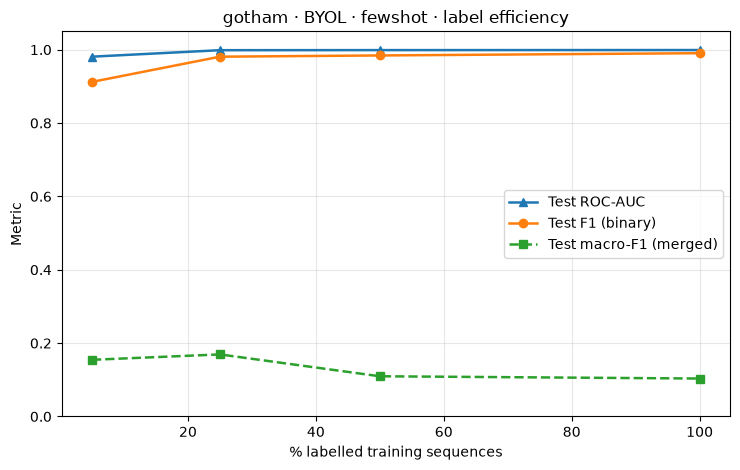

[plot] saved tft_plots\gotham\byol\fewshot\label_efficiency.png

[plot] ==== gotham · BYOL · finetune ====


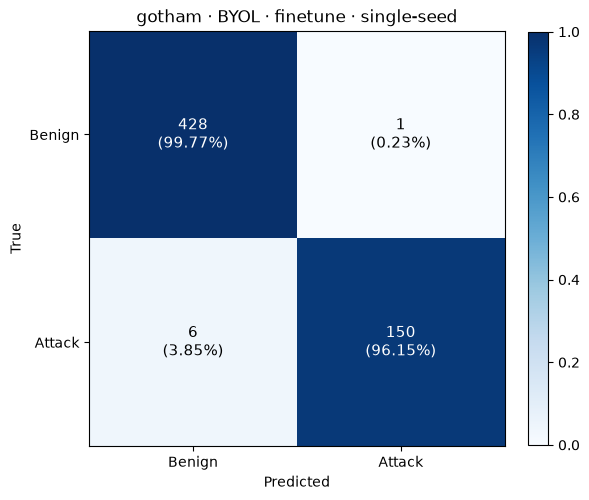

[plot] saved tft_plots\gotham\byol\finetune\confusion_main_run.png


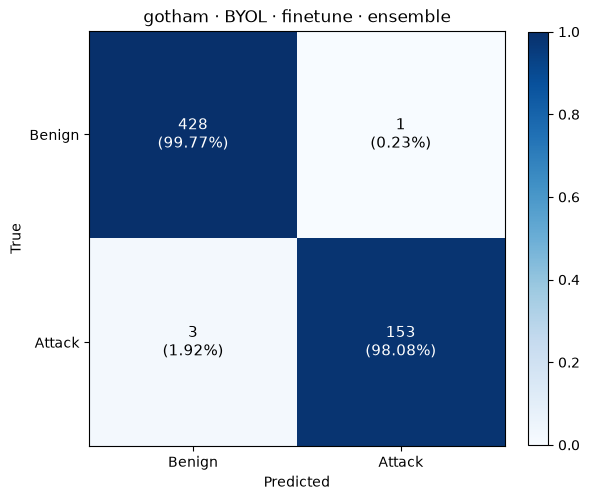

[plot] saved tft_plots\gotham\byol\finetune\confusion_ensemble.png


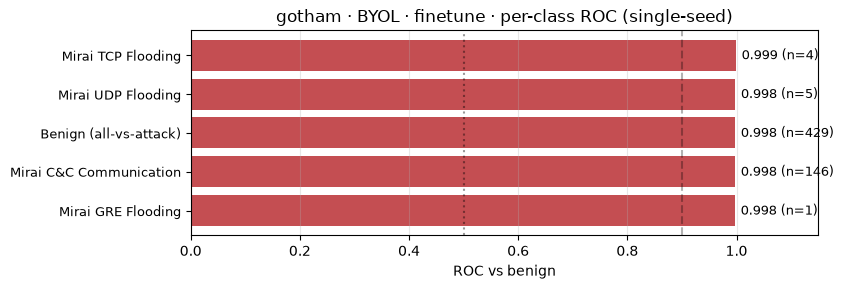

[plot] saved tft_plots\gotham\byol\finetune\per_class_roc_main_run.png


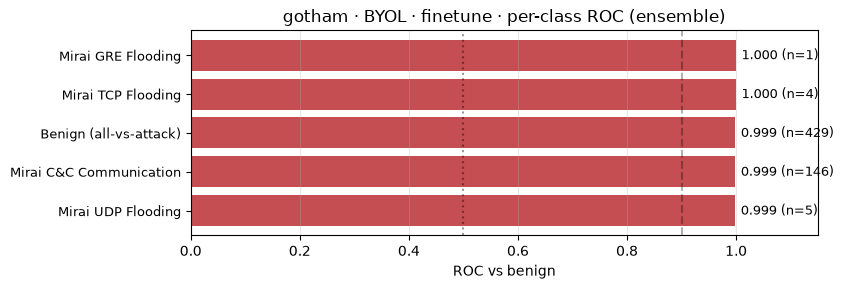

[plot] saved tft_plots\gotham\byol\finetune\per_class_roc_ensemble.png


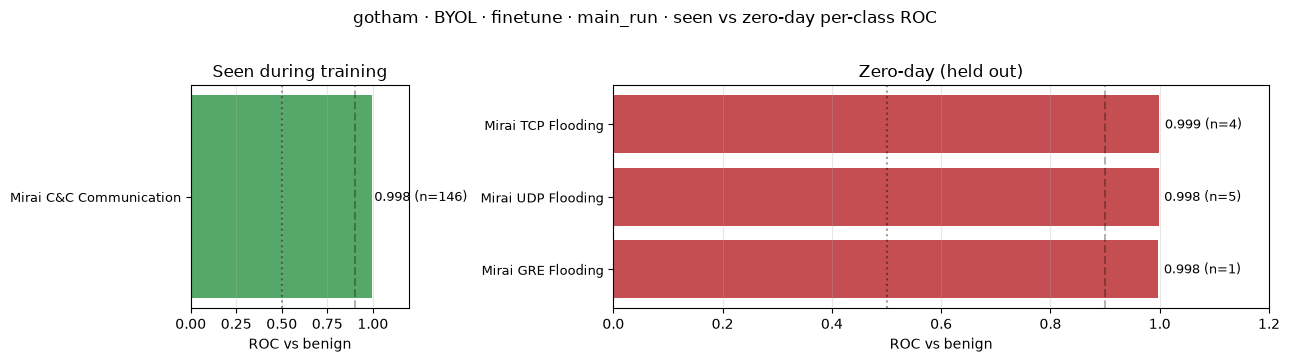

[plot] saved tft_plots\gotham\byol\finetune\zeroday_vs_seen_main_run.png
  [zeroday] gotham/byol/finetune/main_run: seen meanROC=0.998 meanRec=0.966 (n_classes=1)  ||  zero-day meanROC=0.998 meanRec=0.933 (n_classes=3)


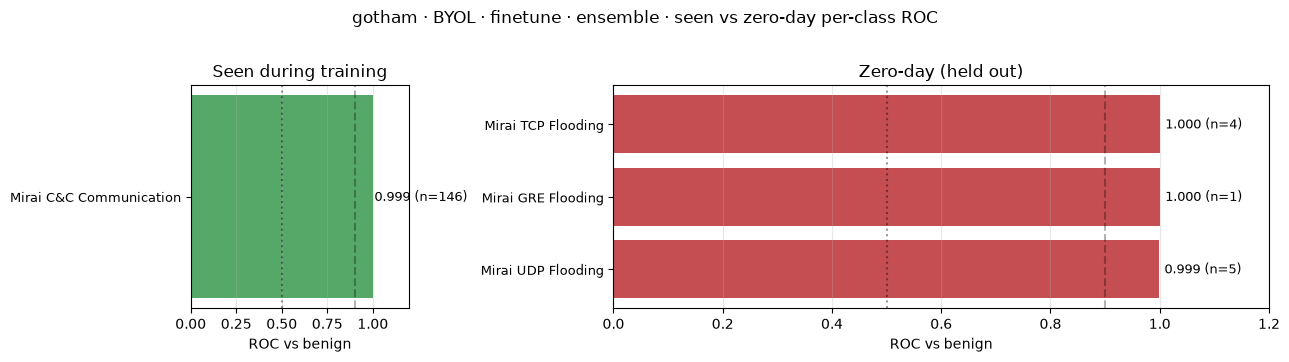

[plot] saved tft_plots\gotham\byol\finetune\zeroday_vs_seen_ensemble.png
  [zeroday] gotham/byol/finetune/ensemble: seen meanROC=0.999 meanRec=0.979 (n_classes=1)  ||  zero-day meanROC=1.000 meanRec=1.000 (n_classes=3)
[plot] gotham/byol/finetune: few-shot data is placeholder/NaN — skipping (RUN_FEWSHOT was False and no cached JSONs found)


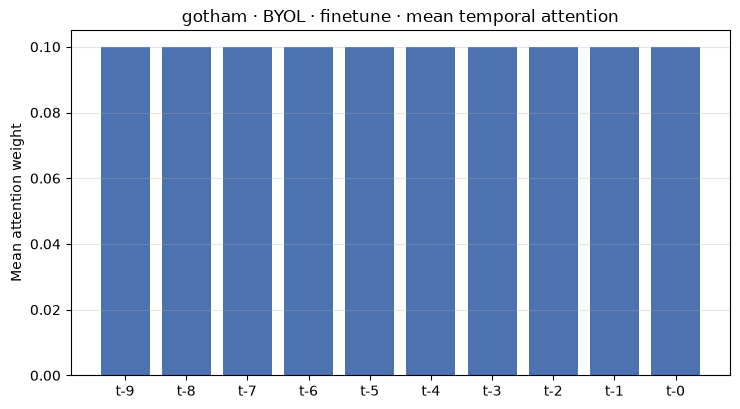

[plot] saved tft_plots\gotham\byol\finetune\attention_mean.png


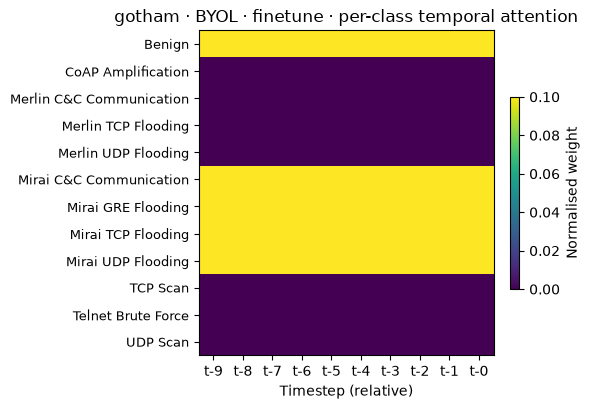

[plot] saved tft_plots\gotham\byol\finetune\attention_per_class.png


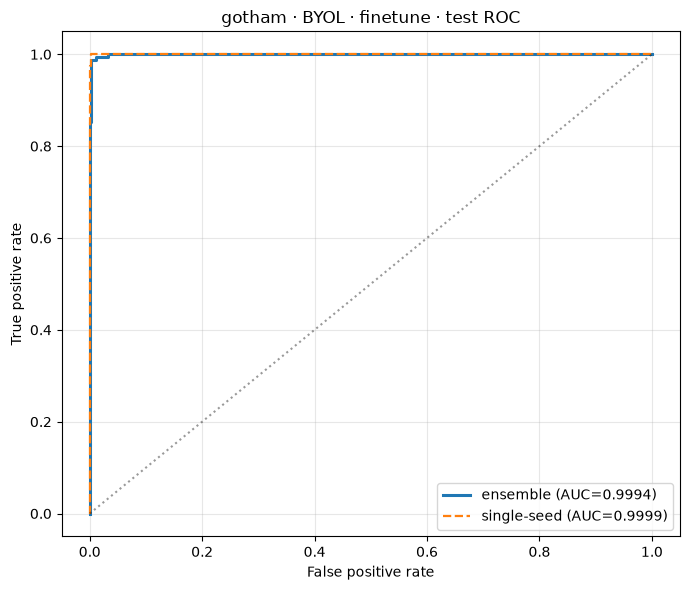

[plot] saved tft_plots\gotham\byol\finetune\roc_curve.png


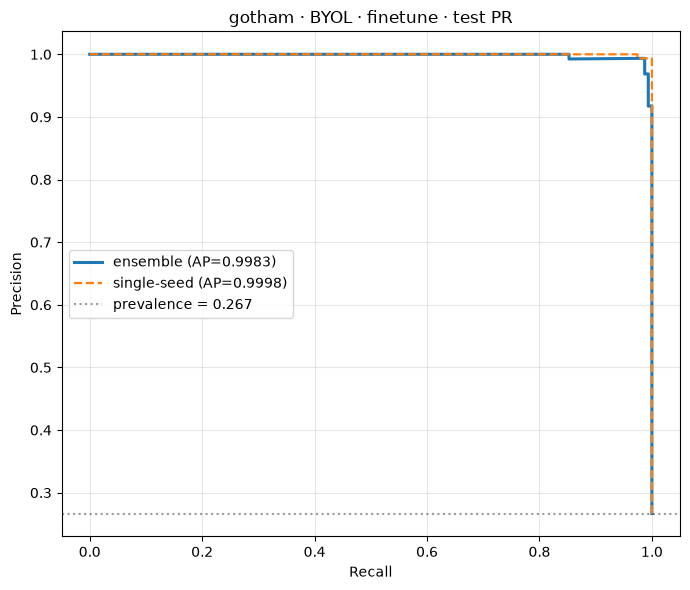

[plot] saved tft_plots\gotham\byol\finetune\pr_curve.png

[plot] ==== gotham · BYOL · frozen ====


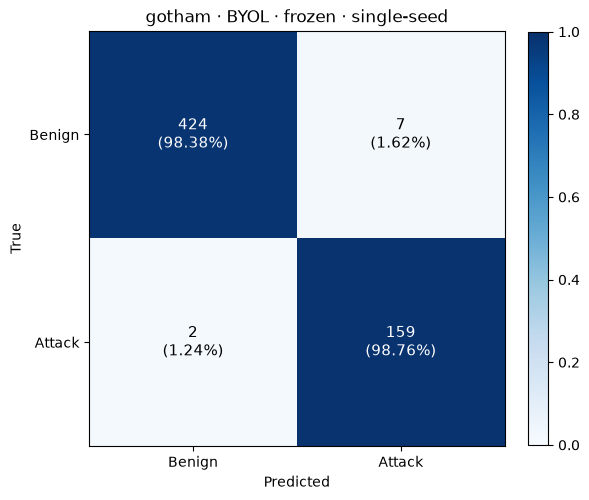

[plot] saved tft_plots\gotham\byol\frozen\confusion_main_run.png


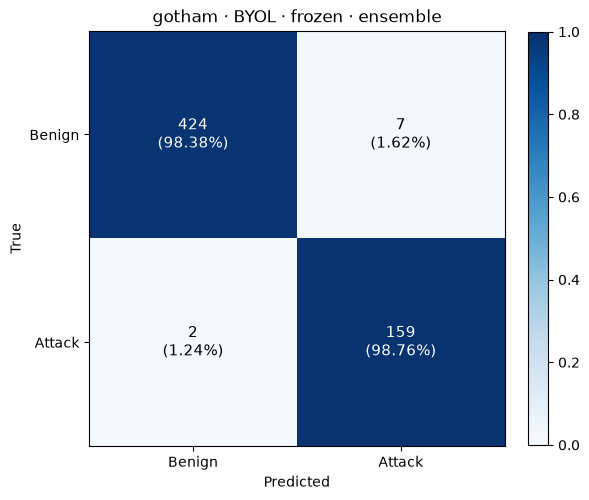

[plot] saved tft_plots\gotham\byol\frozen\confusion_ensemble.png


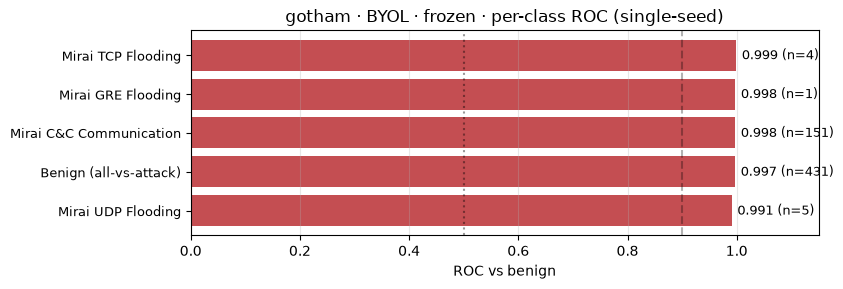

[plot] saved tft_plots\gotham\byol\frozen\per_class_roc_main_run.png


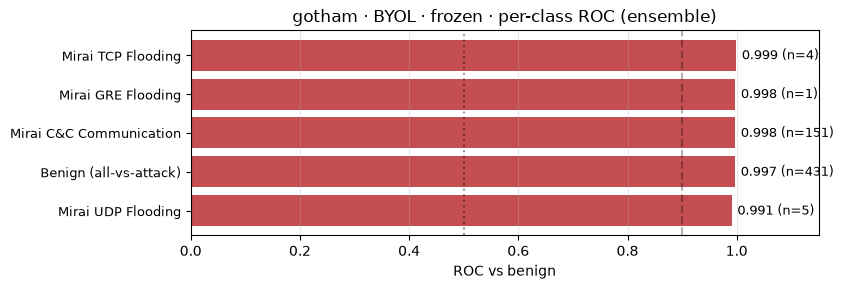

[plot] saved tft_plots\gotham\byol\frozen\per_class_roc_ensemble.png


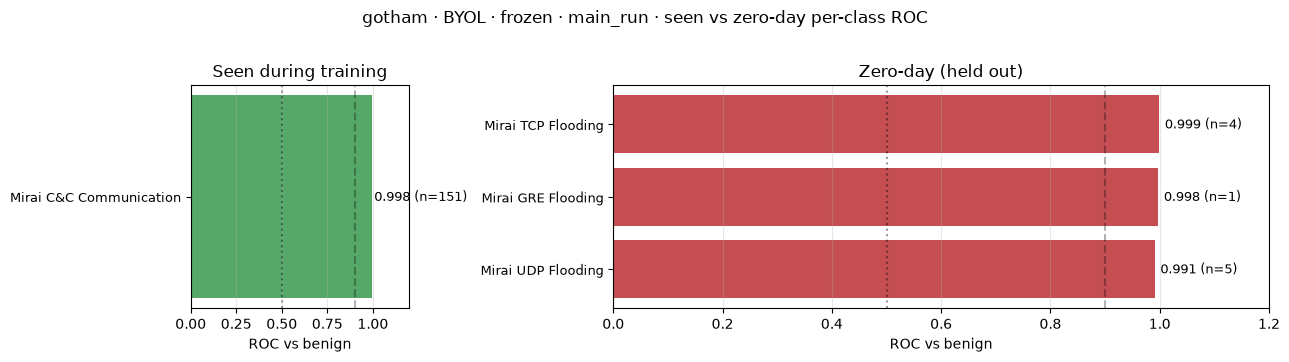

[plot] saved tft_plots\gotham\byol\frozen\zeroday_vs_seen_main_run.png
  [zeroday] gotham/byol/frozen/main_run: seen meanROC=0.998 meanRec=1.000 (n_classes=1)  ||  zero-day meanROC=0.996 meanRec=0.867 (n_classes=3)


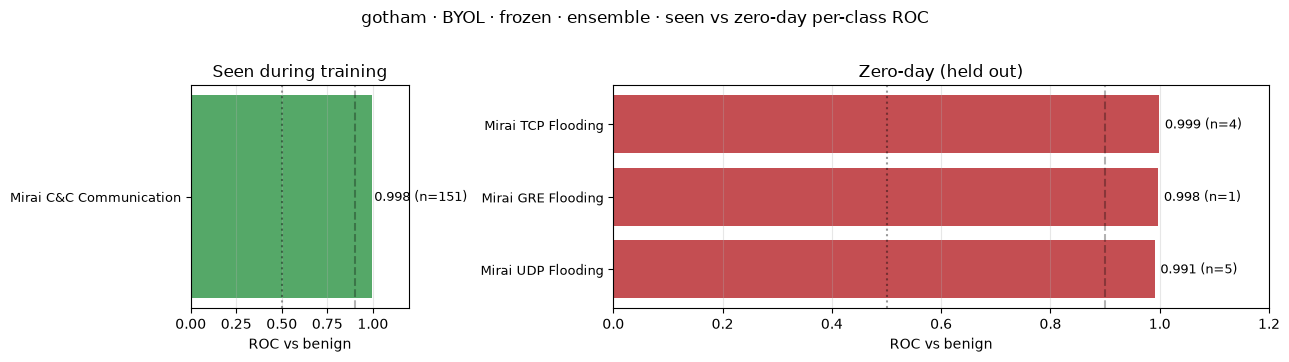

[plot] saved tft_plots\gotham\byol\frozen\zeroday_vs_seen_ensemble.png
  [zeroday] gotham/byol/frozen/ensemble: seen meanROC=0.998 meanRec=1.000 (n_classes=1)  ||  zero-day meanROC=0.996 meanRec=0.867 (n_classes=3)


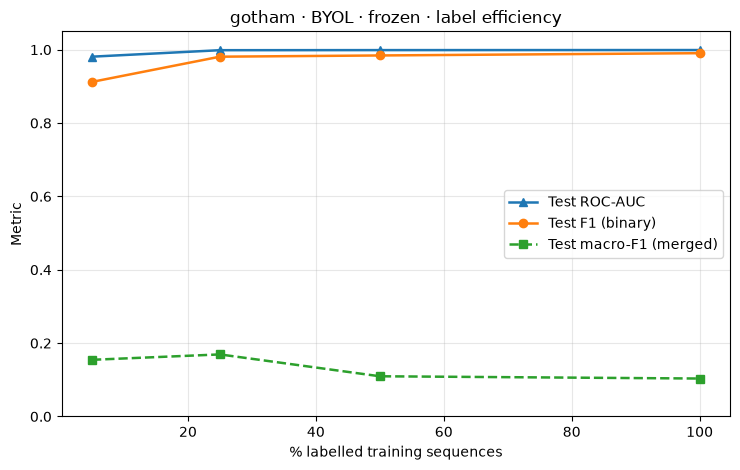

[plot] saved tft_plots\gotham\byol\frozen\label_efficiency.png


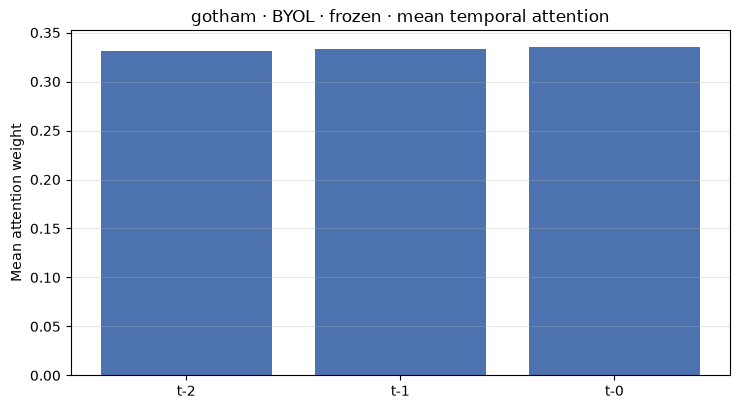

[plot] saved tft_plots\gotham\byol\frozen\attention_mean.png


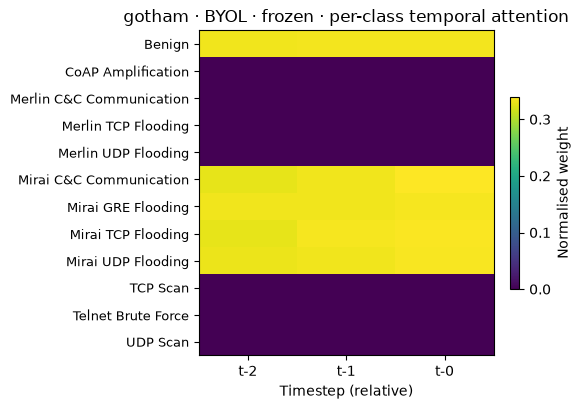

[plot] saved tft_plots\gotham\byol\frozen\attention_per_class.png


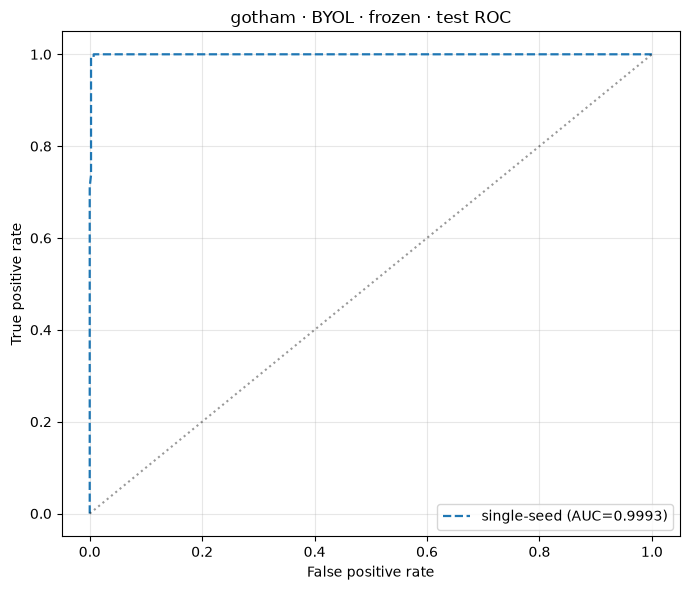

[plot] saved tft_plots\gotham\byol\frozen\roc_curve.png


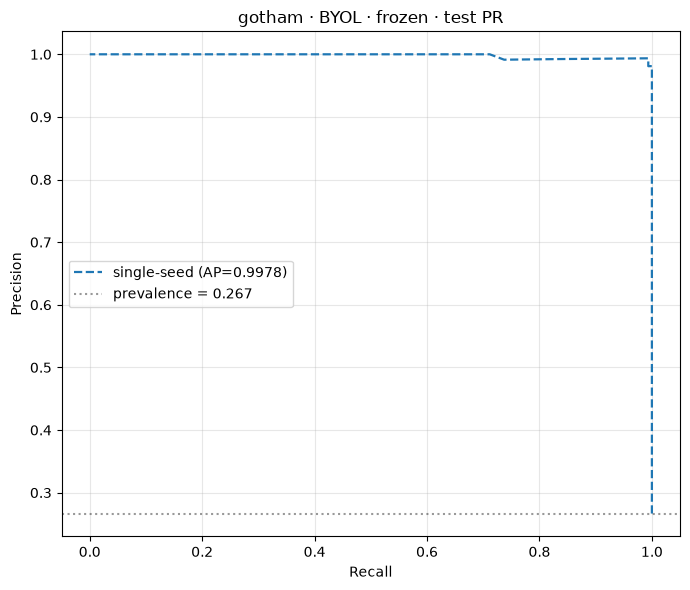

[plot] saved tft_plots\gotham\byol\frozen\pr_curve.png

[plot] ==== nf_bot · BYOL · fewshot ====


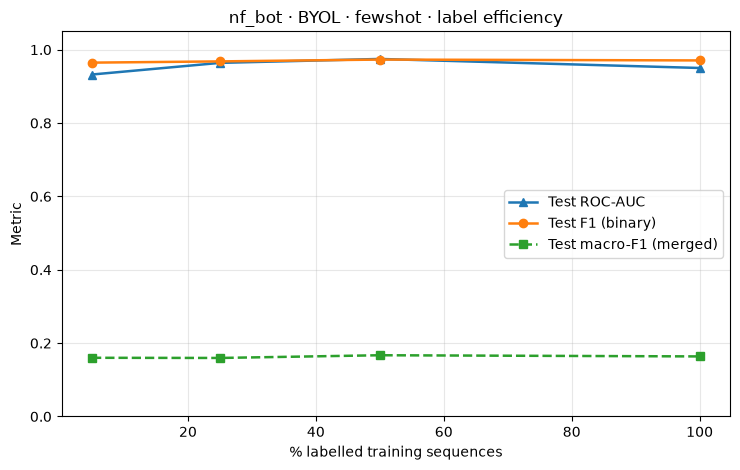

[plot] saved tft_plots\nf_bot\byol\fewshot\label_efficiency.png

[plot] ==== nf_bot · BYOL · finetune ====


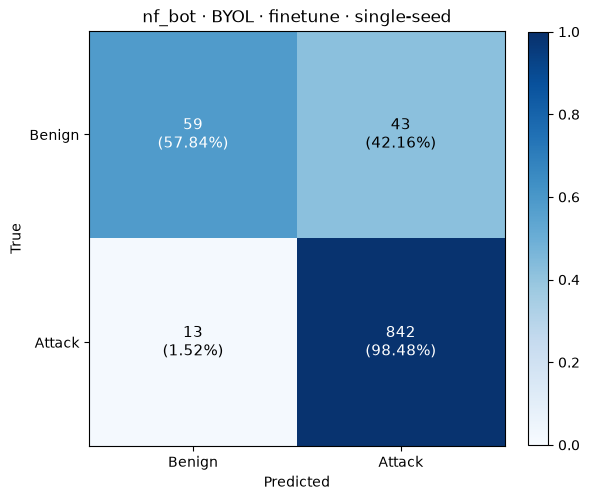

[plot] saved tft_plots\nf_bot\byol\finetune\confusion_main_run.png


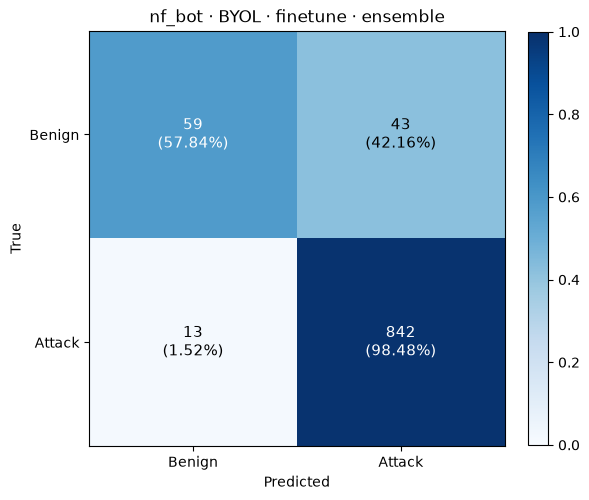

[plot] saved tft_plots\nf_bot\byol\finetune\confusion_ensemble.png


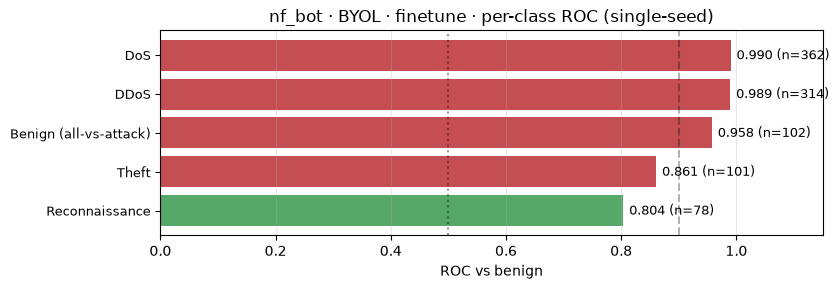

[plot] saved tft_plots\nf_bot\byol\finetune\per_class_roc_main_run.png


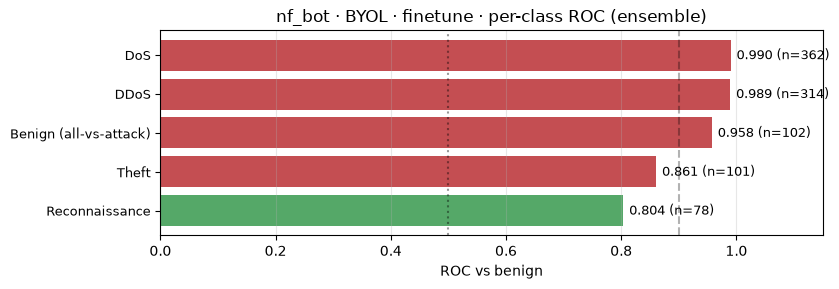

[plot] saved tft_plots\nf_bot\byol\finetune\per_class_roc_ensemble.png


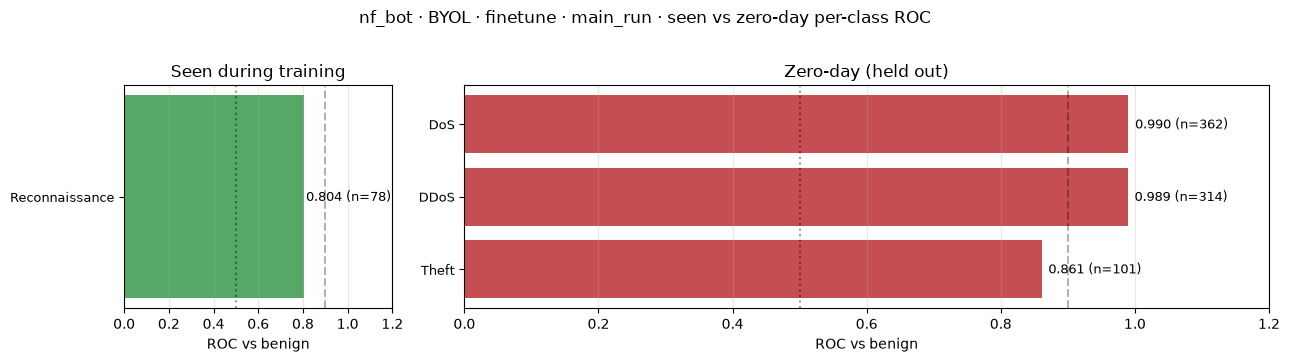

[plot] saved tft_plots\nf_bot\byol\finetune\zeroday_vs_seen_main_run.png
  [zeroday] nf_bot/byol/finetune/main_run: seen meanROC=0.804 meanRec=0.846 (n_classes=1)  ||  zero-day meanROC=0.947 meanRec=0.997 (n_classes=3)


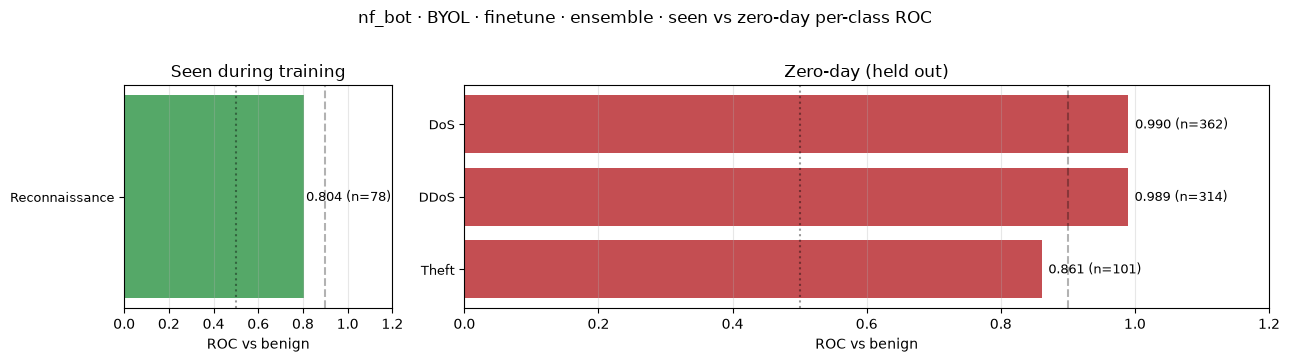

[plot] saved tft_plots\nf_bot\byol\finetune\zeroday_vs_seen_ensemble.png
  [zeroday] nf_bot/byol/finetune/ensemble: seen meanROC=0.804 meanRec=0.846 (n_classes=1)  ||  zero-day meanROC=0.947 meanRec=0.997 (n_classes=3)
[plot] nf_bot/byol/finetune: few-shot data is placeholder/NaN — skipping (RUN_FEWSHOT was False and no cached JSONs found)


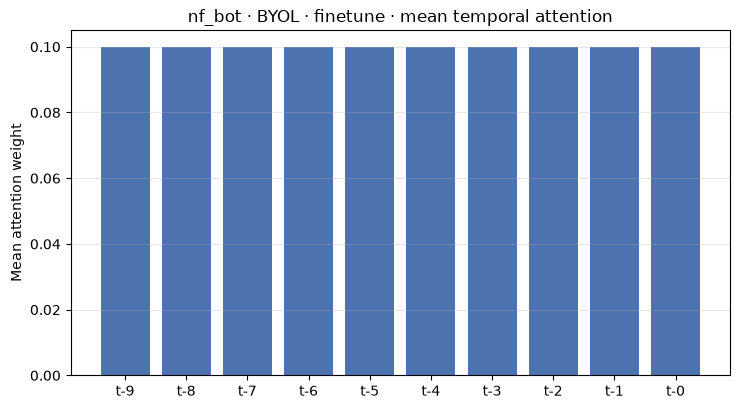

[plot] saved tft_plots\nf_bot\byol\finetune\attention_mean.png


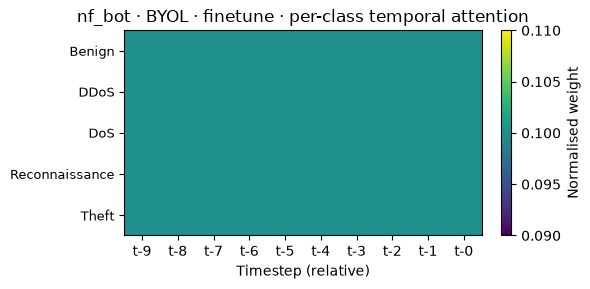

[plot] saved tft_plots\nf_bot\byol\finetune\attention_per_class.png


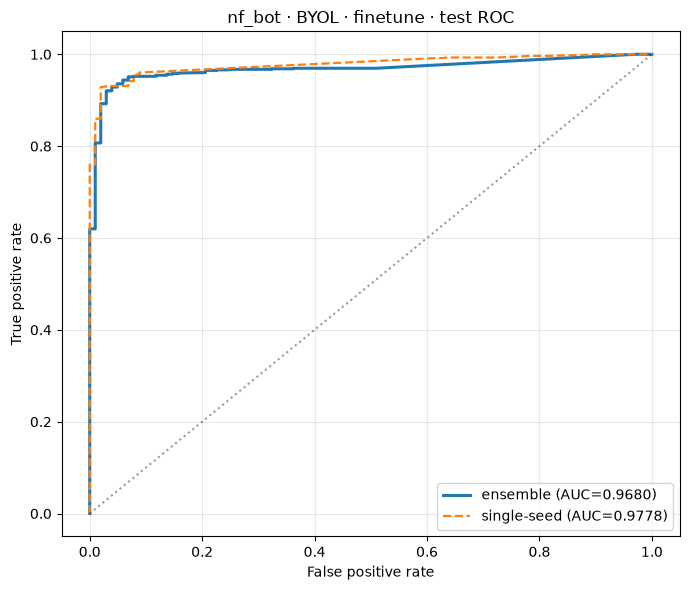

[plot] saved tft_plots\nf_bot\byol\finetune\roc_curve.png


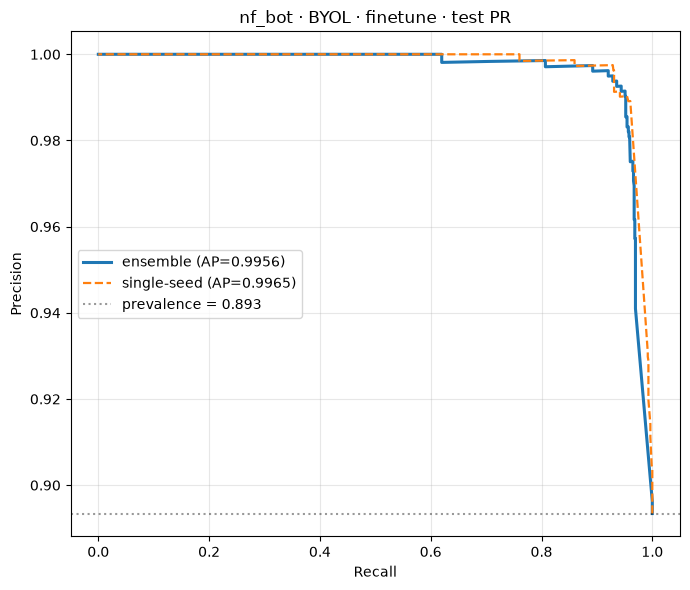

[plot] saved tft_plots\nf_bot\byol\finetune\pr_curve.png

[plot] ==== nf_bot · BYOL · frozen ====


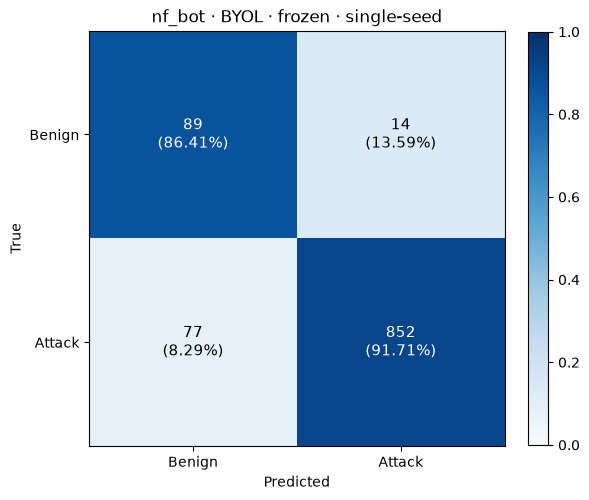

[plot] saved tft_plots\nf_bot\byol\frozen\confusion_main_run.png


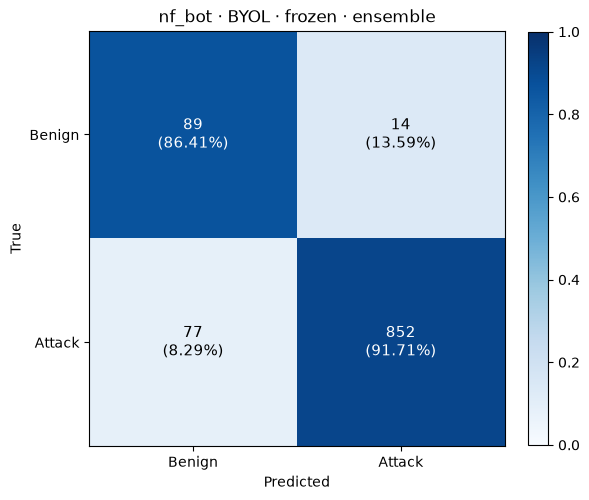

[plot] saved tft_plots\nf_bot\byol\frozen\confusion_ensemble.png


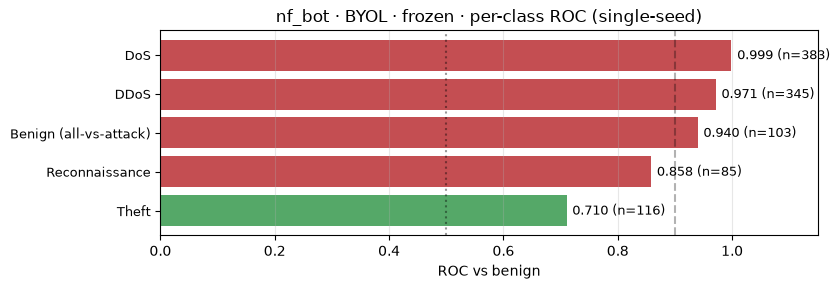

[plot] saved tft_plots\nf_bot\byol\frozen\per_class_roc_main_run.png


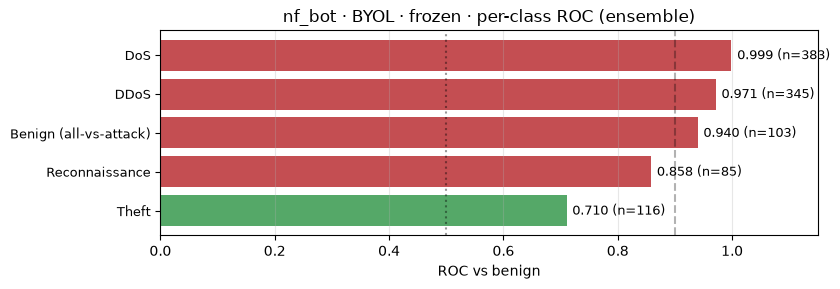

[plot] saved tft_plots\nf_bot\byol\frozen\per_class_roc_ensemble.png


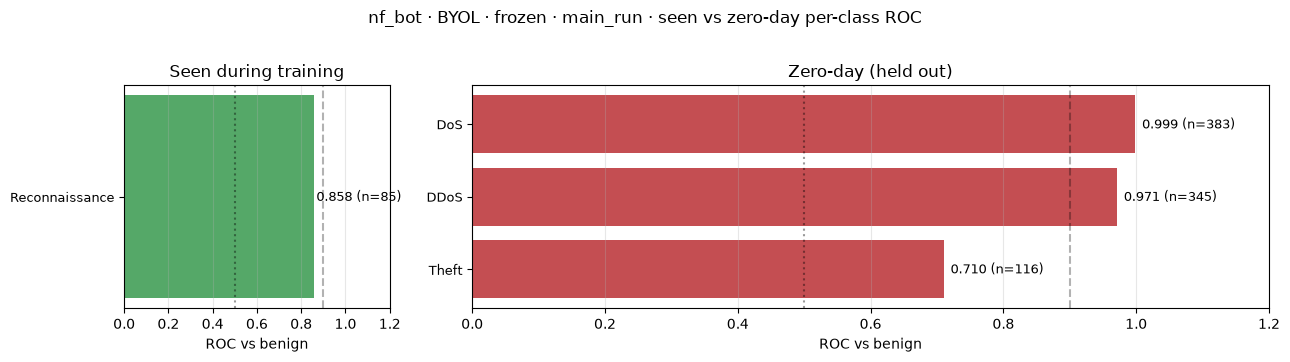

[plot] saved tft_plots\nf_bot\byol\frozen\zeroday_vs_seen_main_run.png
  [zeroday] nf_bot/byol/frozen/main_run: seen meanROC=0.858 meanRec=0.718 (n_classes=1)  ||  zero-day meanROC=0.894 meanRec=0.872 (n_classes=3)


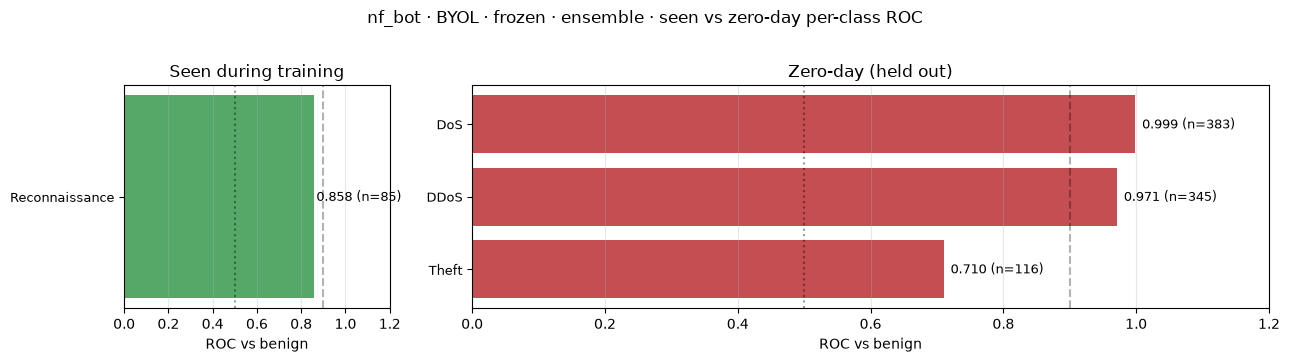

[plot] saved tft_plots\nf_bot\byol\frozen\zeroday_vs_seen_ensemble.png
  [zeroday] nf_bot/byol/frozen/ensemble: seen meanROC=0.858 meanRec=0.718 (n_classes=1)  ||  zero-day meanROC=0.894 meanRec=0.872 (n_classes=3)


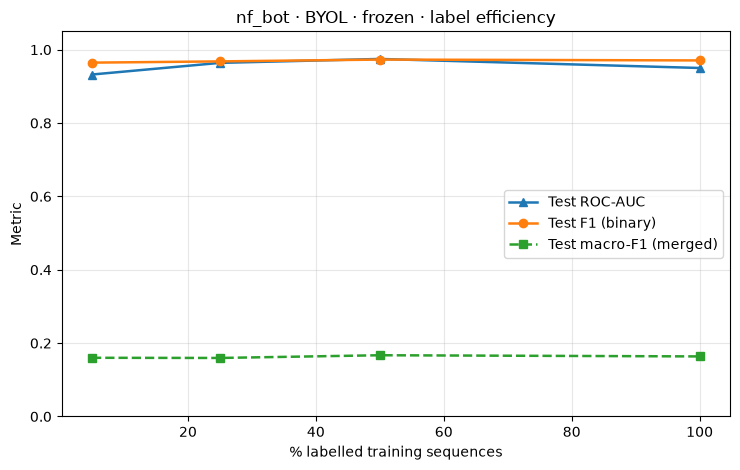

[plot] saved tft_plots\nf_bot\byol\frozen\label_efficiency.png


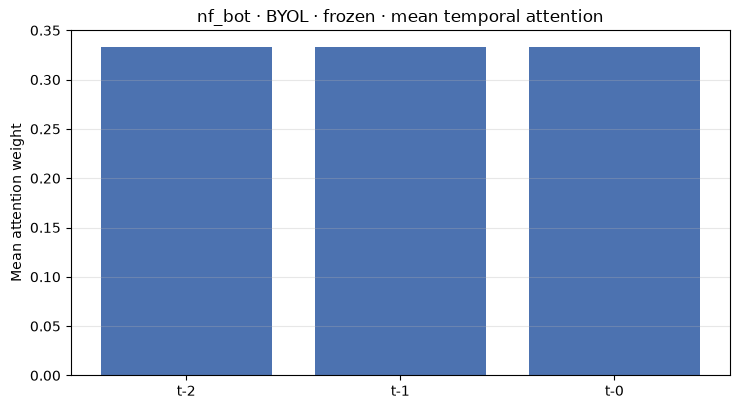

[plot] saved tft_plots\nf_bot\byol\frozen\attention_mean.png


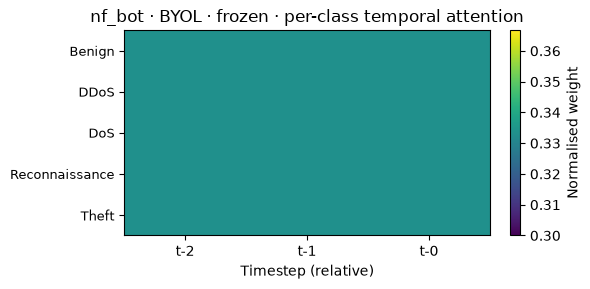

[plot] saved tft_plots\nf_bot\byol\frozen\attention_per_class.png


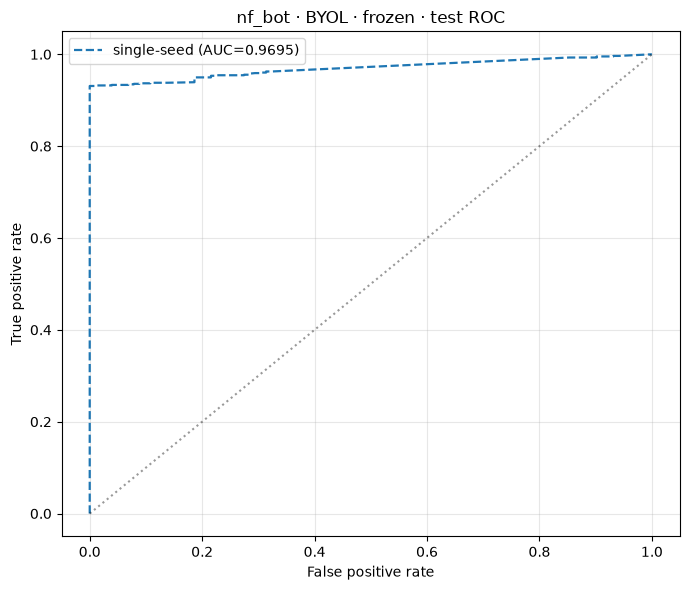

[plot] saved tft_plots\nf_bot\byol\frozen\roc_curve.png


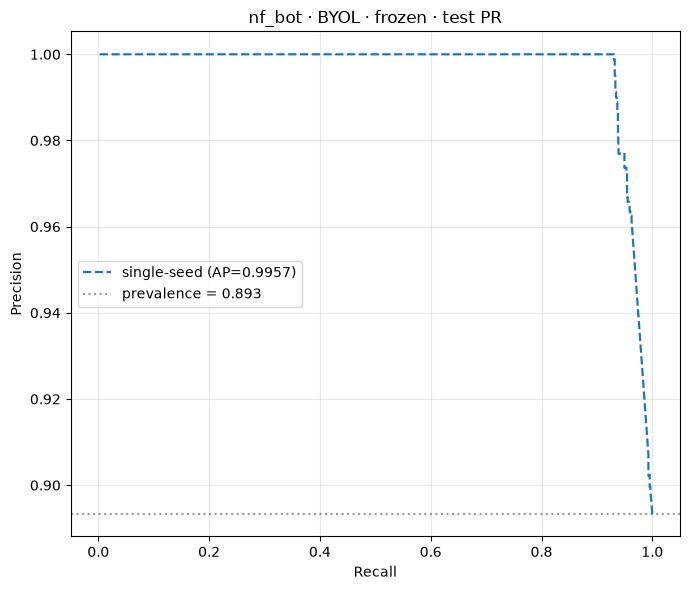

[plot] saved tft_plots\nf_bot\byol\frozen\pr_curve.png

[plot] ==== nf_ton · BYOL · fewshot ====


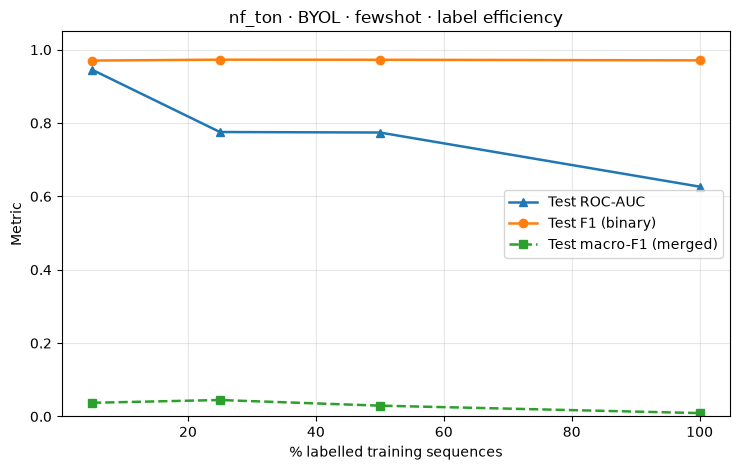

[plot] saved tft_plots\nf_ton\byol\fewshot\label_efficiency.png

[plot] ==== nf_ton · BYOL · finetune ====


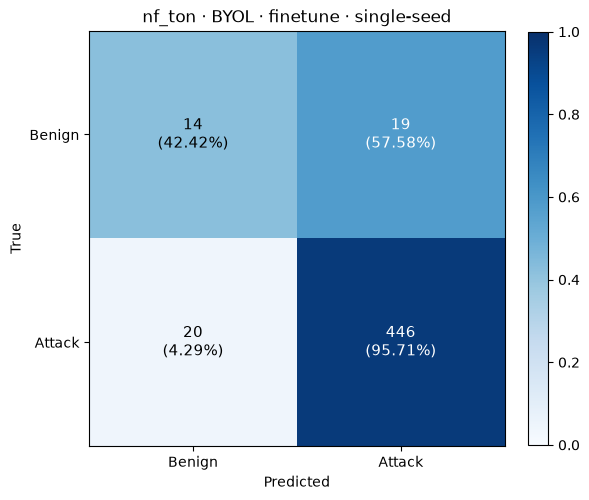

[plot] saved tft_plots\nf_ton\byol\finetune\confusion_main_run.png


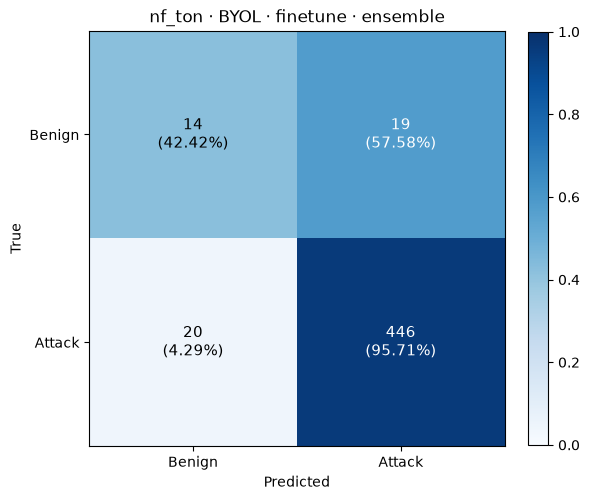

[plot] saved tft_plots\nf_ton\byol\finetune\confusion_ensemble.png


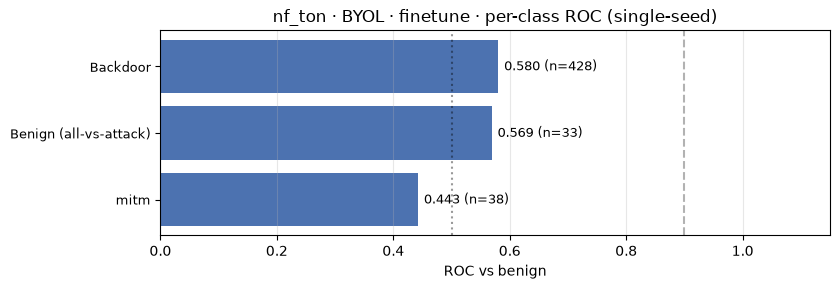

[plot] saved tft_plots\nf_ton\byol\finetune\per_class_roc_main_run.png


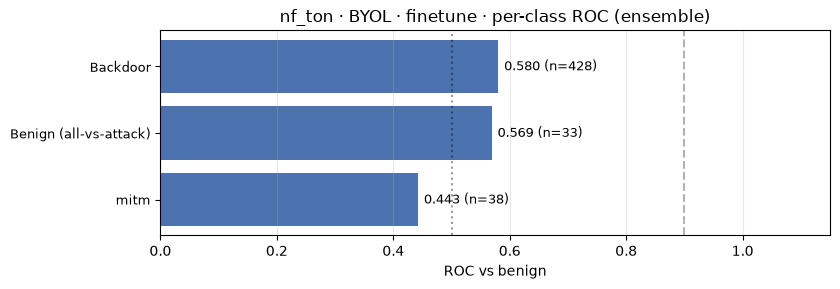

[plot] saved tft_plots\nf_ton\byol\finetune\per_class_roc_ensemble.png


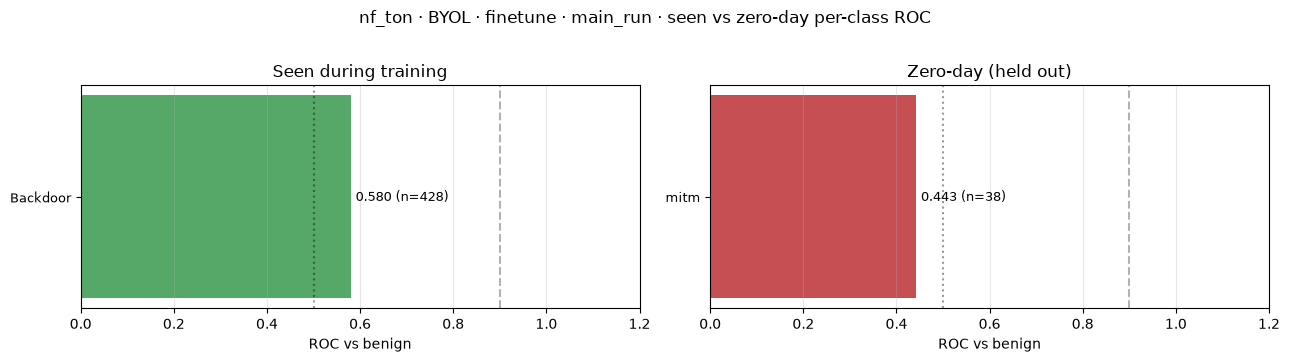

[plot] saved tft_plots\nf_ton\byol\finetune\zeroday_vs_seen_main_run.png
  [zeroday] nf_ton/byol/finetune/main_run: seen meanROC=0.580 meanRec=1.000 (n_classes=1)  ||  zero-day meanROC=0.443 meanRec=0.474 (n_classes=1)


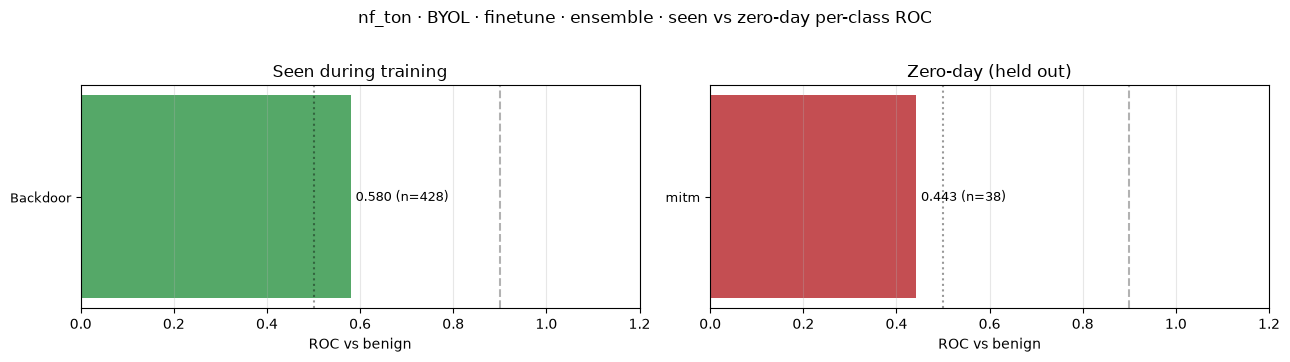

[plot] saved tft_plots\nf_ton\byol\finetune\zeroday_vs_seen_ensemble.png
  [zeroday] nf_ton/byol/finetune/ensemble: seen meanROC=0.580 meanRec=1.000 (n_classes=1)  ||  zero-day meanROC=0.443 meanRec=0.474 (n_classes=1)


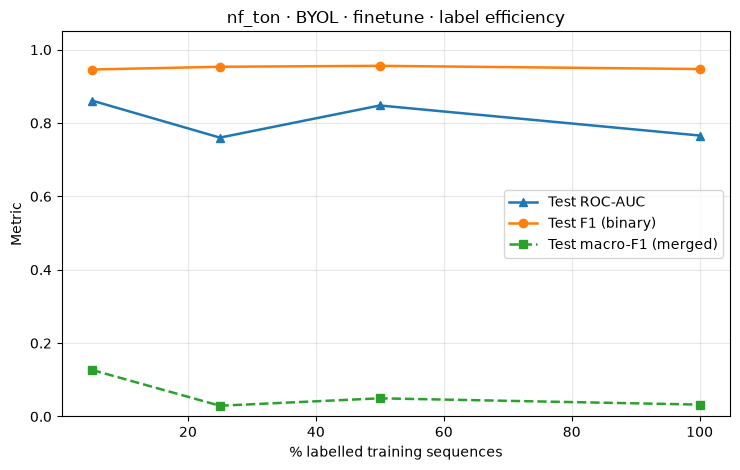

[plot] saved tft_plots\nf_ton\byol\finetune\label_efficiency.png


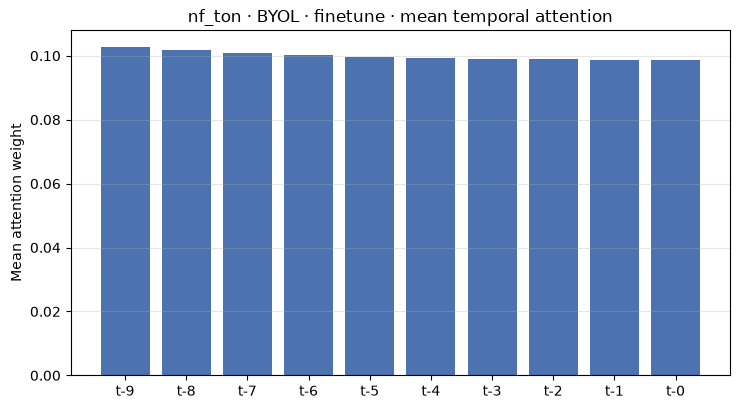

[plot] saved tft_plots\nf_ton\byol\finetune\attention_mean.png


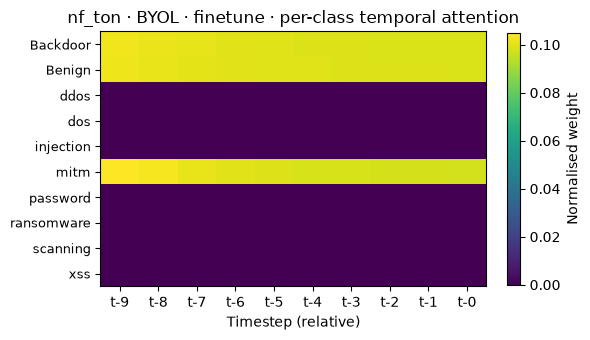

[plot] saved tft_plots\nf_ton\byol\finetune\attention_per_class.png


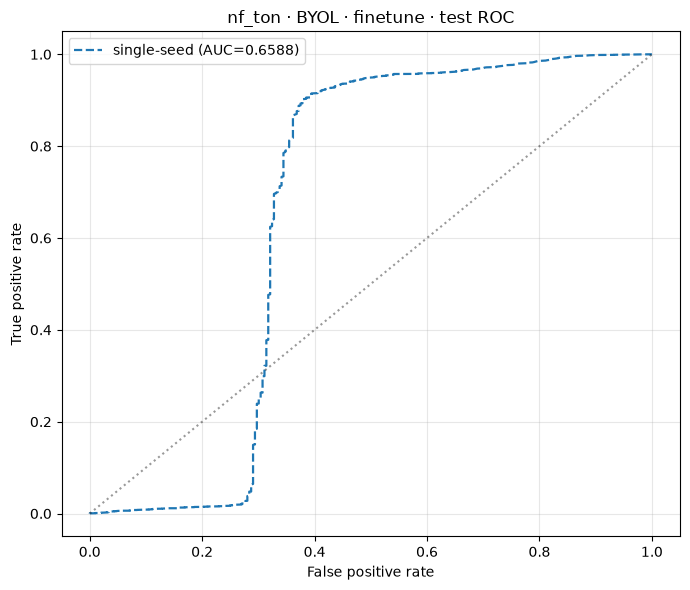

[plot] saved tft_plots\nf_ton\byol\finetune\roc_curve.png


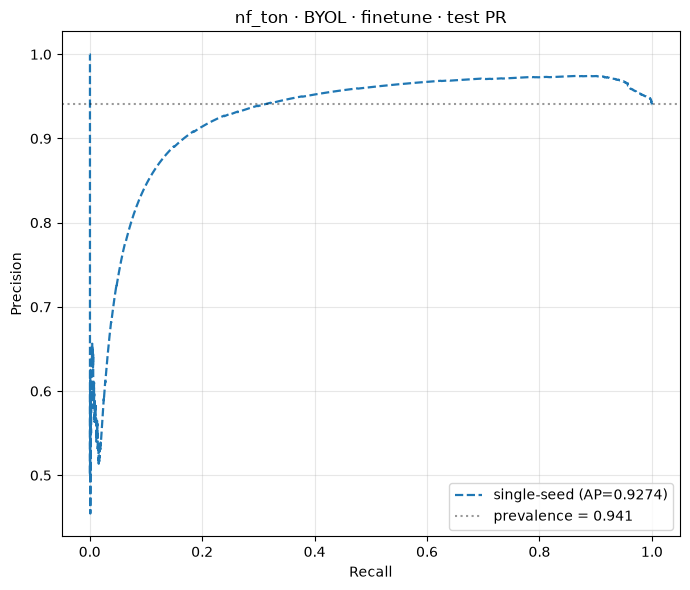

[plot] saved tft_plots\nf_ton\byol\finetune\pr_curve.png

[plot] ==== nf_ton · BYOL · frozen ====


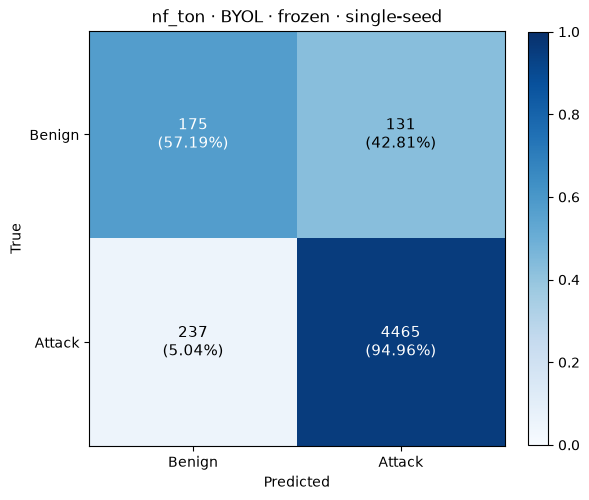

[plot] saved tft_plots\nf_ton\byol\frozen\confusion_main_run.png


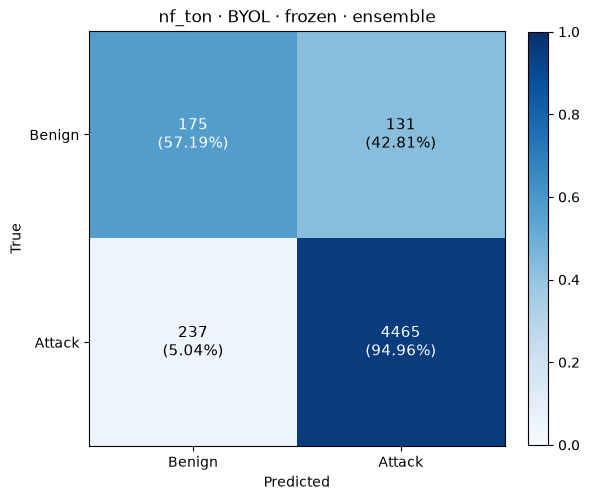

[plot] saved tft_plots\nf_ton\byol\frozen\confusion_ensemble.png


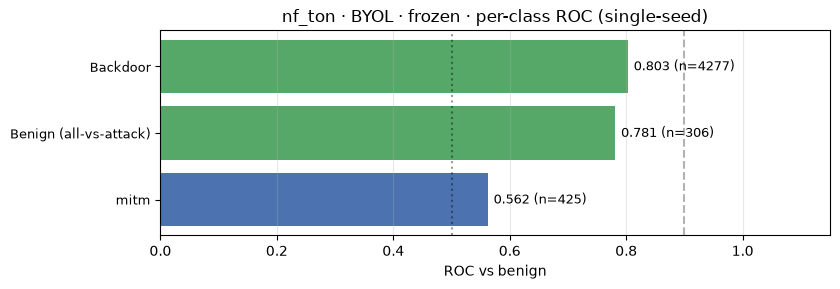

[plot] saved tft_plots\nf_ton\byol\frozen\per_class_roc_main_run.png


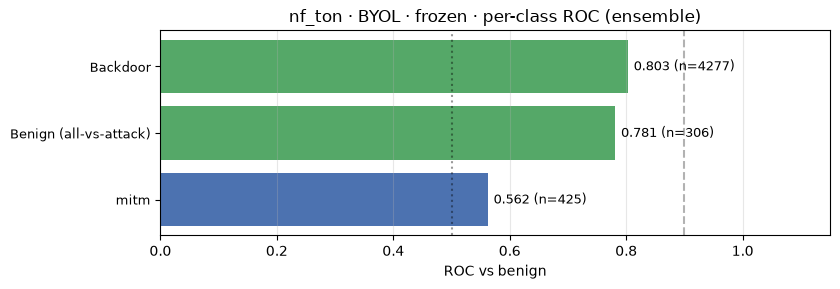

[plot] saved tft_plots\nf_ton\byol\frozen\per_class_roc_ensemble.png


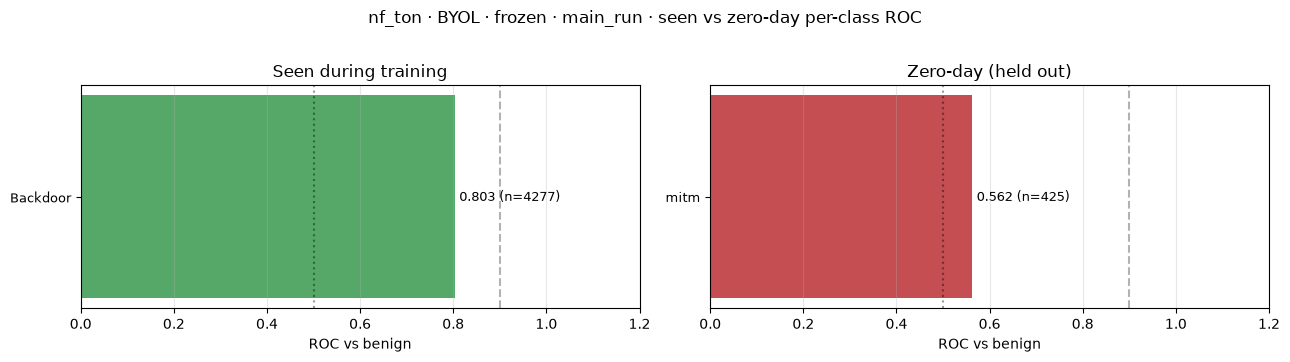

[plot] saved tft_plots\nf_ton\byol\frozen\zeroday_vs_seen_main_run.png
  [zeroday] nf_ton/byol/frozen/main_run: seen meanROC=0.803 meanRec=0.998 (n_classes=1)  ||  zero-day meanROC=0.562 meanRec=0.466 (n_classes=1)


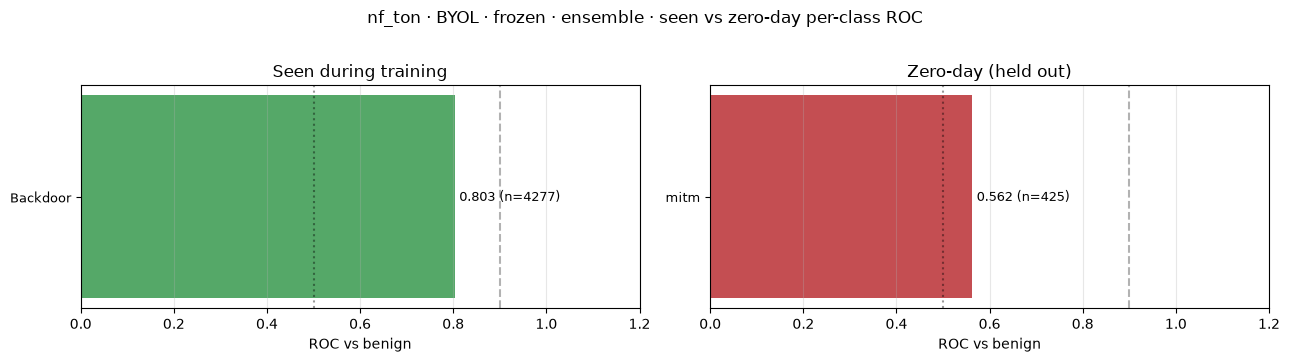

[plot] saved tft_plots\nf_ton\byol\frozen\zeroday_vs_seen_ensemble.png
  [zeroday] nf_ton/byol/frozen/ensemble: seen meanROC=0.803 meanRec=0.998 (n_classes=1)  ||  zero-day meanROC=0.562 meanRec=0.466 (n_classes=1)


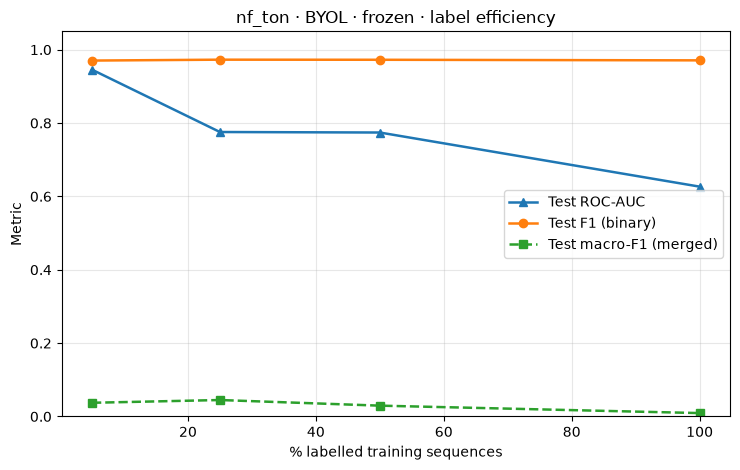

[plot] saved tft_plots\nf_ton\byol\frozen\label_efficiency.png


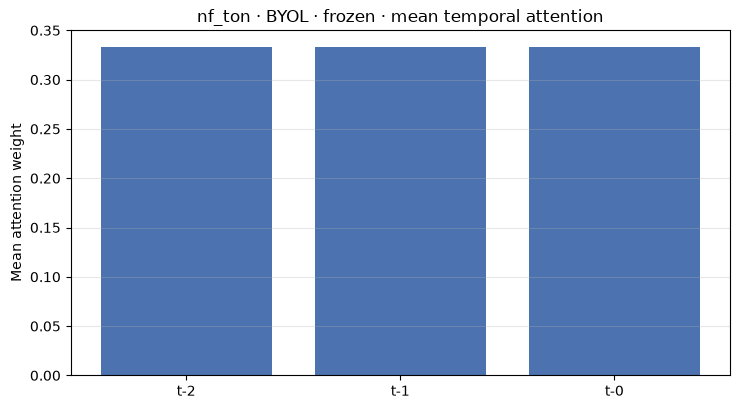

[plot] saved tft_plots\nf_ton\byol\frozen\attention_mean.png


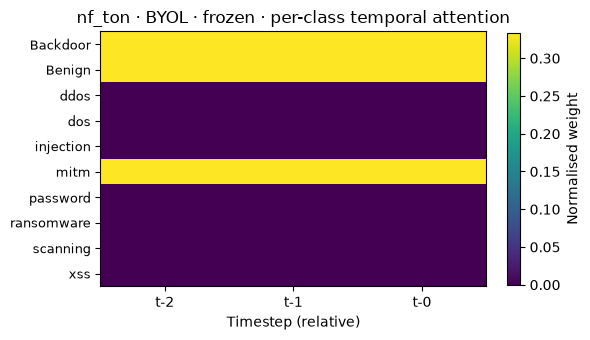

[plot] saved tft_plots\nf_ton\byol\frozen\attention_per_class.png


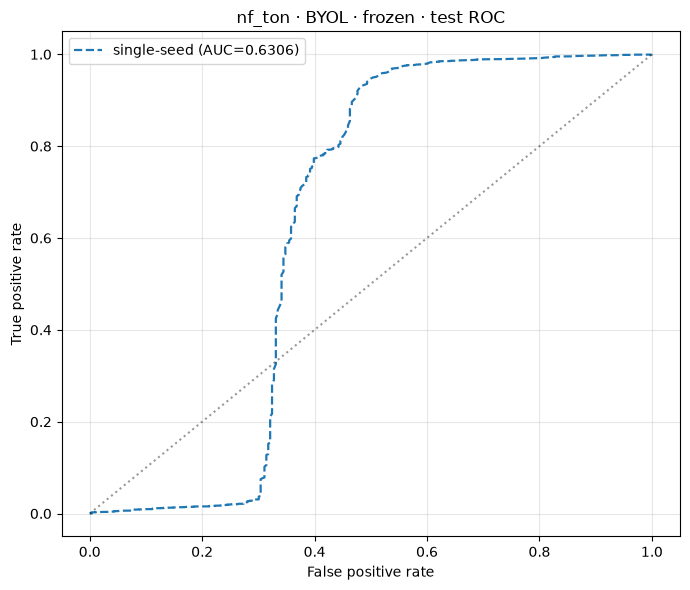

[plot] saved tft_plots\nf_ton\byol\frozen\roc_curve.png


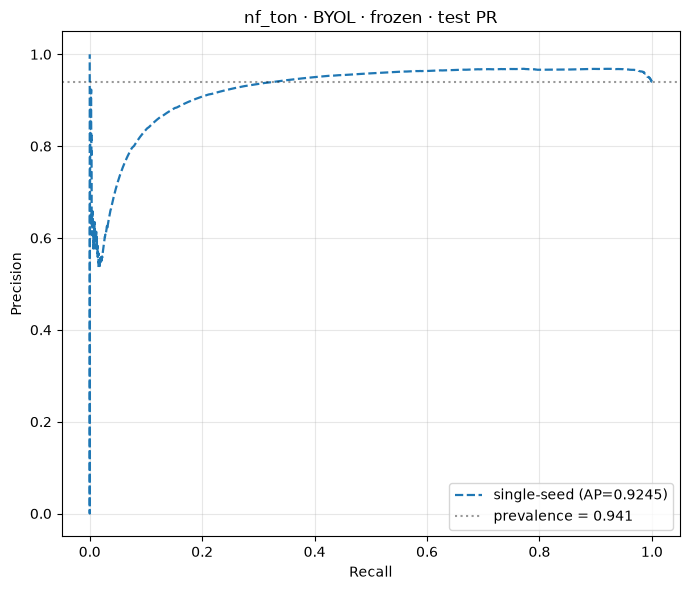

[plot] saved tft_plots\nf_ton\byol\frozen\pr_curve.png


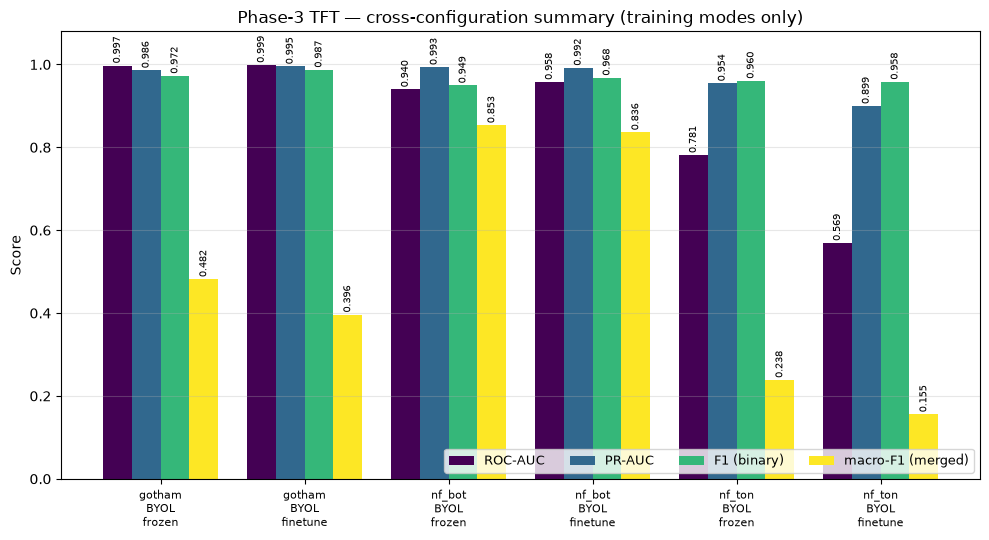

[plot] saved tft_plots\cross_config_summary.png
[plot] BYOL vs MoCo: no matched pairs


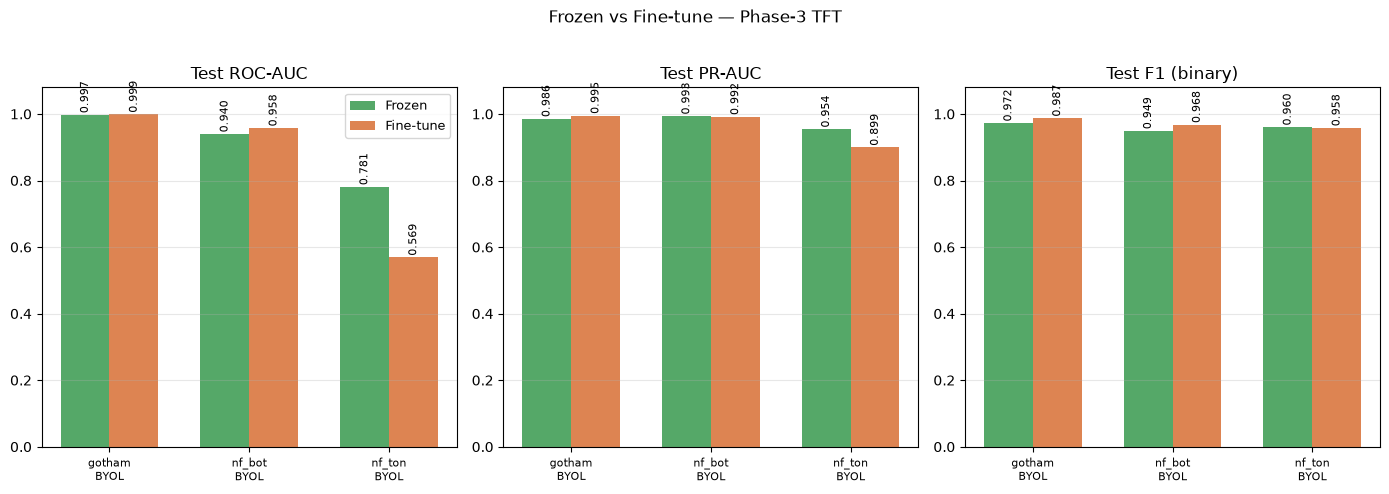

[plot] saved tft_plots\frozen_vs_finetune.png


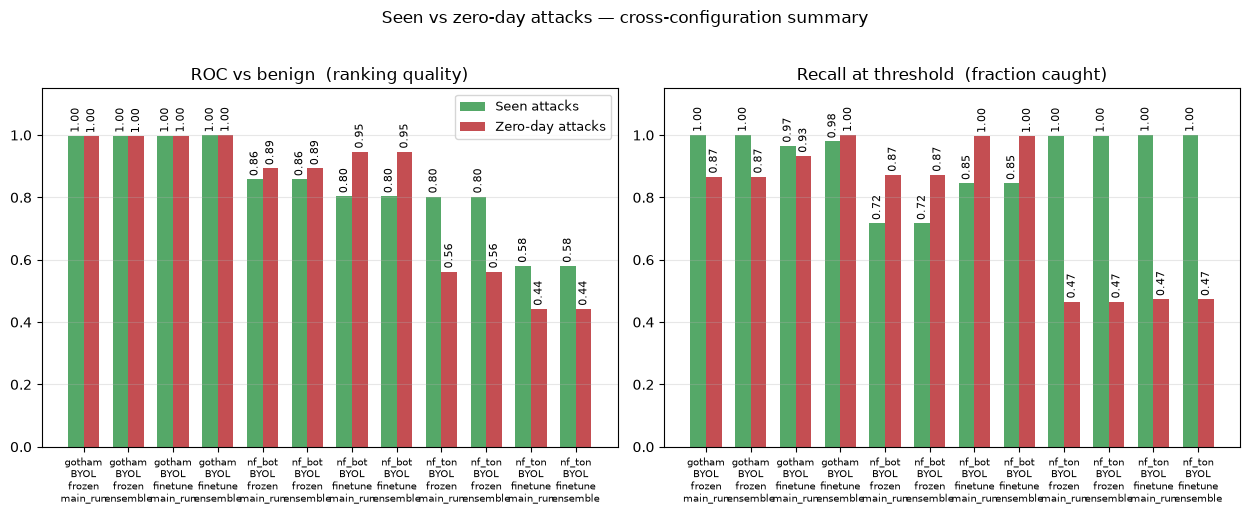

[plot] saved tft_plots\zeroday_vs_seen_summary.png

[plot] done — everything under c:\Users\User\Desktop\MC-STGAT-IDS\MC-STGAT-IDS-V3 - Copy\tft_plots/


In [56]:
# =====================================================================
# Phase-3 TFT plotting block  (self-healing, supports 'fewshot' mode)
#
# Discovers every phase3_report.json on disk (frozen, finetune) plus
# every phase3_fewshot_*.json and exposes them as a virtual 'fewshot'
# mode. Loads probs.npz if present, otherwise rebuilds the model from
# checkpoints and saves probs.npz for next time. Produces the full set
# of thesis-ready figures.
#
# Must be run inside the Phase-3 session for the recompute path to work.
# =====================================================================
import os, gc, json
import numpy as np
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# 1) Discovery
# ---------------------------------------------------------------
DATASET_ROOT = {
    'gotham': 'Gotham_processed_features_10s/graphs',
    'nf_bot': 'NFBoTIoT_v3_10s/graphs',
    'nf_ton': 'NFToNIoT_v3_10s/graphs',
}
SSL_METHODS    = ['byol']
MODES          = ['frozen', 'finetune', 'fewshot']
TRAIN_MODES    = ['frozen', 'finetune']

PLOT_ROOT = 'tft_plots'
os.makedirs(PLOT_ROOT, exist_ok=True)


def _ckpt_dir(ds, ssl, mode):
    """Return directory for a training mode. For 'fewshot', fall back to the
    frozen/finetune directory that actually contains the few-shot JSONs."""
    if mode == 'fewshot':
        for m in TRAIN_MODES:
            d = os.path.join(DATASET_ROOT[ds], f'phase3_checkpoints_{ssl}_{m}')
            if os.path.isdir(d) and any(
                    f.startswith('phase3_fewshot_') for f in os.listdir(d)):
                return d
        # fallback: frozen
        return os.path.join(DATASET_ROOT[ds], f'phase3_checkpoints_{ssl}_frozen')
    return os.path.join(DATASET_ROOT[ds], f'phase3_checkpoints_{ssl}_{mode}')


def _report_path(ds, ssl, mode):
    return os.path.join(_ckpt_dir(ds, ssl, mode), 'phase3_report.json')


def _probs_path(ds, ssl, mode):
    if mode == 'fewshot':
        return None
    return os.path.join(_ckpt_dir(ds, ssl, mode), 'probs.npz')


def _load_json(p):
    if not os.path.isfile(p):
        return None
    try:
        with open(p) as f:
            return json.load(f)
    except Exception:
        return None


# ---------- discovery ----------
REPORTS = {}

for _ds in DATASET_ROOT:
    for _ssl in SSL_METHODS:

        # real training modes
        for _mode in TRAIN_MODES:
            p = _report_path(_ds, _ssl, _mode)
            if os.path.isfile(p):
                REPORTS[(_ds, _ssl, _mode)] = _load_json(p)

        # virtual 'fewshot' mode: aggregate all phase3_fewshot_*.json
        _found_fs = {}
        for _mode in TRAIN_MODES:
            d = os.path.join(DATASET_ROOT[_ds], f'phase3_checkpoints_{_ssl}_{_mode}')
            if not os.path.isdir(d):
                continue
            for fname in os.listdir(d):
                if not (fname.startswith('phase3_fewshot_') and fname.endswith('.json')):
                    continue
                try:
                    frac = int(fname.replace('phase3_fewshot_', '').replace('.json', '')) / 100.0
                except ValueError:
                    continue
                if frac in _found_fs:
                    continue
                j = _load_json(os.path.join(d, fname))
                if j:
                    _found_fs[frac] = j
        if _found_fs:
            REPORTS[(_ds, _ssl, 'fewshot')] = {
                'dataset': _ds,
                'ssl_method': _ssl,
                'fewshot': {str(k): v for k, v in _found_fs.items()},
                '_source_dir': _ckpt_dir(_ds, _ssl, 'fewshot'),
            }

print(f"[tft-plot] discovered {len(REPORTS)} report entries:")
for _k in sorted(REPORTS):
    tag = '  (virtual)' if _k[2] == 'fewshot' else ''
    print(f"  {_k[0]:7s} {_k[1]:5s} {_k[2]:9s}{tag}")

AVAILABLE_DS  = sorted({k[0] for k in REPORTS})
AVAILABLE_SSL = sorted({k[1] for k in REPORTS})


def _out_dir(*parts):
    p = os.path.join(PLOT_ROOT, *parts)
    os.makedirs(p, exist_ok=True)
    return p


def _save_fig(fig, path):
    plt.tight_layout()
    plt.savefig(path, dpi=140, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print(f"[plot] saved {path}")


# ---------------------------------------------------------------
# 2) Self-healing probs: recompute from checkpoints when missing
# ---------------------------------------------------------------
def _recompute_probs(ds, ssl, mode):
    """Rebuild the model, run val+test forward passes, save probs.npz.
    Not applicable to 'fewshot' (returns None)."""

    if mode == 'fewshot':
        return None

    _needed = ['GATEncoder', 'MC_STGAT_IDS', 'GraphSequenceDataset',
               'collate_graph_sequences', 'build_gap_aware_starts',
               'cap_graph', 'dominant_family', 'sanitize_tensor',
               'autocast_ctx', 'DEVICE', 'SEQUENCE_STRIDE',
               'ENFORCE_MAX_WINDOW_GAP', 'SANITIZE_GRAPH_EMB',
               'TFT_NUM_HEADS', 'TFT_DROPOUT']
    _missing = [n for n in _needed if n not in globals()]
    if _missing:
        print(f"[plot-recompute] {ds}/{ssl}/{mode}: cannot recompute "
              f"(missing {_missing}); run this cell inside the Phase-3 session")
        return None

    import pickle, torch, json as _json
    from torch.utils.data import DataLoader
    import torch.nn.functional as F

    ckpt_path = os.path.join(_ckpt_dir(ds, ssl, mode), 'mc_stgat_ids.pth')
    if not os.path.isfile(ckpt_path):
        return None

    print(f"[plot-recompute] {ds}/{ssl}/{mode}: rebuilding from checkpoint")
    ckpt = torch.load(ckpt_path, map_location=DEVICE)

    class_names  = ckpt['class_names']
    label_to_idx = ckpt['label_to_idx']
    seq_len      = int(ckpt.get('sequence_length', 10))
    num_struct   = int(ckpt.get('num_struct_feats', 28))
    num_classes  = int(ckpt.get('num_classes', len(class_names)))
    hidden_dim   = int(ckpt.get('hidden_dim', 128))
    tft_hidden   = int(ckpt.get('tft_hidden_dim', 384))

    enc_path = os.path.join(DATASET_ROOT[ds], f'ssl_checkpoints_{ssl}',
                            'ssl_encoder_best.pth')
    if not os.path.isfile(enc_path):
        print(f"[plot-recompute] {ds}/{ssl}/{mode}: no SSL encoder"); return None
    enc_ckpt = torch.load(enc_path, map_location=DEVICE)

    def _build_encoder():
        return GATEncoder(enc_ckpt['node_dim'], enc_ckpt['hidden_dim'],
                          enc_ckpt['num_heads'], enc_ckpt['num_layers'],
                          enc_ckpt['edge_dim']).to(DEVICE)

    enc = _build_encoder()
    if mode == 'finetune' and 'encoder_state_dict' in ckpt:
        enc.load_state_dict(ckpt['encoder_state_dict'])
    else:
        enc.load_state_dict(enc_ckpt['encoder_state_dict'])
    enc.eval()

    def _build_tft():
        return MC_STGAT_IDS(hidden_dim, num_struct, tft_hidden, num_classes,
                            TFT_NUM_HEADS, TFT_DROPOUT).to(DEVICE)

    tft = _build_tft()
    tft.load_state_dict(ckpt['tft_state_dict'])
    tft.eval()

    DATA_DIR = DATASET_ROOT[ds]
    with open(os.path.join(DATA_DIR, 'norm_stats.json')) as f:
        ns = _json.load(f)
    N_CONT    = ns['n_continuous_edge_feats']
    node_mean = torch.tensor(ns['node_mean'], dtype=torch.float)
    node_std  = torch.tensor(ns['node_std'],  dtype=torch.float)
    edge_mean = torch.tensor(ns['edge_mean'], dtype=torch.float)
    edge_std  = torch.tensor(ns['edge_std'],  dtype=torch.float)
    MWG       = float(ns.get('max_window_gap_sec', 60.0))

    def _load(split):
        with open(os.path.join(DATA_DIR, f'{split}_graphs.pkl'), 'rb') as f:
            return pickle.load(f)

    vg = [cap_graph(g) for g in _load('val')]
    eg = [cap_graph(g) for g in _load('test')]

    def _norm(graphs):
        for g in graphs:
            g.x = torch.clamp((g.x - node_mean) / (node_std + 1e-8), -10, 10)
            if g.edge_attr is not None and g.edge_attr.size(0) > 0:
                if g.edge_attr.dim() > 2:
                    g.edge_attr = g.edge_attr.view(-1, g.edge_attr.size(-1))
                c, p = g.edge_attr[:, :N_CONT], g.edge_attr[:, N_CONT:]
                c = torch.clamp((c - edge_mean) / (edge_std + 1e-8), -10, 10)
                g.edge_attr = torch.cat([c, p], dim=1)
            if g.edge_attr is None or g.edge_attr.size(0) == 0:
                g.edge_attr = torch.zeros((g.edge_index.size(1), N_CONT),
                                          dtype=torch.float)
            g.x = torch.nan_to_num(g.x, nan=0.0, posinf=0.0, neginf=0.0)
            g.edge_attr = torch.nan_to_num(g.edge_attr, nan=0.0,
                                           posinf=0.0, neginf=0.0)
    _norm(vg); _norm(eg)

    if 'precompute_struct' in globals():
        str_val, str_test = precompute_struct(vg), precompute_struct(eg)
    else:
        def _struct(g):
            x  = g.x.numpy()
            ea = g.edge_attr.numpy() if g.edge_attr is not None else np.zeros((0, 0))
            ei = g.edge_index.numpy()
            N = x.shape[0]; E = ei.shape[1]
            deg = np.bincount(ei[0], minlength=N) if E > 0 else np.zeros(N)
            base = np.array([float(N), float(E),
                             float(deg.mean()) if N > 0 else 0.0,
                             float(np.log1p(E))], dtype=np.float32)
            nm = x.mean(0) if N > 0 else np.zeros(x.shape[1], dtype=np.float32)
            sd = x.std(0)  if N > 0 else np.zeros(x.shape[1], dtype=np.float32)
            em = ea.mean(0) if E > 0 and ea.ndim == 2 else np.zeros(
                ea.shape[-1] if ea.ndim == 2 else 0, dtype=np.float32)
            return np.concatenate([base, nm, sd, em]).astype(np.float32)
        def _stack(graphs):
            return torch.tensor(np.stack([_struct(g) for g in graphs]),
                                dtype=torch.float32)
        str_val, str_test = _stack(vg), _stack(eg)

    val_fams  = [dominant_family(g, 0) for g in vg]
    test_fams = [dominant_family(g, 0) for g in eg]

    def _yb(f): return np.array([0.0 if x == 'Benign' else 1.0 for x in f],
                                dtype=np.float32)
    def _ym(f): return np.array([label_to_idx.get(x, 0) for x in f],
                                dtype=np.int64)

    val_yb,  val_ym  = _yb(val_fams),  _ym(val_fams)
    test_yb, test_ym = _yb(test_fams), _ym(test_fams)

    val_starts  = build_gap_aware_starts(vg, seq_len, SEQUENCE_STRIDE, MWG,
                                         enforce=ENFORCE_MAX_WINDOW_GAP,
                                         verbose=False)
    test_starts = build_gap_aware_starts(eg, seq_len, SEQUENCE_STRIDE, MWG,
                                         enforce=ENFORCE_MAX_WINDOW_GAP,
                                         verbose=False)

    def _seq(y, starts): return np.array([y[s + seq_len - 1] for s in starts])

    val_yb_s,  val_ym_s  = _seq(val_yb,  val_starts), _seq(val_ym,  val_starts)
    test_yb_s, test_ym_s = _seq(test_yb, test_starts), _seq(test_ym, test_starts)
    test_labels_seq      = np.array([test_fams[s + seq_len - 1]
                                     for s in test_starts])

    def _loader(graphs, starts, yb, ym, struct):
        d = GraphSequenceDataset(graphs, starts, seq_len, yb, ym, struct)
        return DataLoader(d, batch_size=16, shuffle=False,
                          collate_fn=collate_graph_sequences, num_workers=0)

    val_loader  = _loader(vg, val_starts,  val_yb_s,  val_ym_s,  str_val)
    test_loader = _loader(eg, test_starts, test_yb_s, test_ym_s, str_test)

    def _infer(loader, e_x, t_x):
        bp, mp, yb, ym = [], [], [], []
        e_x.eval(); t_x.eval()
        with torch.no_grad():
            for item in loader:
                fb, B, T, ss, y_b, y_m = item
                fb = fb.to(DEVICE, non_blocking=True)
                ss = ss.to(DEVICE, non_blocking=True)
                with autocast_ctx():
                    out = e_x(fb.x, fb.edge_index, fb.edge_attr, fb.batch)
                    h = out[-1] if isinstance(out, tuple) else out
                    ge = h.view(B, T, -1).float()
                    if SANITIZE_GRAPH_EMB:
                        ge = sanitize_tensor(ge)
                    ss2 = sanitize_tensor(ss)
                    bl, ml, _, _ = t_x(ge, ss2)
                bp.append(torch.sigmoid(bl.float()).cpu().numpy())
                mp.append(F.softmax(ml.float(), -1).cpu().numpy())
                yb.append(y_b.numpy()); ym.append(y_m.numpy())
        return (np.concatenate(bp), np.concatenate(mp),
                np.concatenate(yb), np.concatenate(ym))

    pb_val, pm_val, yb_val, ym_val     = _infer(val_loader,  enc, tft)
    pb_test, pm_test, yb_test, ym_test = _infer(test_loader, enc, tft)

    # ensemble seeds
    ens_bin_probs = ens_multi_probs = None
    partial_dir = os.path.join(_ckpt_dir(ds, ssl, mode), 'partial_checkpoints')
    per_seed_bin, per_seed_multi = [], []
    if os.path.isdir(partial_dir):
        for s in [1337, 2024, 7]:
            sp = os.path.join(partial_dir, f'best_{ds}_{ssl}_seed{s}.pth')
            if not os.path.isfile(sp):
                continue
            try:
                sc = torch.load(sp, map_location='cpu')
                tft_s = _build_tft()
                tft_s.load_state_dict(sc['tft_state_dict'])
                tft_s.eval()
                if mode == 'finetune' and 'encoder_state_dict' in sc:
                    enc_s = _build_encoder()
                    enc_s.load_state_dict(sc['encoder_state_dict'])
                    enc_s.eval()
                else:
                    enc_s = enc
                sb, sm, _, _ = _infer(test_loader, enc_s, tft_s)
                per_seed_bin.append(sb)
                per_seed_multi.append(sm)
                del tft_s
                if enc_s is not enc:
                    del enc_s
                if DEVICE.type == 'cuda':
                    torch.cuda.empty_cache()
            except Exception as e:
                print(f"[plot-recompute] {ds}/{ssl}/{mode}: seed {s} skipped ({e})")
                continue

    if per_seed_bin:
        ens_bin_probs   = np.mean(per_seed_bin,   axis=0)
        ens_multi_probs = np.mean(per_seed_multi, axis=0)

    np.savez(_probs_path(ds, ssl, mode),
             pb_test=pb_test, pm_test=pm_test,
             yb_test=yb_test, ym_test=ym_test,
             pb_val=pb_val,   pm_val=pm_val,
             yb_val=yb_val,   ym_val=ym_val,
             ens_bin_probs  = (ens_bin_probs   if ens_bin_probs   is not None
                               else np.array([])),
             ens_multi_probs= (ens_multi_probs if ens_multi_probs is not None
                               else np.array([])),
             ens_y_bin      = (yb_test if ens_bin_probs   is not None
                               else np.array([])),
             ens_y_multi    = (ym_test if ens_multi_probs is not None
                               else np.array([])),
             test_labels_seq=test_labels_seq,
             class_names=np.array(class_names, dtype=object))
    print(f"[plot-recompute] saved {_probs_path(ds, ssl, mode)}")

    del enc, tft
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    gc.collect()

    return dict(
        pb_test=pb_test, pm_test=pm_test,
        yb_test=yb_test, ym_test=ym_test,
        pb_val=pb_val,   pm_val=pm_val,
        yb_val=yb_val,   ym_val=ym_val,
        ens_bin_probs=ens_bin_probs, ens_multi_probs=ens_multi_probs,
        ens_y_bin=yb_test if ens_bin_probs is not None else None,
        ens_y_multi=ym_test if ens_multi_probs is not None else None,
        test_labels_seq=test_labels_seq,
        class_names=class_names,
    )


def _ensure_probs(ds, ssl, mode, force_recompute=False):
    if mode == 'fewshot':
        return None
    p = _probs_path(ds, ssl, mode)
    if not force_recompute and p and os.path.isfile(p):
        try:
            z = np.load(p, allow_pickle=True)
            return {k: z[k] for k in z.files}
        except Exception as e:
            print(f"[plot] {ds}/{ssl}/{mode}: bad probs.npz ({e}), recomputing")
    return _recompute_probs(ds, ssl, mode)


# ---------------------------------------------------------------
# 3) Metric accessors
# ---------------------------------------------------------------
def _get(d, *path, default=float('nan')):
    cur = d
    for p in path:
        if not isinstance(cur, dict) or p not in cur:
            return default
        cur = cur[p]
    return cur if isinstance(cur, (int, float)) else default


def _main(r): return (r or {}).get('main_run', {}) or {}
def _ens(r):  return (r or {}).get('ensemble', {}) or {}
def _fs(r):   return (r or {}).get('fewshot', {})  or {}
def _attn(r): return (r or {}).get('attention', {}) or {}


# ---------------------------------------------------------------
# 4) Confusion matrix
# ---------------------------------------------------------------
def _confusion_from_metrics(m):
    return np.array([
        [int(m.get('tn_benign_correct', 0)), int(m.get('fp_benign_wrong', 0))],
        [int(m.get('fn_attack_missed', 0)),  int(m.get('tp_attack_correct', 0))],
    ], dtype=int)


def plot_confusion(ds, ssl, mode, which='main_run'):
    if mode == 'fewshot':
        return
    r = REPORTS.get((ds, ssl, mode))
    if r is None:
        return
    m = _main(r) if which == 'main_run' else _ens(r)
    if not m or 'tn_benign_correct' not in m:
        print(f"[plot] {ds}/{ssl}/{mode}/{which}: no confusion counts")
        return
    cm  = _confusion_from_metrics(m)
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)

    fig, ax = plt.subplots(figsize=(6, 5.5))
    im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i,j]}\n({cmn[i,j]:.2%})",
                    ha='center', va='center',
                    color='white' if cmn[i, j] > 0.5 else 'black',
                    fontsize=11)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['Benign', 'Attack'])
    ax.set_yticklabels(['Benign', 'Attack'])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    tag = "single-seed" if which == 'main_run' else "ensemble"
    ax.set_title(f"{ds} · {ssl.upper()} · {mode} · {tag}")
    plt.colorbar(im, ax=ax, fraction=0.045)
    _save_fig(fig, os.path.join(_out_dir(ds, ssl, mode),
                                f"confusion_{which}.png"))


# ---------------------------------------------------------------
# 5) Per-class ROC bar chart
# ---------------------------------------------------------------
def plot_per_class_roc(ds, ssl, mode, which='ensemble'):
    if mode == 'fewshot':
        return
    r = REPORTS.get((ds, ssl, mode))
    if r is None:
        return
    key = 'per_class_seed42' if which == 'main_run' else 'per_class_ensemble'
    rows = r.get(key) or []
    if not rows:
        print(f"[plot] {ds}/{ssl}/{mode}: no per-class rows")
        return

    classes = [row['class'] for row in rows]
    rocs    = [row.get('roc_vs_benign', np.nan) for row in rows]
    ns      = [row.get('n_test', 0) for row in rows]
    order   = np.argsort(rocs)
    classes = [classes[i] for i in order]
    rocs    = [rocs[i]    for i in order]
    ns      = [ns[i]      for i in order]

    fig, ax = plt.subplots(figsize=(8.5, max(3.0, 0.4 * len(classes))))
    y = np.arange(len(classes))
    colors = ['#4C72B0' if v < 0.6 else '#55A868' if v < 0.85 else '#C44E52'
              for v in rocs]
    bars = ax.barh(y, rocs, color=colors)
    for b, v, n in zip(bars, rocs, ns):
        ax.text(min(v + 0.01, 1.01), b.get_y() + b.get_height()/2,
                f"{v:.3f} (n={n})", va='center', fontsize=9)
    ax.set_yticks(y); ax.set_yticklabels(classes, fontsize=9)
    ax.set_xlim(0, 1.15); ax.set_xlabel("ROC vs benign")
    ax.axvline(0.5, color='k', ls=':',  alpha=0.4)
    ax.axvline(0.9, color='k', ls='--', alpha=0.3)
    tag = "single-seed" if which == 'main_run' else "ensemble"
    ax.set_title(f"{ds} · {ssl.upper()} · {mode} · per-class ROC ({tag})")
    ax.grid(alpha=0.3, axis='x')
    _save_fig(fig, os.path.join(_out_dir(ds, ssl, mode),
                                f"per_class_roc_{which}.png"))
# ---------------------------------------------------------------
# 5b) Per-config: seen-in-training vs zero-day ROC
# ---------------------------------------------------------------
def plot_zeroday_vs_seen(ds, ssl, mode, which='ensemble'):
    """Per-class ROC split into 'seen during training' and 'zero-day'."""
    if mode == 'fewshot':
        return
    r = REPORTS.get((ds, ssl, mode))
    if r is None:
        return
    key = 'per_class_seed42' if which == 'main_run' else 'per_class_ensemble'
    rows = r.get(key) or []
    rows = [row for row in rows if row['class'] != 'Benign (all-vs-attack)']
    if not rows:
        print(f"[plot] {ds}/{ssl}/{mode}/{which}: no per-class rows")
        return

    train_fams   = r.get('train_visible_fams', [])
    seen_classes = {c for c, _ in train_fams}

    seen  = sorted([row for row in rows if row['class'] in seen_classes],
                   key=lambda x: x.get('roc_vs_benign', 0))
    zerod = sorted([row for row in rows if row['class'] not in seen_classes],
                   key=lambda x: x.get('roc_vs_benign', 0))

    if not seen and not zerod:
        print(f"[plot] {ds}/{ssl}/{mode}: no class with test samples")
        return

    n_rows = max(len(seen), len(zerod), 1)
    fig, axes = plt.subplots(1, 2,
                             figsize=(13, max(3.5, 0.4 * n_rows)),
                             gridspec_kw={'width_ratios':
                                          [max(len(seen), 1), max(len(zerod), 1)]})

    for ax, group, color, title in [
        (axes[0], seen,  '#55A868', 'Seen during training'),
        (axes[1], zerod, '#C44E52', 'Zero-day (held out)'),
    ]:
        if group:
            names = [row['class'] for row in group]
            vals  = [row.get('roc_vs_benign', np.nan) for row in group]
            ns    = [row.get('n_test', 0) for row in group]
            y = np.arange(len(group))
            bars = ax.barh(y, vals, color=color)
            for b, v, n in zip(bars, vals, ns):
                ax.text(min(v + 0.01, 1.02) if np.isfinite(v) else 0.02,
                        b.get_y() + b.get_height()/2,
                        f"{v:.3f} (n={n})" if np.isfinite(v) else f"n={n}",
                        va='center', fontsize=9)
            ax.set_yticks(y); ax.set_yticklabels(names, fontsize=9)
            ax.set_xlim(0, 1.20); ax.set_xlabel("ROC vs benign")
            ax.set_title(title)
            ax.axvline(0.5, color='k', ls=':',  alpha=0.4)
            ax.axvline(0.9, color='k', ls='--', alpha=0.3)
            ax.grid(alpha=0.3, axis='x')
        else:
            ax.text(0.5, 0.5, f"no {title.lower()} classes",
                    ha='center', va='center', transform=ax.transAxes,
                    fontsize=11, color='gray')
            ax.set_xticks([]); ax.set_yticks([])

    fig.suptitle(
        f"{ds} · {ssl.upper()} · {mode} · {which} · "
        f"seen vs zero-day per-class ROC", y=1.02, fontsize=12)
    _save_fig(fig, os.path.join(_out_dir(ds, ssl, mode),
                                f"zeroday_vs_seen_{which}.png"))

    # console summary
    def _mean(group, field):
        vals = [row.get(field, np.nan) for row in group]
        vals = [v for v in vals if v is not None and np.isfinite(v)]
        return float(np.mean(vals)) if vals else float('nan')

    print(f"  [zeroday] {ds}/{ssl}/{mode}/{which}: "
          f"seen meanROC={_mean(seen,'roc_vs_benign'):.3f} "
          f"meanRec={_mean(seen,'recall_at_thr'):.3f} "
          f"(n_classes={len(seen)})  ||  "
          f"zero-day meanROC={_mean(zerod,'roc_vs_benign'):.3f} "
          f"meanRec={_mean(zerod,'recall_at_thr'):.3f} "
          f"(n_classes={len(zerod)})")


# ---------------------------------------------------------------
# 5c) Cross-config summary of seen vs zero-day
# ---------------------------------------------------------------
def plot_zeroday_cross_config():
    rows = []
    for (ds, ssl, mode), r in REPORTS.items():
        if mode == 'fewshot':   continue
        if r is None or 'error' in r: continue

        for which, key in [('main_run', 'per_class_seed42'),
                           ('ensemble',  'per_class_ensemble')]:
            pc = r.get(key) or []
            pc = [row for row in pc
                  if row['class'] != 'Benign (all-vs-attack)']
            if not pc:  continue

            train_fams   = r.get('train_visible_fams', [])
            seen_classes = {c for c, _ in train_fams}
            seen  = [row for row in pc if row['class'] in seen_classes]
            zerod = [row for row in pc if row['class'] not in seen_classes]
            if not seen and not zerod: continue

            def _mean(group, field):
                vals = [row.get(field, np.nan) for row in group]
                vals = [v for v in vals if v is not None and np.isfinite(v)]
                return float(np.mean(vals)) if vals else float('nan')

            rows.append(dict(
                ds=ds, ssl=ssl, mode=mode, which=which,
                seen_roc  = _mean(seen,  'roc_vs_benign'),
                zerod_roc = _mean(zerod, 'roc_vs_benign'),
                seen_rec  = _mean(seen,  'recall_at_thr'),
                zerod_rec = _mean(zerod, 'recall_at_thr'),
                n_seen  = len(seen),
                n_zerod = len(zerod),
            ))

    if not rows:
        print("[plot] zero-day cross-config: no data"); return

    labels = [f"{r['ds']}\n{r['ssl'].upper()}\n{r['mode']}\n{r['which']}"
              for r in rows]
    x = np.arange(len(rows)); w = 0.35
    fig, axes = plt.subplots(1, 2,
                             figsize=(max(11, 1.05 * len(rows)), 5))

    for ax, metric, title in zip(
            axes, ['roc', 'rec'],
            ['ROC vs benign  (ranking quality)',
             'Recall at threshold  (fraction caught)']):
        s_vals = [r[f'seen_{metric}']  for r in rows]
        z_vals = [r[f'zerod_{metric}'] for r in rows]
        ax.bar(x - w/2, s_vals, width=w, label='Seen attacks',  color='#55A868')
        ax.bar(x + w/2, z_vals, width=w, label='Zero-day attacks', color='#C44E52')
        for i, (sv, zv) in enumerate(zip(s_vals, z_vals)):
            if np.isfinite(sv):
                ax.text(x[i] - w/2, sv + 0.01, f"{sv:.2f}",
                        ha='center', va='bottom', fontsize=8, rotation=90)
            if np.isfinite(zv):
                ax.text(x[i] + w/2, zv + 0.01, f"{zv:.2f}",
                        ha='center', va='bottom', fontsize=8, rotation=90)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, fontsize=7)
        ax.set_ylim(0, 1.15)
        ax.set_title(title)
        ax.grid(alpha=0.3, axis='y')
        if ax is axes[0]:
            ax.legend(fontsize=9)

    fig.suptitle("Seen vs zero-day attacks — cross-configuration summary",
                 y=1.02)
    _save_fig(fig, os.path.join(PLOT_ROOT, "zeroday_vs_seen_summary.png"))

# ---------------------------------------------------------------
# 6) Few-shot label-efficiency curves  (works for all modes)
# ---------------------------------------------------------------
def plot_fewshot(ds, ssl, mode):
    r = REPORTS.get((ds, ssl, mode))
    if r is None:
        return
    fs = _fs(r)
    if not fs:
        print(f"[plot] {ds}/{ssl}/{mode}: no few-shot entry")
        return

    parsed = []
    for k, v in fs.items():
        if not isinstance(v, dict):
            continue
        try:
            frac = float(k)
        except (TypeError, ValueError):
            continue
        n_train = v.get('n_train', 0) or 0
        roc     = v.get('test_roc', float('nan'))
        f1      = v.get('test_f1', float('nan'))
        mf1     = v.get('test_macro_f1_merged', float('nan'))
        # placeholder rows: n_train == 0 or all metrics NaN
        if n_train > 0 and (np.isfinite(roc) or np.isfinite(f1) or np.isfinite(mf1)):
            parsed.append((frac, roc, f1, mf1))

    if not parsed:
        print(f"[plot] {ds}/{ssl}/{mode}: few-shot data is placeholder/NaN — "
              f"skipping (RUN_FEWSHOT was False and no cached JSONs found)")
        # remove a blank stale png if it exists
        stale = os.path.join(_out_dir(ds, ssl, mode), "label_efficiency.png")
        if os.path.isfile(stale):
            try: os.remove(stale)
            except OSError: pass
        return

    parsed.sort(key=lambda t: t[0])
    fracs = [p[0] for p in parsed]
    roc   = [p[1] for p in parsed]
    f1    = [p[2] for p in parsed]
    mf1   = [p[3] for p in parsed]

    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    xs = [f * 100 for f in fracs]
    ax.plot(xs, roc, marker='^', lw=1.8, label='Test ROC-AUC')
    ax.plot(xs, f1,  marker='o', lw=1.8, label='Test F1 (binary)')
    ax.plot(xs, mf1, marker='s', lw=1.8, linestyle='--',
            label='Test macro-F1 (merged)')
    ax.set_xlabel("% labelled training sequences")
    ax.set_ylabel("Metric")
    ax.set_title(f"{ds} · {ssl.upper()} · {mode} · label efficiency")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3); ax.legend()
    _save_fig(fig, os.path.join(_out_dir(ds, ssl, mode), "label_efficiency.png"))


# ---------------------------------------------------------------
# 7) Attention
# ---------------------------------------------------------------
def plot_attention(ds, ssl, mode):
    if mode == 'fewshot':
        return
    r = REPORTS.get((ds, ssl, mode))
    if r is None:
        return
    attn = _attn(r)
    mean_attn = attn.get('mean_attention', None)
    per_class = attn.get('per_class_attention', None)
    class_names = r.get('class_names', [])
    if not mean_attn:
        print(f"[plot] {ds}/{ssl}/{mode}: no attention arrays")
        return

    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    x = np.arange(len(mean_attn))
    ax.bar(x, mean_attn, color='#4C72B0')
    ax.set_xticks(x)
    ax.set_xticklabels([f"t-{len(x)-1-i}" for i in range(len(x))])
    ax.set_ylabel("Mean attention weight")
    ax.set_title(f"{ds} · {ssl.upper()} · {mode} · mean temporal attention")
    ax.grid(alpha=0.3, axis='y')
    _save_fig(fig, os.path.join(_out_dir(ds, ssl, mode), "attention_mean.png"))

    if not per_class or not class_names:
        return
    rows, labels = [], []
    for cname in class_names:
        v = per_class.get(cname, None)
        if v is None or not np.isfinite(np.asarray(v, dtype=float)).all():
            continue
        rows.append(np.asarray(v, dtype=float))
        labels.append(cname)
    if not rows:
        return
    M  = np.vstack(rows)
    Mn = M / M.sum(axis=1, keepdims=True).clip(min=1e-9)

    fig, ax = plt.subplots(figsize=(max(6, 0.6 * M.shape[1]),
                                    max(3, 0.35 * M.shape[0])))
    im = ax.imshow(Mn, cmap='viridis', aspect='auto')
    ax.set_xticks(np.arange(M.shape[1]))
    ax.set_xticklabels([f"t-{M.shape[1]-1-i}" for i in range(M.shape[1])])
    ax.set_yticks(np.arange(len(labels)))
    ax.set_yticklabels(labels, fontsize=9)
    ax.set_xlabel("Timestep (relative)")
    ax.set_title(f"{ds} · {ssl.upper()} · {mode} · per-class temporal attention")
    plt.colorbar(im, ax=ax, fraction=0.03, label="Normalised weight")
    _save_fig(fig, os.path.join(_out_dir(ds, ssl, mode),
                                "attention_per_class.png"))


# ---------------------------------------------------------------
# 8) ROC / PR curves from probs
# ---------------------------------------------------------------
def plot_roc_pr_from_probs(ds, ssl, mode, force_recompute=False):
    if mode == 'fewshot':
        return False
    probs = _ensure_probs(ds, ssl, mode, force_recompute=force_recompute)
    if probs is None:
        return False

    yb_test   = probs.get('yb_test')
    pb_test   = probs.get('pb_test')
    ens_probs = probs.get('ens_bin_probs')
    if yb_test is None or pb_test is None:
        return False
    if ens_probs is not None and np.asarray(ens_probs).size == 0:
        ens_probs = None

    from sklearn.metrics import (roc_curve, precision_recall_curve,
                                 roc_auc_score, average_precision_score)

    yb_test = np.asarray(yb_test).astype(int)
    pb_test = np.asarray(pb_test).astype(float)
    if ens_probs is not None:
        ens_probs = np.asarray(ens_probs).astype(float)

    out_dir = _out_dir(ds, ssl, mode)

    fig, ax = plt.subplots(figsize=(7, 6))
    if ens_probs is not None and len(ens_probs) == len(yb_test):
        fpr_e, tpr_e, _ = roc_curve(yb_test, ens_probs)
        auc_e = roc_auc_score(yb_test, ens_probs)
        ax.plot(fpr_e, tpr_e, lw=2.2, label=f"ensemble (AUC={auc_e:.4f})")
    fpr, tpr, _ = roc_curve(yb_test, pb_test)
    auc = roc_auc_score(yb_test, pb_test)
    ax.plot(fpr, tpr, lw=1.6, ls='--', label=f"single-seed (AUC={auc:.4f})")
    ax.plot([0, 1], [0, 1], 'k:', alpha=0.4)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(f"{ds} · {ssl.upper()} · {mode} · test ROC")
    ax.legend(); ax.grid(alpha=.3)
    _save_fig(fig, os.path.join(out_dir, "roc_curve.png"))

    fig, ax = plt.subplots(figsize=(7, 6))
    base = yb_test.mean()
    if ens_probs is not None and len(ens_probs) == len(yb_test):
        prec_e, rec_e, _ = precision_recall_curve(yb_test, ens_probs)
        ap_e = average_precision_score(yb_test, ens_probs)
        ax.plot(rec_e, prec_e, lw=2.2, label=f"ensemble (AP={ap_e:.4f})")
    prec, rec, _ = precision_recall_curve(yb_test, pb_test)
    ap = average_precision_score(yb_test, pb_test)
    ax.plot(rec, prec, lw=1.6, ls='--', label=f"single-seed (AP={ap:.4f})")
    ax.axhline(base, color='k', ls=':', alpha=0.4,
               label=f"prevalence = {base:.3f}")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_title(f"{ds} · {ssl.upper()} · {mode} · test PR")
    ax.legend(); ax.grid(alpha=.3)
    _save_fig(fig, os.path.join(out_dir, "pr_curve.png"))
    return True


# ---------------------------------------------------------------
# 9) Cross-dataset summary  (single-point modes only)
# ---------------------------------------------------------------
def plot_cross_dataset_summary():
    rows = []
    for (ds, ssl, mode), r in REPORTS.items():
        if mode == 'fewshot':
            continue
        if r is None or 'error' in r:
            continue
        m, e = _main(r), _ens(r)
        if not m and not e:
            continue
        use = e if e else m
        rows.append(dict(
            ds=ds, ssl=ssl, mode=mode,
            roc=_get(use, 'binary_test_roc'),
            pr =_get(use, 'binary_test_pr'),
            f1 =_get(use, 'binary_test_f1'),
            mf1=_get(use, 'multiclass_test_macro_f1_merged'),
        ))
    if not rows:
        print("[plot] cross-dataset: no usable rows"); return

    labels  = [f"{r['ds']}\n{r['ssl'].upper()}\n{r['mode']}" for r in rows]
    metrics = [('roc', 'ROC-AUC'), ('pr', 'PR-AUC'),
               ('f1', 'F1 (binary)'), ('mf1', 'macro-F1 (merged)')]
    x = np.arange(len(rows)); w = 0.2
    fig, ax = plt.subplots(figsize=(max(10, 0.9 * len(rows)), 5.5))
    cmap = plt.get_cmap('viridis')
    for i, (key, name) in enumerate(metrics):
        vals = [r[key] for r in rows]
        bars = ax.bar(x + (i - len(metrics)/2 + 0.5) * w, vals,
                      width=w, label=name,
                      color=cmap(i / max(len(metrics)-1, 1)))
        for b, v in zip(bars, vals):
            if np.isfinite(v):
                ax.text(b.get_x() + b.get_width()/2, v + 0.005,
                        f"{v:.3f}", ha='center', va='bottom',
                        fontsize=7, rotation=90)
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
    ax.set_ylim(0, 1.08); ax.set_ylabel("Score")
    ax.set_title("Phase-3 TFT — cross-configuration summary "
                 "(training modes only)")
    ax.legend(loc='lower right', ncol=4, fontsize=9)
    ax.grid(alpha=0.3, axis='y')
    _save_fig(fig, os.path.join(PLOT_ROOT, "cross_config_summary.png"))


# ---------------------------------------------------------------
# 10) BYOL vs MoCo (single-point modes only)
# ---------------------------------------------------------------
def plot_ssl_comparison():
    pairs = []
    for ds in AVAILABLE_DS:
        for mode in TRAIN_MODES:
            rb = REPORTS.get((ds, 'byol', mode))
            rm = REPORTS.get((ds, 'moco', mode))
            if rb is None or rm is None:
                continue
            eb = _ens(rb) or _main(rb)
            em = _ens(rm) or _main(rm)
            pairs.append((ds, mode, eb, em))
    if not pairs:
        print("[plot] BYOL vs MoCo: no matched pairs"); return

    labels = [f"{ds}\n{mode}" for ds, mode, _, _ in pairs]
    x = np.arange(len(pairs)); w = 0.35
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
    for ax, (key, title) in zip(
        axes,
        [('binary_test_roc', 'Test ROC-AUC'),
         ('binary_test_pr',  'Test PR-AUC'),
         ('binary_test_f1',  'Test F1 (binary)')]):
        b_vals = [_get(eb, key) for _, _, eb, _ in pairs]
        m_vals = [_get(em, key) for _, _, _, em in pairs]
        ax.bar(x - w/2, b_vals, width=w, label='BYOL', color='#4C72B0')
        ax.bar(x + w/2, m_vals, width=w, label='MoCo', color='#C44E52')
        for i, (bv, mv) in enumerate(zip(b_vals, m_vals)):
            if np.isfinite(bv):
                ax.text(x[i] - w/2, bv + 0.005, f"{bv:.3f}",
                        ha='center', va='bottom', fontsize=8, rotation=90)
            if np.isfinite(mv):
                ax.text(x[i] + w/2, mv + 0.005, f"{mv:.3f}",
                        ha='center', va='bottom', fontsize=8, rotation=90)
        ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
        ax.set_ylim(0, 1.08)
        ax.set_title(title); ax.grid(alpha=0.3, axis='y')
        if ax is axes[0]:
            ax.legend(fontsize=9)
    fig.suptitle("BYOL vs MoCo — Phase-3 TFT head-to-head", y=1.02)
    _save_fig(fig, os.path.join(PLOT_ROOT, "byol_vs_moco.png"))


# ---------------------------------------------------------------
# 11) Frozen vs Fine-tune (single-point modes only)
# ---------------------------------------------------------------
def plot_mode_comparison():
    pairs = []
    for ds in AVAILABLE_DS:
        for ssl in AVAILABLE_SSL:
            rf = REPORTS.get((ds, ssl, 'frozen'))
            rn = REPORTS.get((ds, ssl, 'finetune'))
            if rf is None or rn is None:
                continue
            ef = _ens(rf) or _main(rf)
            en = _ens(rn) or _main(rn)
            pairs.append((ds, ssl, ef, en))
    if not pairs:
        print("[plot] frozen vs finetune: no matched pairs"); return

    labels = [f"{ds}\n{ssl.upper()}" for ds, ssl, _, _ in pairs]
    x = np.arange(len(pairs)); w = 0.35
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
    for ax, (key, title) in zip(
        axes,
        [('binary_test_roc', 'Test ROC-AUC'),
         ('binary_test_pr',  'Test PR-AUC'),
         ('binary_test_f1',  'Test F1 (binary)')]):
        f_vals = [_get(ef, key) for _, _, ef, _ in pairs]
        n_vals = [_get(en, key) for _, _, _, en in pairs]
        ax.bar(x - w/2, f_vals, width=w, label='Frozen', color='#55A868')
        ax.bar(x + w/2, n_vals, width=w, label='Fine-tune', color='#DD8452')
        for i, (fv, nv) in enumerate(zip(f_vals, n_vals)):
            if np.isfinite(fv):
                ax.text(x[i] - w/2, fv + 0.005, f"{fv:.3f}",
                        ha='center', va='bottom', fontsize=8, rotation=90)
            if np.isfinite(nv):
                ax.text(x[i] + w/2, nv + 0.005, f"{nv:.3f}",
                        ha='center', va='bottom', fontsize=8, rotation=90)
        ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
        ax.set_ylim(0, 1.08)
        ax.set_title(title); ax.grid(alpha=0.3, axis='y')
        if ax is axes[0]:
            ax.legend(fontsize=9)
    fig.suptitle("Frozen vs Fine-tune — Phase-3 TFT", y=1.02)
    _save_fig(fig, os.path.join(PLOT_ROOT, "frozen_vs_finetune.png"))


# ---------------------------------------------------------------
# 12) Driver
# ---------------------------------------------------------------
print(f"\n[plot] datasets with reports: {AVAILABLE_DS}")
print(f"[plot] SSL methods with reports: {AVAILABLE_SSL}")
print(f"[plot] modes in inventory: {sorted({k[2] for k in REPORTS})}")
print(f"[plot] outputs  >  {os.path.abspath(PLOT_ROOT)}/\n")

for (ds, ssl, mode) in sorted(REPORTS):
    r = REPORTS.get((ds, ssl, mode))
    if r is None or 'error' in r:
        print(f"[plot] {ds}/{ssl}/{mode}: report has error — skipping")
        continue

    print(f"\n[plot] ==== {ds} · {ssl.upper()} · {mode} ====")
    try:
        if mode == 'fewshot':
            # only few-shot plot applies
            plot_fewshot(ds, ssl, mode)
            continue

        plot_confusion(ds, ssl, mode, which='main_run')
        plot_confusion(ds, ssl, mode, which='ensemble')
        plot_per_class_roc(ds, ssl, mode, which='main_run')
        plot_per_class_roc(ds, ssl, mode, which='ensemble')
        plot_zeroday_vs_seen(ds, ssl, mode, which='main_run')
        plot_zeroday_vs_seen(ds, ssl, mode, which='ensemble')
        plot_fewshot(ds, ssl, mode)                 # cached if present
        plot_attention(ds, ssl, mode)
        plot_roc_pr_from_probs(ds, ssl, mode, force_recompute=False)
    except Exception as e:
        import traceback; traceback.print_exc()
        print(f"[plot] {ds}/{ssl}/{mode} failed: {e}")

plot_cross_dataset_summary()
plot_ssl_comparison()
plot_mode_comparison()
plot_zeroday_cross_config()

print(f"\n[plot] done — everything under {os.path.abspath(PLOT_ROOT)}/")